## Supermarket Sales Performance  Data Analysis Project

- **Dataset:** [Kaggle — datascikhan/supermarket](https://www.kaggle.com/datasets/datascikhan/supermarket)  
- **Records:** 120,000 transactions × 323 columns 
- **Period:** 2023-01-01 to 2024-12-30 (2 full years)  
- **Stores:** 200 across 5 regions | **Customers:** 75,799 | - **Products:** 5,000

## Project Overview

- This notebook is a **complete, beginner-friendly, end-to-end data analysis project**.

## Objectives



1. Load and explore a large real-world-style retail dataset from Kaggle.
2. Perform rigorous data quality checks (missing values, duplicates, outliers, categorical consistency).
3. Compute core performance KPIs (revenue, profit, AOV, margin, return rate).
4. Generate 15 publication-ready visualizations.
5. Diagnose the drivers of sales and profit using comparative and attribution analysis.
6. Synthesize 7 key findings and 5 prioritized recommendations.

## 1️⃣ Setup & Imports

In [1]:
# Importing Libraries
import os
import json
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
%matplotlib inline

In [120]:
# Global Styling
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

# Custom professional palette
PALETTE = ['#2563EB', '#10B981', '#F59E0B', '#EF4444', '#8B5CF6',
           '#06B6D4', '#EC4899', '#84CC16', '#64748B', '#A855F7']
sns.set_palette(PALETTE)

In [121]:
# Suppress warnings for cleaner output
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

In [39]:
print(f'📅 Notebook run time: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

📅 Notebook run time: 2026-10-15 15:53:38


## 2️⃣ Data Loading

In [70]:
csv_path = 'Data/supermarket_large_dataset.csv'
print(f'📄 CSV file: {csv_path}')
print(f'📦 File size: {os.path.getsize(csv_path) / (1024*1024):.1f} MB')

📄 CSV file: Data/supermarket_large_dataset.csv
📦 File size: 196.9 MB


In [149]:
df = pd.read_csv(csv_path)
df.head()

,transaction_id,transaction_line_id,basket_id,customer_id,store_id,product_id,employee_id,supplier_id,customer_age,customer_gender,...,units_sold,sales_revenue,profit_per_unit,profit_margin,sales_rank,category_sales_rank,product_popularity,product_growth_rate,product_return_rate,product_stockout_rate
0,T00000001,TL00000001,B00044698,C00106069,S00000108,P00003814,E00000421,SUP00000007,60,Female,...,10,100.60,4.65,0.462,883,10,5.6,0.064,0.0580,0.0293
1,T00000002,TL00000002,B00013390,C00027234,S00000154,P00003904,E00000310,SUP00000035,54,Male,...,6,96.90,8.66,0.536,599,29,6.0,-0.025,0.0071,0.0028
2,T00000003,TL00000003,B00014357,C00019781,S00000136,P00000650,E00000344,SUP00000022,52,Male,...,6,132.18,7.90,0.359,389,49,5.2,-0.038,0.0029,0.0553
3,T00000004,TL00000004,B00046655,C00018191,S00000169,P00000966,E00000168,SUP00000005,40,Male,...,12,54.36,1.97,0.435,111,70,3.8,0.189,0.0146,0.0526
4,T00000005,TL00000005,B00046461,C00031493,S00000179,P00000584,E00000455,SUP00000014,44,Female,...,5,21.75,0.04,0.009,794,7,5.8,0.116,0.0479,0.1025


### 2.1 Load Selected Columns

We define the 102 columns to keep, organized by domain:

| Domain | Example Columns | Count |
|--------|-----------------|-------|
| IDs & Keys | transaction_id, basket_id, customer_id, store_id, product_id | 5 |
| Customer | age, gender, income, segment, region, membership, loyalty | 16 |
| Store | type, city, region, rating | 5 |
| Product | name, category, department, brand, cost, price | 10 |
| Time | date, time, day_of_week, month, season, holiday | 14 |
| Sales/Money | quantity, gross_sales, net_sales, profit, tax | 12 |
| Promotions | promotion_active, coupon_used, marketing_channel | 8 |
| Payment | payment_method, card_type, processing_time | 11 |
| Operations | returns, satisfaction, sales_channel | 12 |
| External | weather, economic indicators, competition | 9 |

In [150]:
# Define the 102 columns to load
KEY_COLS = [
    # IDs
    'transaction_id', 'basket_id', 'customer_id', 'store_id', 'product_id',
    # Customer
    'customer_age', 'customer_gender', 'customer_income', 'customer_segment',
    'customer_region', 'customer_city', 'customer_membership_status', 'membership_tier',
    'loyalty_program_member', 'loyalty_points_earned', 'loyalty_tier',
    # Store
    'store_type', 'store_city', 'store_region', 'store_rating',
    # Product
    'product_name', 'product_category', 'product_subcategory', 'product_department',
    'brand', 'brand_type', 'product_type',
    # Pricing
    'unit_cost', 'regular_price', 'selling_price', 'discount_amount', 'discount_percent',
    'tax_amount', 'final_unit_price',
    # Time
    'transaction_date', 'transaction_time', 'day_of_week', 'day_name', 'month', 'month_name',
    'quarter', 'year', 'is_weekend', 'is_holiday', 'season', 'shopping_hour', 'shopping_period',
    # Sales
    'quantity', 'unit_price', 'gross_sales', 'net_sales', 'total_amount',
    'cost_of_goods_sold', 'gross_profit', 'profit_margin_percent',
    'basket_size', 'number_of_items', 'items_per_transaction',
    # Promotion
    'promotion_active', 'promotion_type', 'coupon_used', 'coupon_value',
    'marketing_channel', 'campaign_response',
    # Payment
    'payment_method', 'payment_channel', 'card_type', 'digital_wallet',
    'cash_payment', 'credit_card_payment', 'debit_card_payment', 'mobile_payment',
    'payment_processing_time_seconds',
    # Operations
    'return_flag', 'return_reason', 'return_quantity', 'refund_amount',
    'customer_satisfaction_score', 'service_rating',
    'sales_channel', 'online_order', 'mobile_app_order', 'website_order', 'in_store_purchase',
    'shopping_duration_minutes', 'checkout_wait_time_minutes',
    'units_sold', 'sales_revenue', 'profit_per_unit', 'profit_margin',
    # External
    'temperature_c', 'weather_condition', 'rainfall_mm', 'humidity_percent',
    'festival_season', 'special_event', 'payday_period',
    'economic_condition', 'inflation_index', 'consumer_confidence_index',
    'competitor_count', 'market_competition_index',
]

print(f'🎯 Loading {len(KEY_COLS)} columns out of 323')

🎯 Loading 102 columns out of 323


In [151]:
pd.set_option('display.max_rows', None)
print(df[KEY_COLS].dtypes)

transaction_id                         str
basket_id                              str
customer_id                            str
store_id                               str
product_id                             str
customer_age                         int64
customer_gender                        str
customer_income                    float64
customer_segment                       str
customer_region                        str
customer_city                          str
customer_membership_status             str
membership_tier                        str
loyalty_program_member                 str
loyalty_points_earned                int64
loyalty_tier                           str
store_type                             str
store_city                             str
store_region                           str
store_rating                       float64
product_name                           str
product_category                       str
product_subcategory                    str
product_dep

In [152]:
print(f'✅ DataFrame shape: {df.shape}')
print(f'💾 Memory usage: {df.memory_usage(deep=True).sum() / (1024*1024):.1f} MB')

✅ DataFrame shape: (120000, 323)
💾 Memory usage: 384.9 MB


## 2.2 Quick inspection

In [153]:
print(df.dtypes.value_counts())

str        143
float64    103
int64       77
Name: count, dtype: int64


In [154]:
df["transaction_date"] = pd.to_datetime(df["transaction_date"])   

In [155]:
print(f'\nDate range: {df["transaction_date"].min().date()} → {df["transaction_date"].max().date()}')


Date range: 2023-01-01 → 2024-12-30


In [156]:
print(f' Unique stores: {df["store_id"].nunique()}')

 Unique stores: 200


In [157]:
print(f' Unique customers: {df["customer_id"].nunique()}')

 Unique customers: 75799


In [158]:
print(f' Unique transactions: {df["transaction_id"].nunique()}')

 Unique transactions: 120000


In [159]:
print(f'Store cities: {df["store_city"].nunique()}')


Store cities: 5


In [160]:
print(f'Store regions: {df["store_region"].nunique()}')

Store regions: 5


In [161]:
print(df.dtypes.value_counts())

str               142
float64           103
int64              77
datetime64[us]      1
Name: count, dtype: int64


In [162]:
print(df.dtypes.value_counts())

str               142
float64           103
int64              77
datetime64[us]      1
Name: count, dtype: int64


In [163]:
ID = [# IDs
        'transaction_id', 'basket_id', 'customer_id', 'store_id', 'product_id']
print(df[ID].dtypes)

transaction_id    str
basket_id         str
customer_id       str
store_id          str
product_id        str
dtype: object


In [164]:
Customer = [# Customer
    'customer_age', 'customer_gender', 'customer_income', 'customer_segment',
    'customer_region', 'customer_city', 'customer_membership_status', 'membership_tier',
    'loyalty_program_member', 'loyalty_points_earned', 'loyalty_tier']
print(df[Customer].dtypes)

customer_age                    int64
customer_gender                   str
customer_income               float64
customer_segment                  str
customer_region                   str
customer_city                     str
customer_membership_status        str
membership_tier                   str
loyalty_program_member            str
loyalty_points_earned           int64
loyalty_tier                      str
dtype: object


In [165]:
store = [# Store
    'store_type', 'store_city', 'store_region', 'store_rating']
print(df[store].dtypes)

store_type          str
store_city          str
store_region        str
store_rating    float64
dtype: object


In [166]:
product = [# Product
    'product_name', 'product_category', 'product_subcategory', 'product_department',
    'brand', 'brand_type', 'product_type']
print(df[product].dtypes)

product_name           str
product_category       str
product_subcategory    str
product_department     str
brand                  str
brand_type             str
product_type           str
dtype: object


In [167]:
pricing = [# Pricing
    'unit_cost', 'regular_price', 'selling_price', 'discount_amount', 'discount_percent',
    'tax_amount', 'final_unit_price']
print(df[pricing].dtypes)

unit_cost           float64
regular_price       float64
selling_price       float64
discount_amount     float64
discount_percent      int64
tax_amount          float64
final_unit_price    float64
dtype: object


In [168]:
time = [# Time
    'transaction_date', 'transaction_time', 'day_of_week', 'day_name', 'month', 'month_name',
    'quarter', 'year', 'is_weekend', 'is_holiday', 'season', 'shopping_hour', 'shopping_period']
print(df[time].dtypes)

transaction_date    datetime64[us]
transaction_time               str
day_of_week                  int64
day_name                       str
month                        int64
month_name                     str
quarter                      int64
year                         int64
is_weekend                     str
is_holiday                     str
season                         str
shopping_hour                int64
shopping_period                str
dtype: object


In [169]:
df["transaction_time"].head()

0    06:20:09
1    03:16:21
2    08:34:04
3    09:36:23
4    06:43:15
Name: transaction_time, dtype: str

In [177]:
df["transaction_time"] = pd.to_datetime(df["transaction_time"], format="%H:%M:%S").dt.time   

In [178]:
print(df[time].dtypes)

transaction_date    datetime64[us]
transaction_time            object
day_of_week                  int64
day_name                       str
month                        int64
month_name                     str
quarter                      int64
year                         int64
is_weekend                     str
is_holiday                     str
season                         str
shopping_hour                int64
shopping_period                str
dtype: object


In [179]:
promotion = [# Promotion
    'promotion_active', 'promotion_type', 'coupon_used', 'coupon_value',
    'marketing_channel', 'campaign_response']
print(df[promotion].dtypes)


promotion_active         str
promotion_type           str
coupon_used              str
coupon_value         float64
marketing_channel        str
campaign_response        str
dtype: object


In [180]:
payment = [# Payment
    'payment_method', 'payment_channel', 'card_type', 'digital_wallet',
    'cash_payment', 'credit_card_payment', 'debit_card_payment', 'mobile_payment',
    'payment_processing_time_seconds']
print(df[payment].dtypes)

payment_method                         str
payment_channel                        str
card_type                              str
digital_wallet                         str
cash_payment                           str
credit_card_payment                    str
debit_card_payment                     str
mobile_payment                         str
payment_processing_time_seconds    float64
dtype: object


In [181]:
Operations = [# Operations
    'return_flag', 'return_reason', 'return_quantity', 'refund_amount',
    'customer_satisfaction_score', 'service_rating',
    'sales_channel', 'online_order', 'mobile_app_order', 'website_order', 'in_store_purchase',
    'shopping_duration_minutes', 'checkout_wait_time_minutes',
    'units_sold', 'sales_revenue', 'profit_per_unit', 'profit_margin',
    ]
print(df[Operations].dtypes)

return_flag                        str
return_reason                      str
return_quantity                  int64
refund_amount                  float64
customer_satisfaction_score    float64
service_rating                 float64
sales_channel                      str
online_order                       str
mobile_app_order                   str
website_order                      str
in_store_purchase                  str
shopping_duration_minutes        int64
checkout_wait_time_minutes     float64
units_sold                       int64
sales_revenue                  float64
profit_per_unit                float64
profit_margin                  float64
dtype: object


In [182]:
external = [# External
    'temperature_c', 'weather_condition', 'rainfall_mm', 'humidity_percent',
    'festival_season', 'special_event', 'payday_period',
    'economic_condition', 'inflation_index', 'consumer_confidence_index',
    'competitor_count', 'market_competition_index']
print(df[external].dtypes)


temperature_c                float64
weather_condition                str
rainfall_mm                  float64
humidity_percent             float64
festival_season                  str
special_event                    str
payday_period                    str
economic_condition               str
inflation_index              float64
consumer_confidence_index    float64
competitor_count               int64
market_competition_index     float64
dtype: object


In [183]:
pd.set_option('display.max_rows', None)
print(df[KEY_COLS].dtypes)

transaction_id                                str
basket_id                                     str
customer_id                                   str
store_id                                      str
product_id                                    str
customer_age                                int64
customer_gender                               str
customer_income                           float64
customer_segment                              str
customer_region                               str
customer_city                                 str
customer_membership_status                    str
membership_tier                               str
loyalty_program_member                        str
loyalty_points_earned                       int64
loyalty_tier                                  str
store_type                                    str
store_city                                    str
store_region                                  str
store_rating                              float64


In [184]:
print(df.dtypes.value_counts())

str               141
float64           103
int64              77
datetime64[us]      1
object              1
Name: count, dtype: int64


## 3️⃣ Initial Exploration

- **What:** Get a feel for the data — view the first few rows, check column dtypes, and inspect the structure.  
- **Why:** Before any cleaning or analysis, you must understand what each column contains and whether the values look reasonable.  
- **How:** Use `df.head()`, `df.info()`, `df.describe()`, and value counts on categorical columns.

### 3.1 First 5 rows

In [185]:
df.head()

,transaction_id,transaction_line_id,basket_id,customer_id,store_id,product_id,employee_id,supplier_id,customer_age,customer_gender,...,units_sold,sales_revenue,profit_per_unit,profit_margin,sales_rank,category_sales_rank,product_popularity,product_growth_rate,product_return_rate,product_stockout_rate
0,T00000001,TL00000001,B00044698,C00106069,S00000108,P00003814,E00000421,SUP00000007,60,Female,...,10,100.60,4.65,0.462,883,10,5.6,0.064,0.0580,0.0293
1,T00000002,TL00000002,B00013390,C00027234,S00000154,P00003904,E00000310,SUP00000035,54,Male,...,6,96.90,8.66,0.536,599,29,6.0,-0.025,0.0071,0.0028
2,T00000003,TL00000003,B00014357,C00019781,S00000136,P00000650,E00000344,SUP00000022,52,Male,...,6,132.18,7.90,0.359,389,49,5.2,-0.038,0.0029,0.0553
3,T00000004,TL00000004,B00046655,C00018191,S00000169,P00000966,E00000168,SUP00000005,40,Male,...,12,54.36,1.97,0.435,111,70,3.8,0.189,0.0146,0.0526
4,T00000005,TL00000005,B00046461,C00031493,S00000179,P00000584,E00000455,SUP00000014,44,Female,...,5,21.75,0.04,0.009,794,7,5.8,0.116,0.0479,0.1025


## 3.2 Dataset info

In [186]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Columns: 323 entries, transaction_id to product_stockout_rate
dtypes: datetime64[us](1), float64(103), int64(77), object(1), str(141)
memory usage: 382.8+ MB


## Numeric column descriptive statistics

In [187]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f'Total numeric columns: {len(numeric_cols)}')
df[numeric_cols].describe().round(2)

Total numeric columns: 180


,customer_age,customer_income,household_size,number_of_children,customer_since_year,customer_tenure_months,loyalty_points_earned,loyalty_points_redeemed,loyalty_points_balance,membership_duration_months,...,units_sold,sales_revenue,profit_per_unit,profit_margin,sales_rank,category_sales_rank,product_popularity,product_growth_rate,product_return_rate,product_stockout_rate
count,120000.00,117529.0,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,...,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00,120000.00
mean,44.79,250000.0,3.00,0.85,2016.50,95.46,49.95,12.46,287.74,95.46,...,8.51,83.30,3.70,0.33,499.71,50.53,5.00,0.05,0.03,0.05
std,14.44,0.0,1.38,0.86,4.02,48.44,50.05,16.16,149.73,48.44,...,4.34,98.90,4.68,0.20,288.33,28.83,1.97,0.15,0.02,0.03
min,18.00,250000.0,1.00,0.00,2010.00,12.00,0.00,0.00,0.00,12.00,...,1.00,0.52,-8.92,-0.66,1.00,1.00,0.00,-0.50,0.00,0.00
25%,35.00,250000.0,2.00,0.00,2013.00,53.00,14.00,2.00,162.00,53.00,...,5.00,26.40,0.96,0.23,250.00,25.00,3.60,-0.05,0.02,0.03
50%,45.00,250000.0,3.00,1.00,2016.00,96.00,35.00,7.00,288.00,96.00,...,8.00,52.95,2.30,0.37,499.00,51.00,5.00,0.05,0.03,0.05
75%,55.00,250000.0,4.00,1.00,2020.00,137.00,69.00,16.00,413.00,137.00,...,11.00,102.36,4.89,0.48,750.00,75.00,6.30,0.15,0.04,0.07
max,85.00,250000.0,6.00,5.00,2023.00,179.00,581.00,219.00,836.00,179.00,...,40.00,1888.20,62.12,0.60,1000.00,100.00,10.00,0.72,0.12,0.19


In [188]:
df['transaction_time'].head()

0    06:20:09
1    03:16:21
2    08:34:04
3    09:36:23
4    06:43:15
Name: transaction_time, dtype: object

In [193]:
desc = df[numeric_cols].describe().round(2).T
desc.style.background_gradient(cmap='YlGnBu', subset=['mean', 'std', '50%'])

,count,mean,std,min,25%,50%,75%,max
customer_age,120000.000000,44.790000,14.440000,18.000000,35.000000,45.000000,55.000000,85.000000
customer_income,117529.000000,250000.000000,0.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
household_size,120000.000000,3.000000,1.380000,1.000000,2.000000,3.000000,4.000000,6.000000
number_of_children,120000.000000,0.850000,0.860000,0.000000,0.000000,1.000000,1.000000,5.000000
customer_since_year,120000.000000,2016.500000,4.020000,2010.000000,2013.000000,2016.000000,2020.000000,2023.000000
customer_tenure_months,120000.000000,95.460000,48.440000,12.000000,53.000000,96.000000,137.000000,179.000000
loyalty_points_earned,120000.000000,49.950000,50.050000,0.000000,14.000000,35.000000,69.000000,581.000000
loyalty_points_redeemed,120000.000000,12.460000,16.160000,0.000000,2.000000,7.000000,16.000000,219.000000
loyalty_points_balance,120000.000000,287.740000,149.730000,0.000000,162.000000,288.000000,413.000000,836.000000
membership_duration_months,120000.000000,95.460000,48.440000,12.000000,53.000000,96.000000,137.000000,179.000000


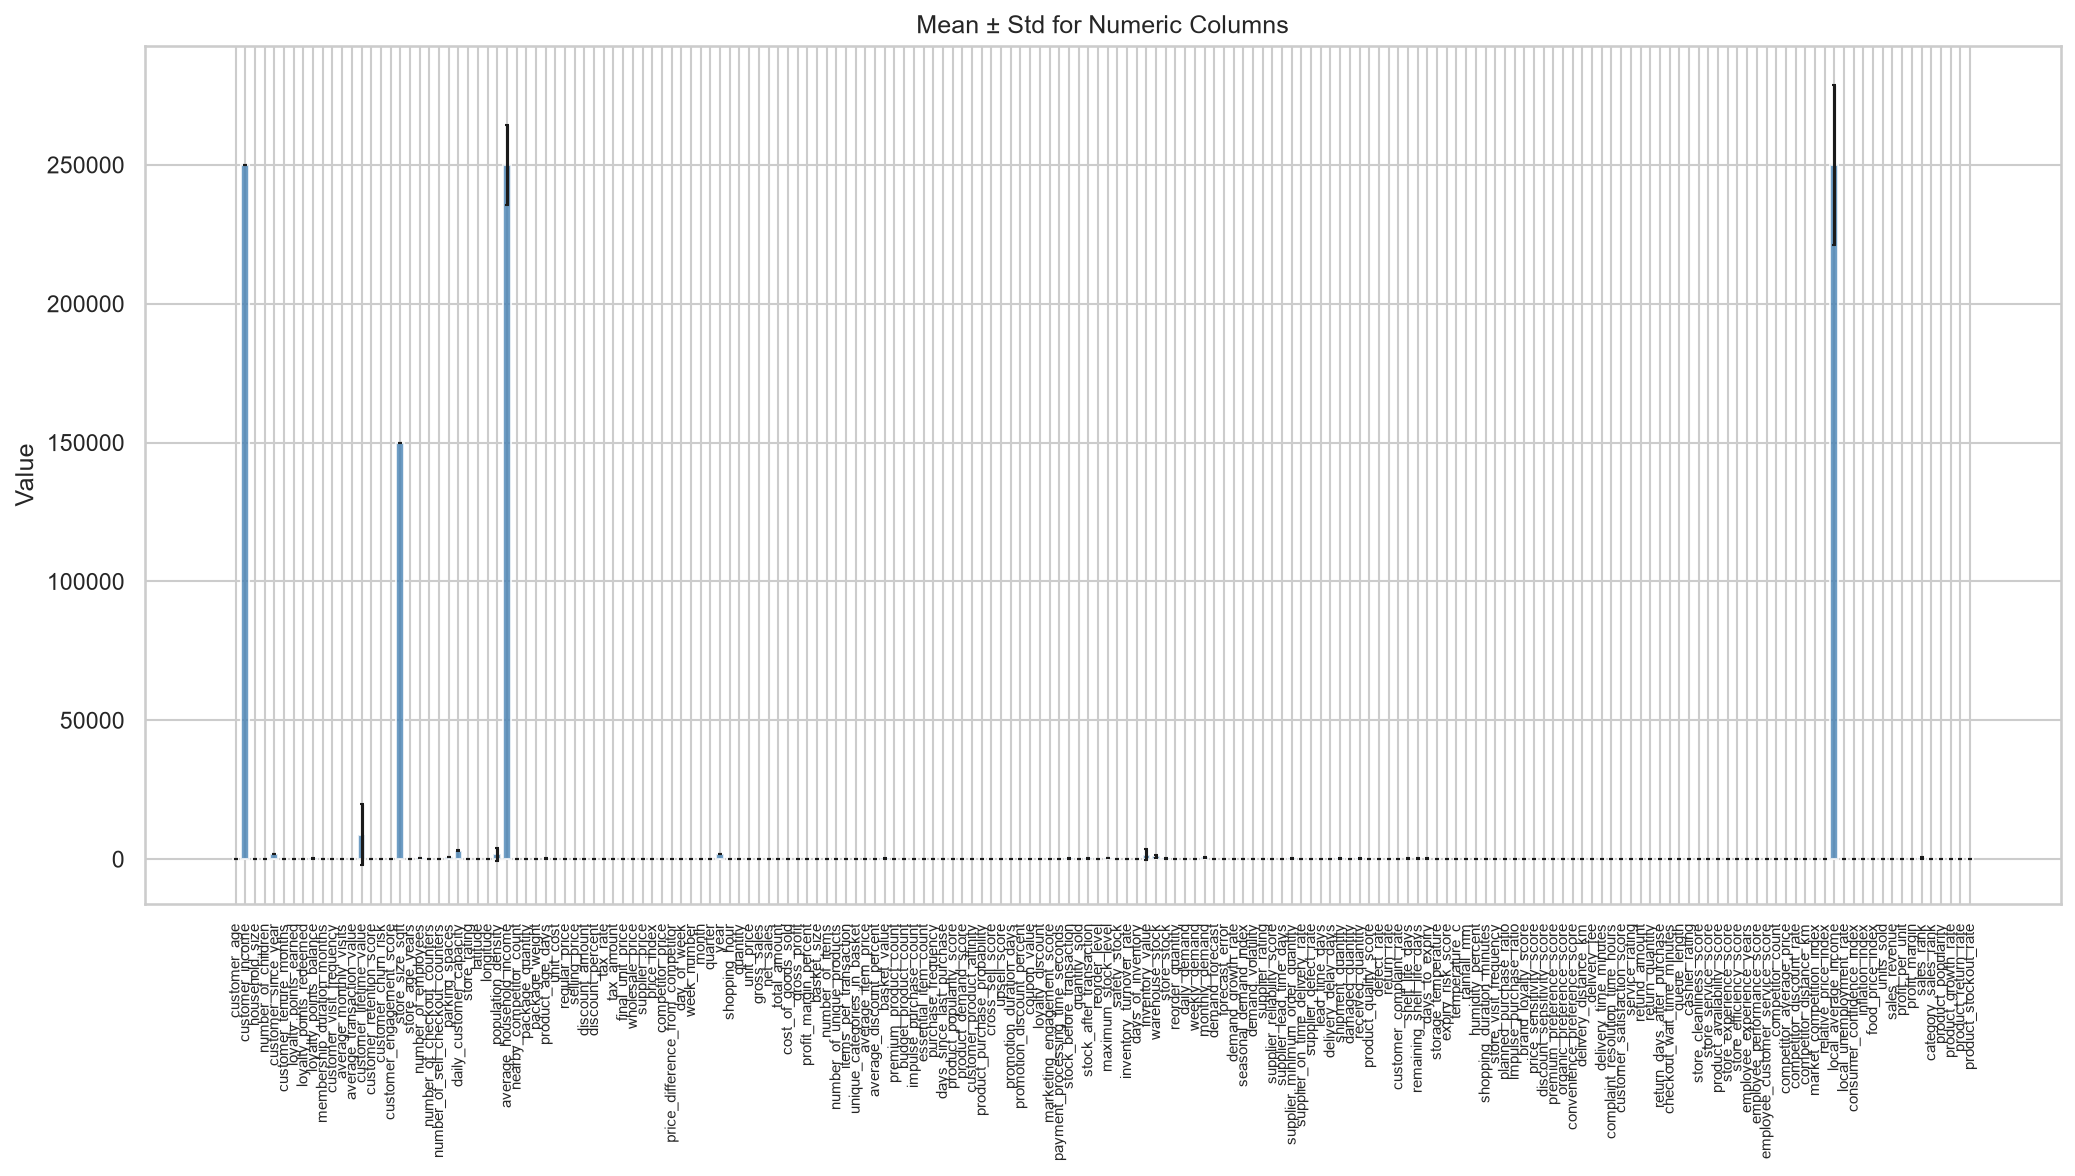

In [190]:
fig, ax = plt.subplots(figsize=(14, 8))
x = np.arange(len(numeric_cols))
ax.bar(x, desc['mean'], yerr=desc['std'], capsize=1, color='steelblue', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(numeric_cols, rotation=90, fontsize=7)
ax.set_ylabel('Value')
ax.set_title('Mean ± Std for Numeric Columns')
plt.tight_layout()
plt.show()

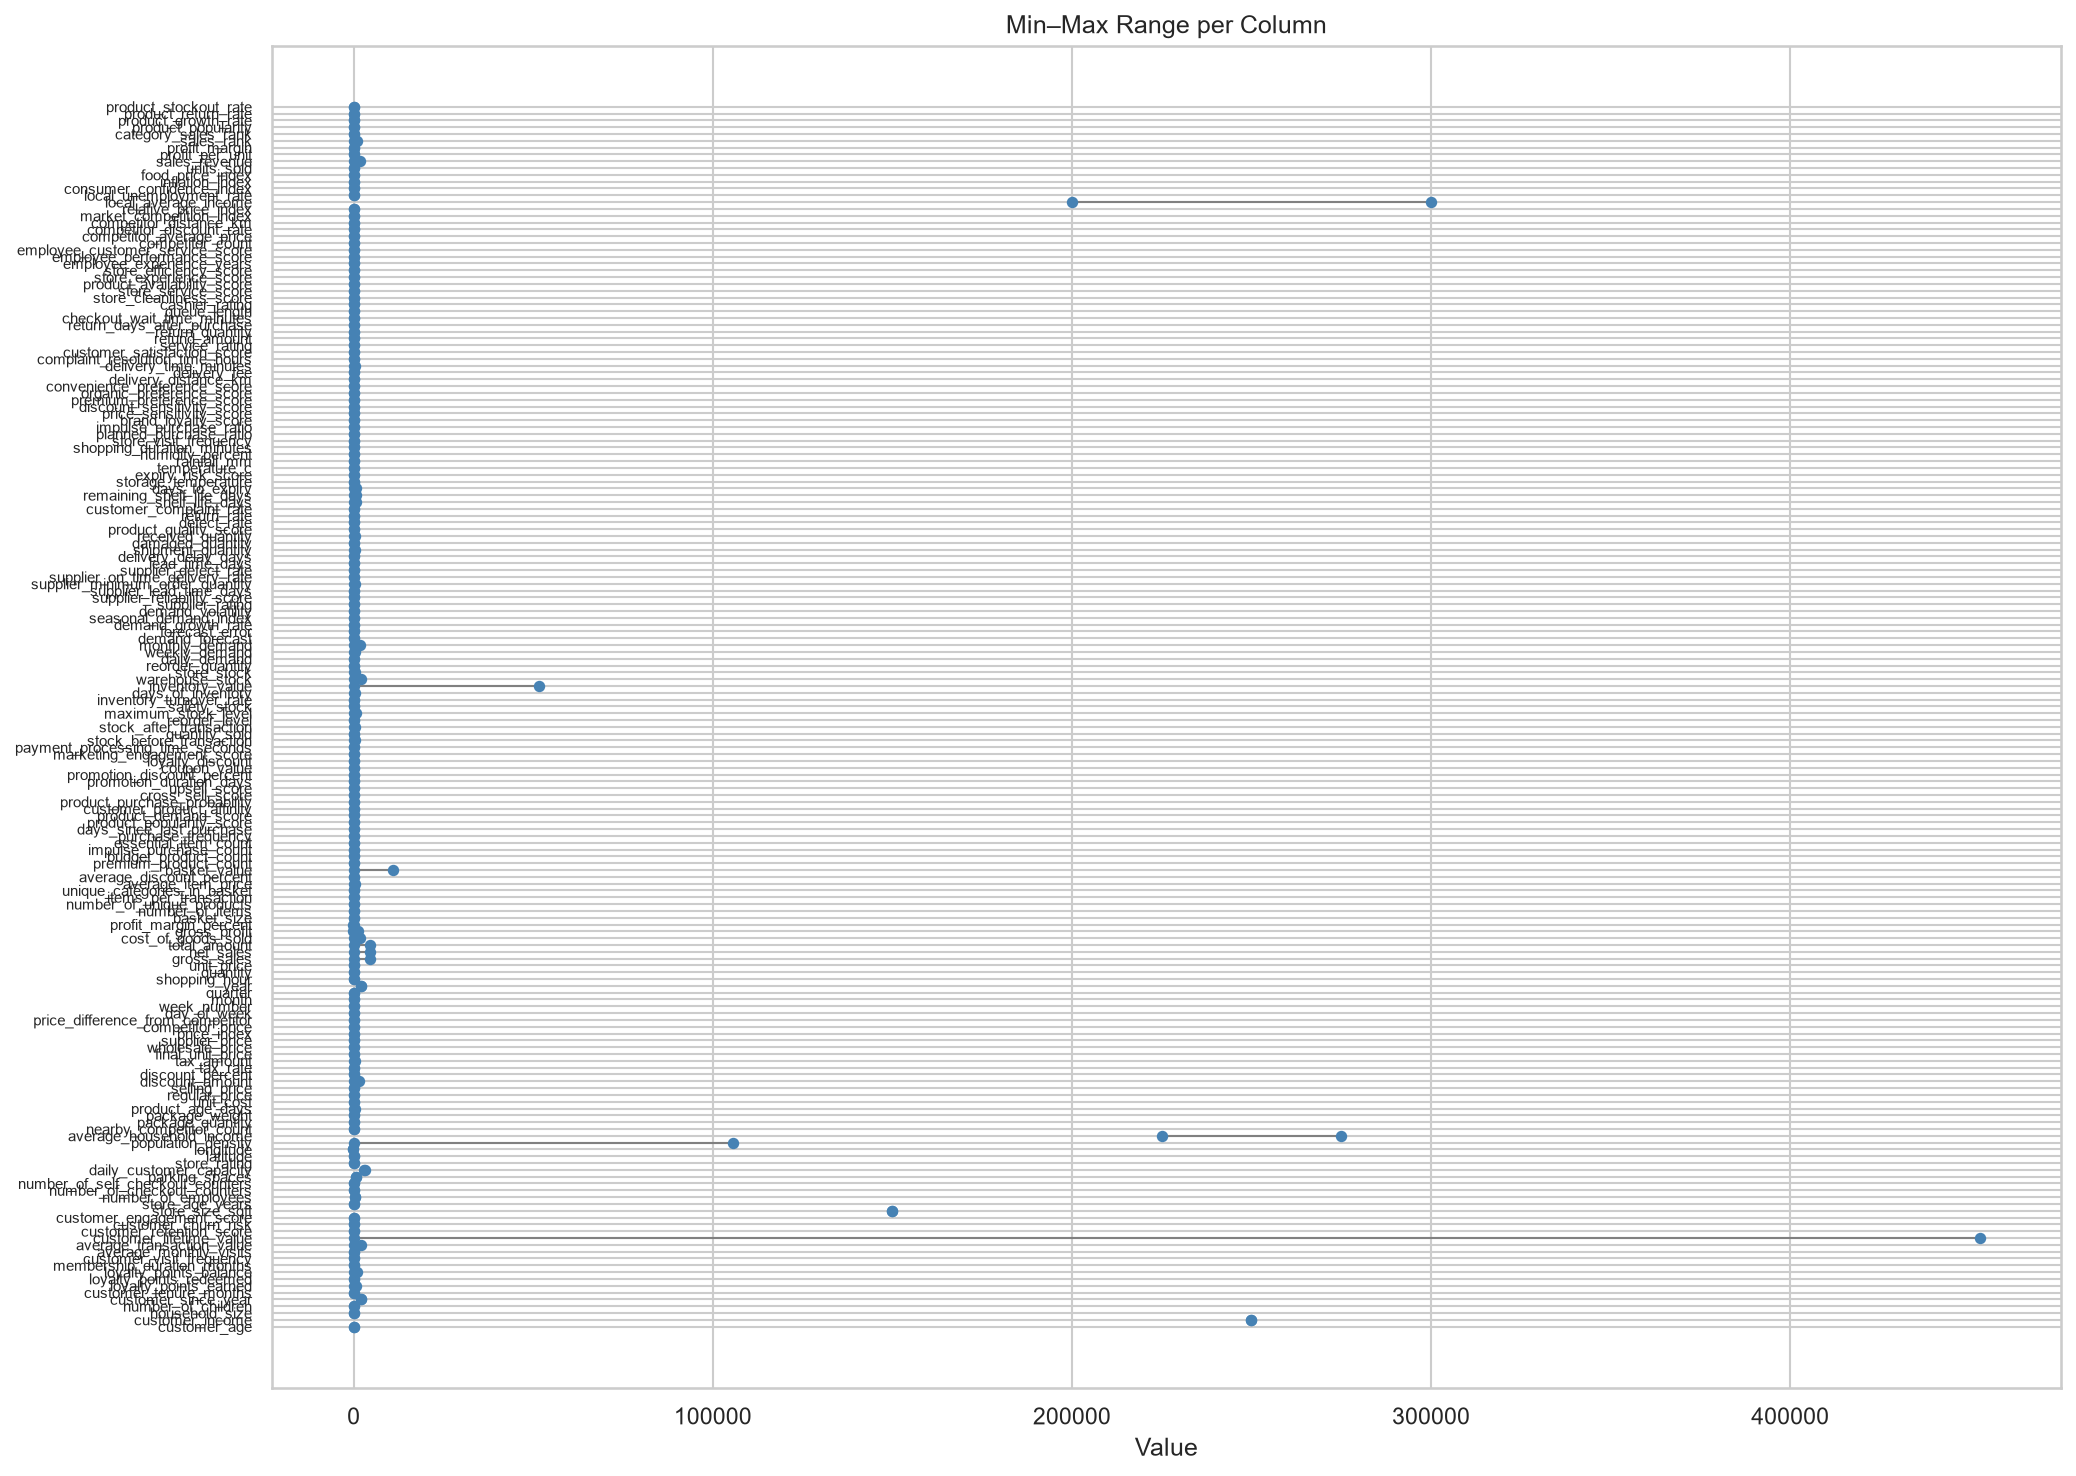

In [191]:
fig, ax = plt.subplots(figsize=(14, 10))
for i, col in enumerate(numeric_cols):
    mn, mx = desc.loc[col, 'min'], desc.loc[col, 'max']
    if mx == mn:
        mx = mn + 0.01
    ax.plot([mn, mx], [i, i], color='gray', linewidth=1)
    ax.scatter([mn, mx], [i, i], color='steelblue', s=20, zorder=3)
ax.set_yticks(range(len(numeric_cols)))
ax.set_yticklabels(numeric_cols, fontsize=7)
ax.set_xlabel('Value')
ax.set_title('Min–Max Range per Column')
plt.tight_layout()
plt.show()

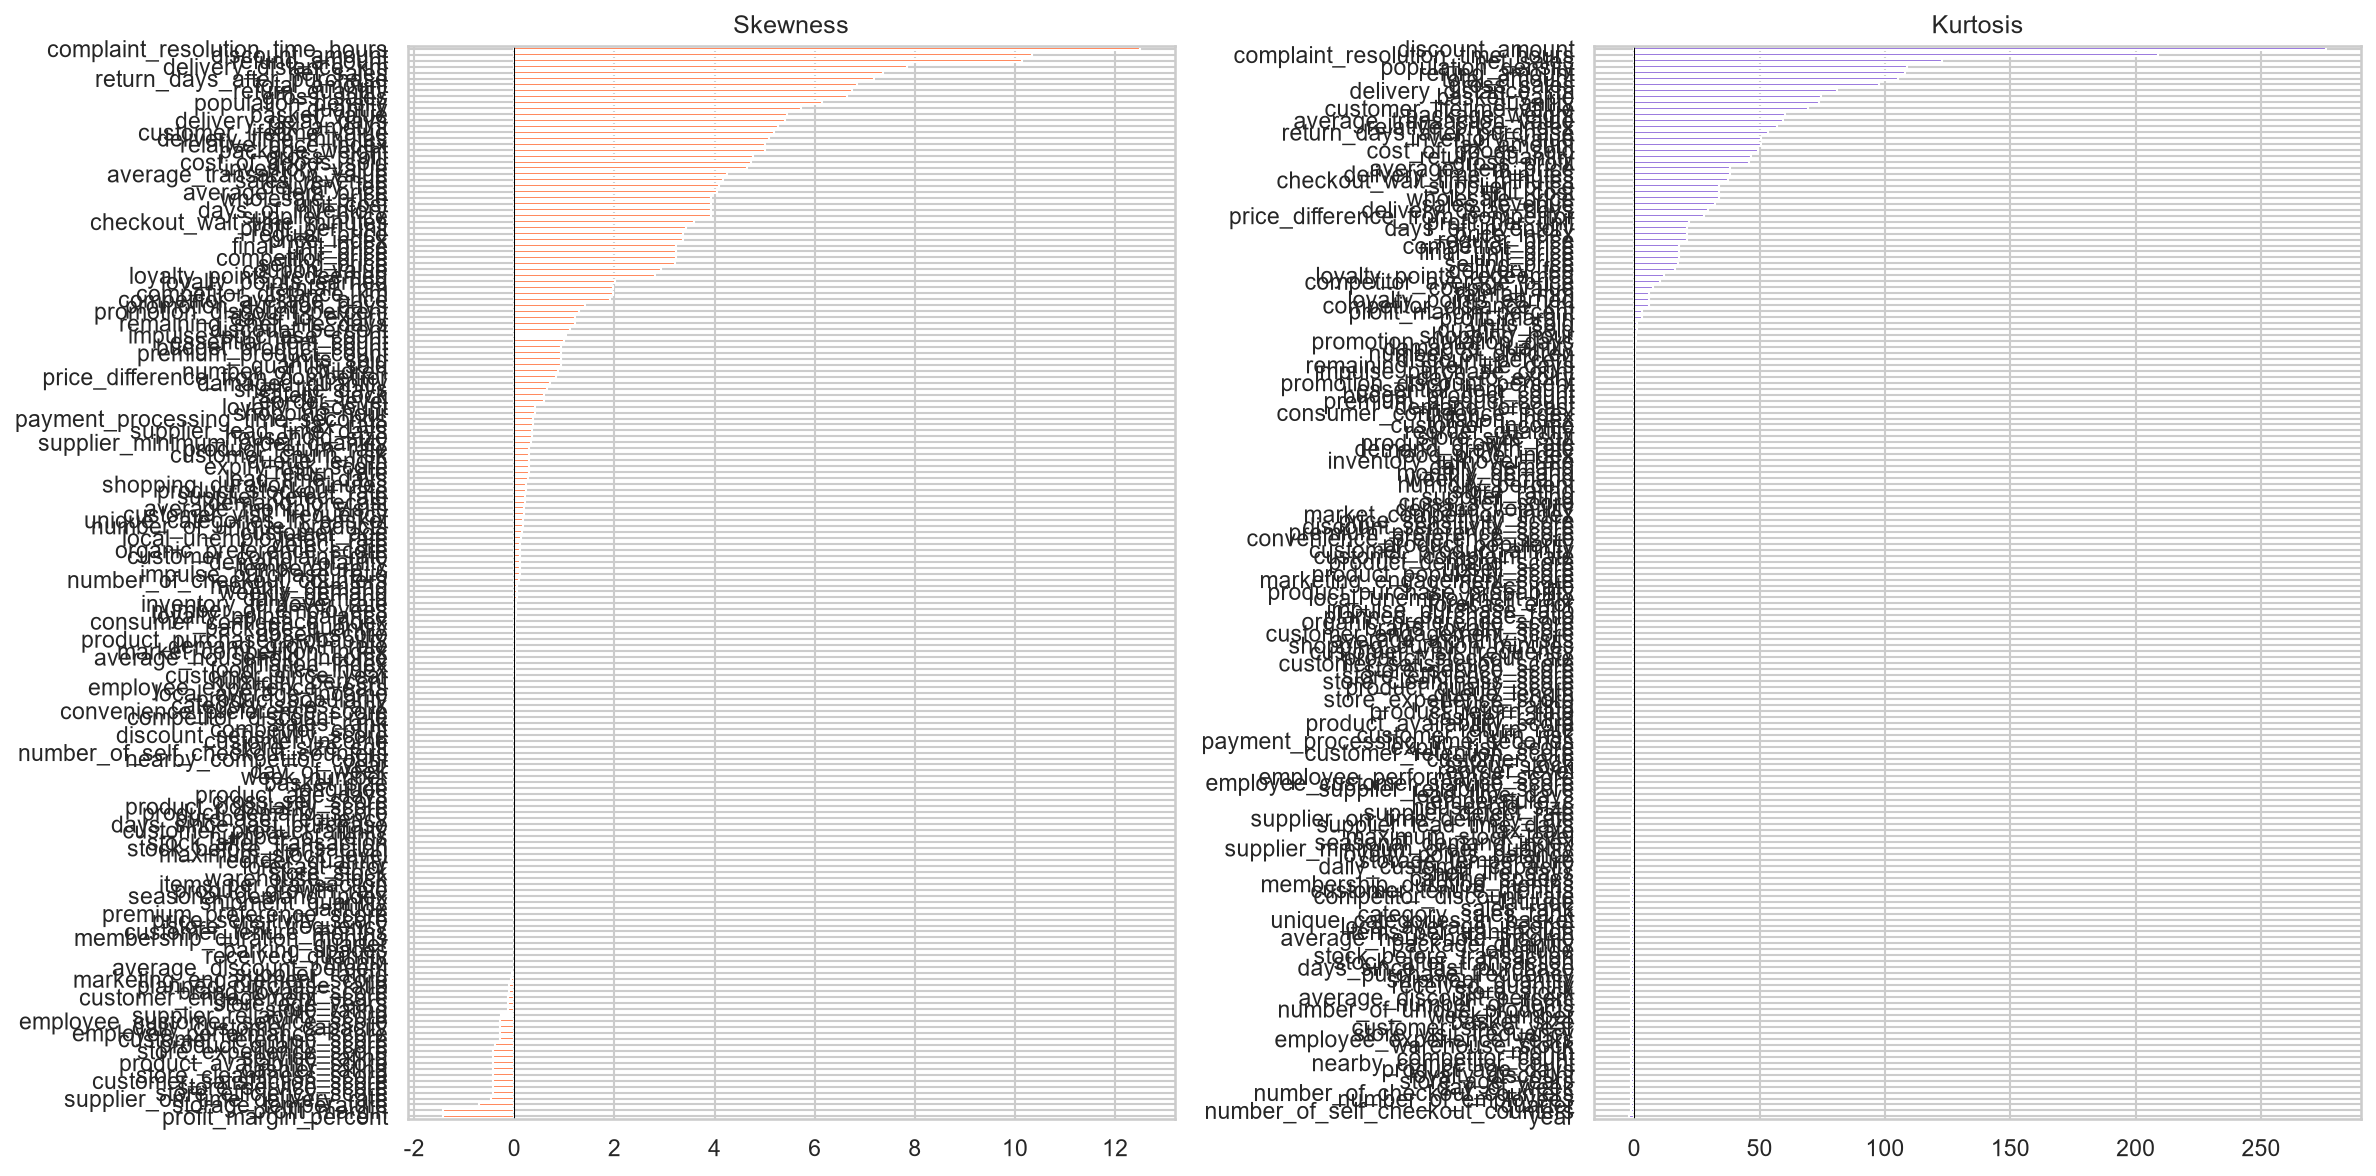

In [194]:
desc['skew'] = df[numeric_cols].skew().round(2)
desc['kurt'] = df[numeric_cols].kurtosis().round(2)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
desc['skew'].sort_values().plot.barh(ax=axes[0], color='coral')
axes[0].set_title('Skewness')
axes[0].axvline(0, color='black', linewidth=0.5)

desc['kurt'].sort_values().plot.barh(ax=axes[1], color='mediumpurple')
axes[1].set_title('Kurtosis')
axes[1].axvline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

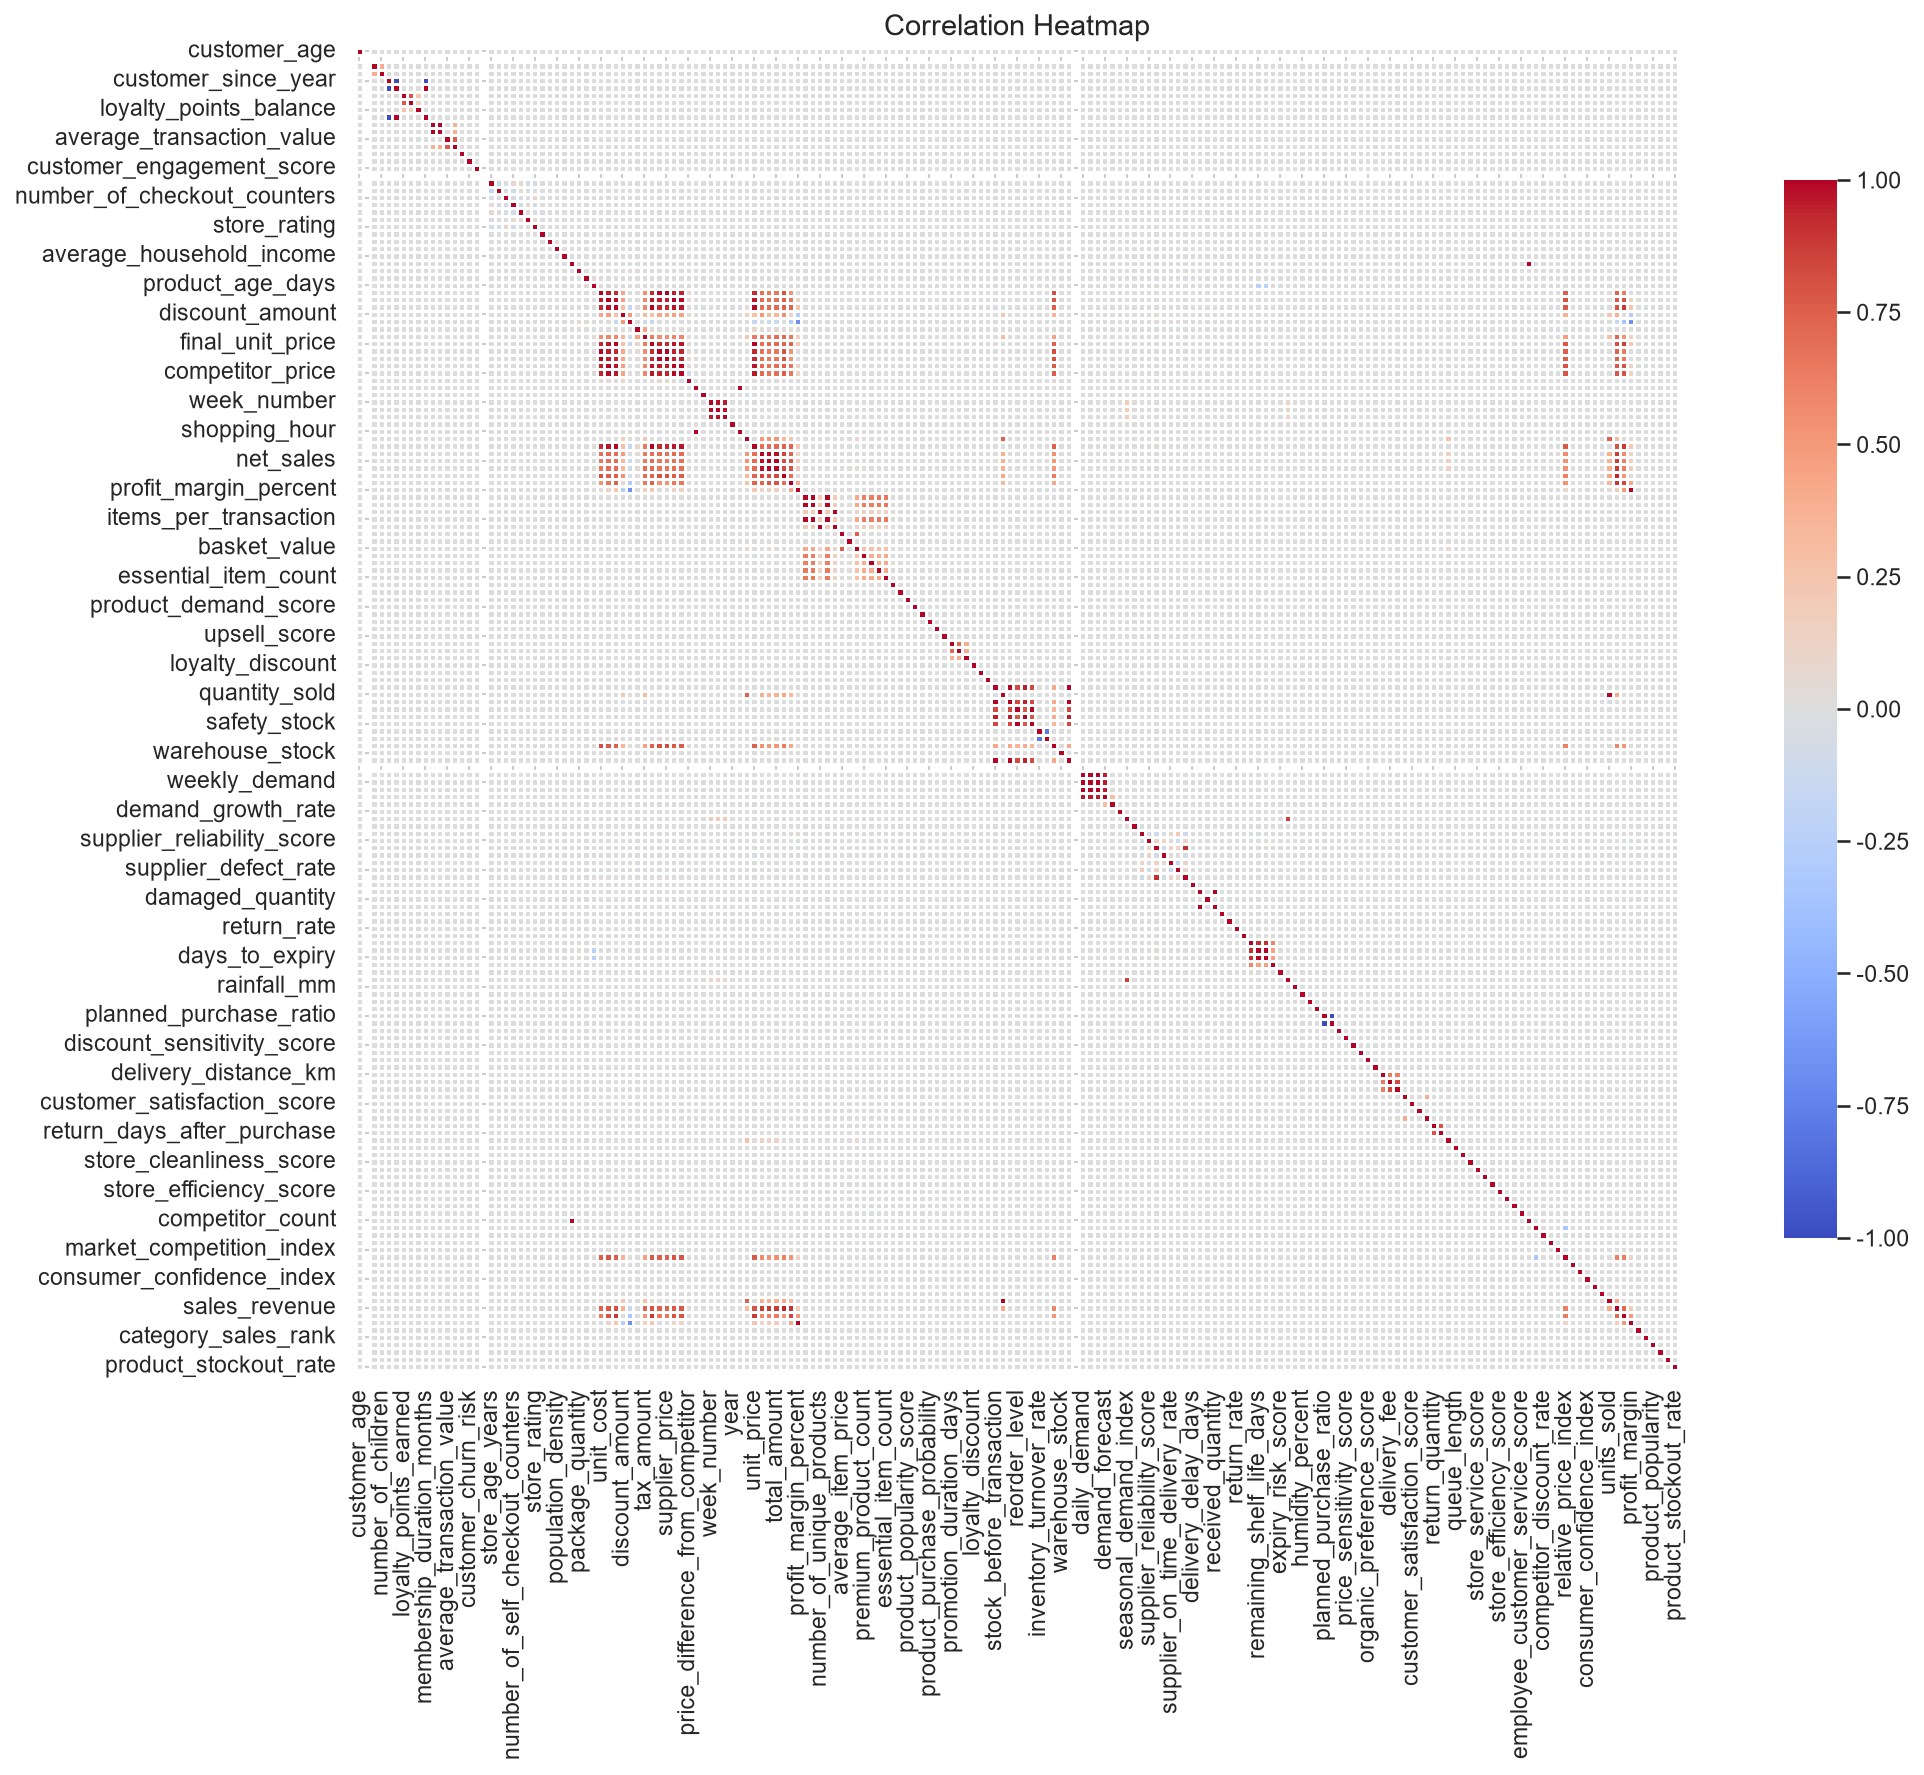

In [112]:
# Correlation matrix
corr = df[numeric_cols].corr()

# Heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap', fontsize=14)
plt.tight_layout()
#plt.savefig('correlation_heatmap.png', dpi=150)
plt.show()

## Categorical column value counts

In [38]:
print('Categorical column distributions (top 5 per column):\n')
categorical_cols = ['customer_gender', 'customer_segment', 'membership_tier', 'payment_method',
                    'product_department', 'store_region', 'store_type', 'season',
                    'sales_channel', 'promotion_active', 'coupon_used', 'is_holiday']
for col in categorical_cols:
    print(f'\n {col} ')
    print(df[col].value_counts().head(5))

Categorical column distributions (top 5 per column):


 customer_gender 
customer_gender
Female    57647
Male      57440
Other      4913
Name: count, dtype: int64

 customer_segment 
customer_segment
Regular Shopper    24079
Family Shopper     21418
Budget Shopper     18009
Loyal Customer     14358
Premium Shopper    12001
Name: count, dtype: int64

 membership_tier 
membership_tier
Bronze      48140
Silver      36011
Gold        23773
Platinum    12076
Name: count, dtype: int64

 payment_method 
payment_method
Credit Card       36166
Debit Card        30042
Cash              23801
Mobile Wallet     18046
Online Payment     5993
Name: count, dtype: int64

 product_department 
product_department
Food                 48259
Beverages            13378
Household            12258
Personal Care         9075
Health & Wellness     6704
Name: count, dtype: int64

 store_region 
store_region
East       30043
South      26599
Central    21679
North      21578
West       20101
Name: count, dtype: i

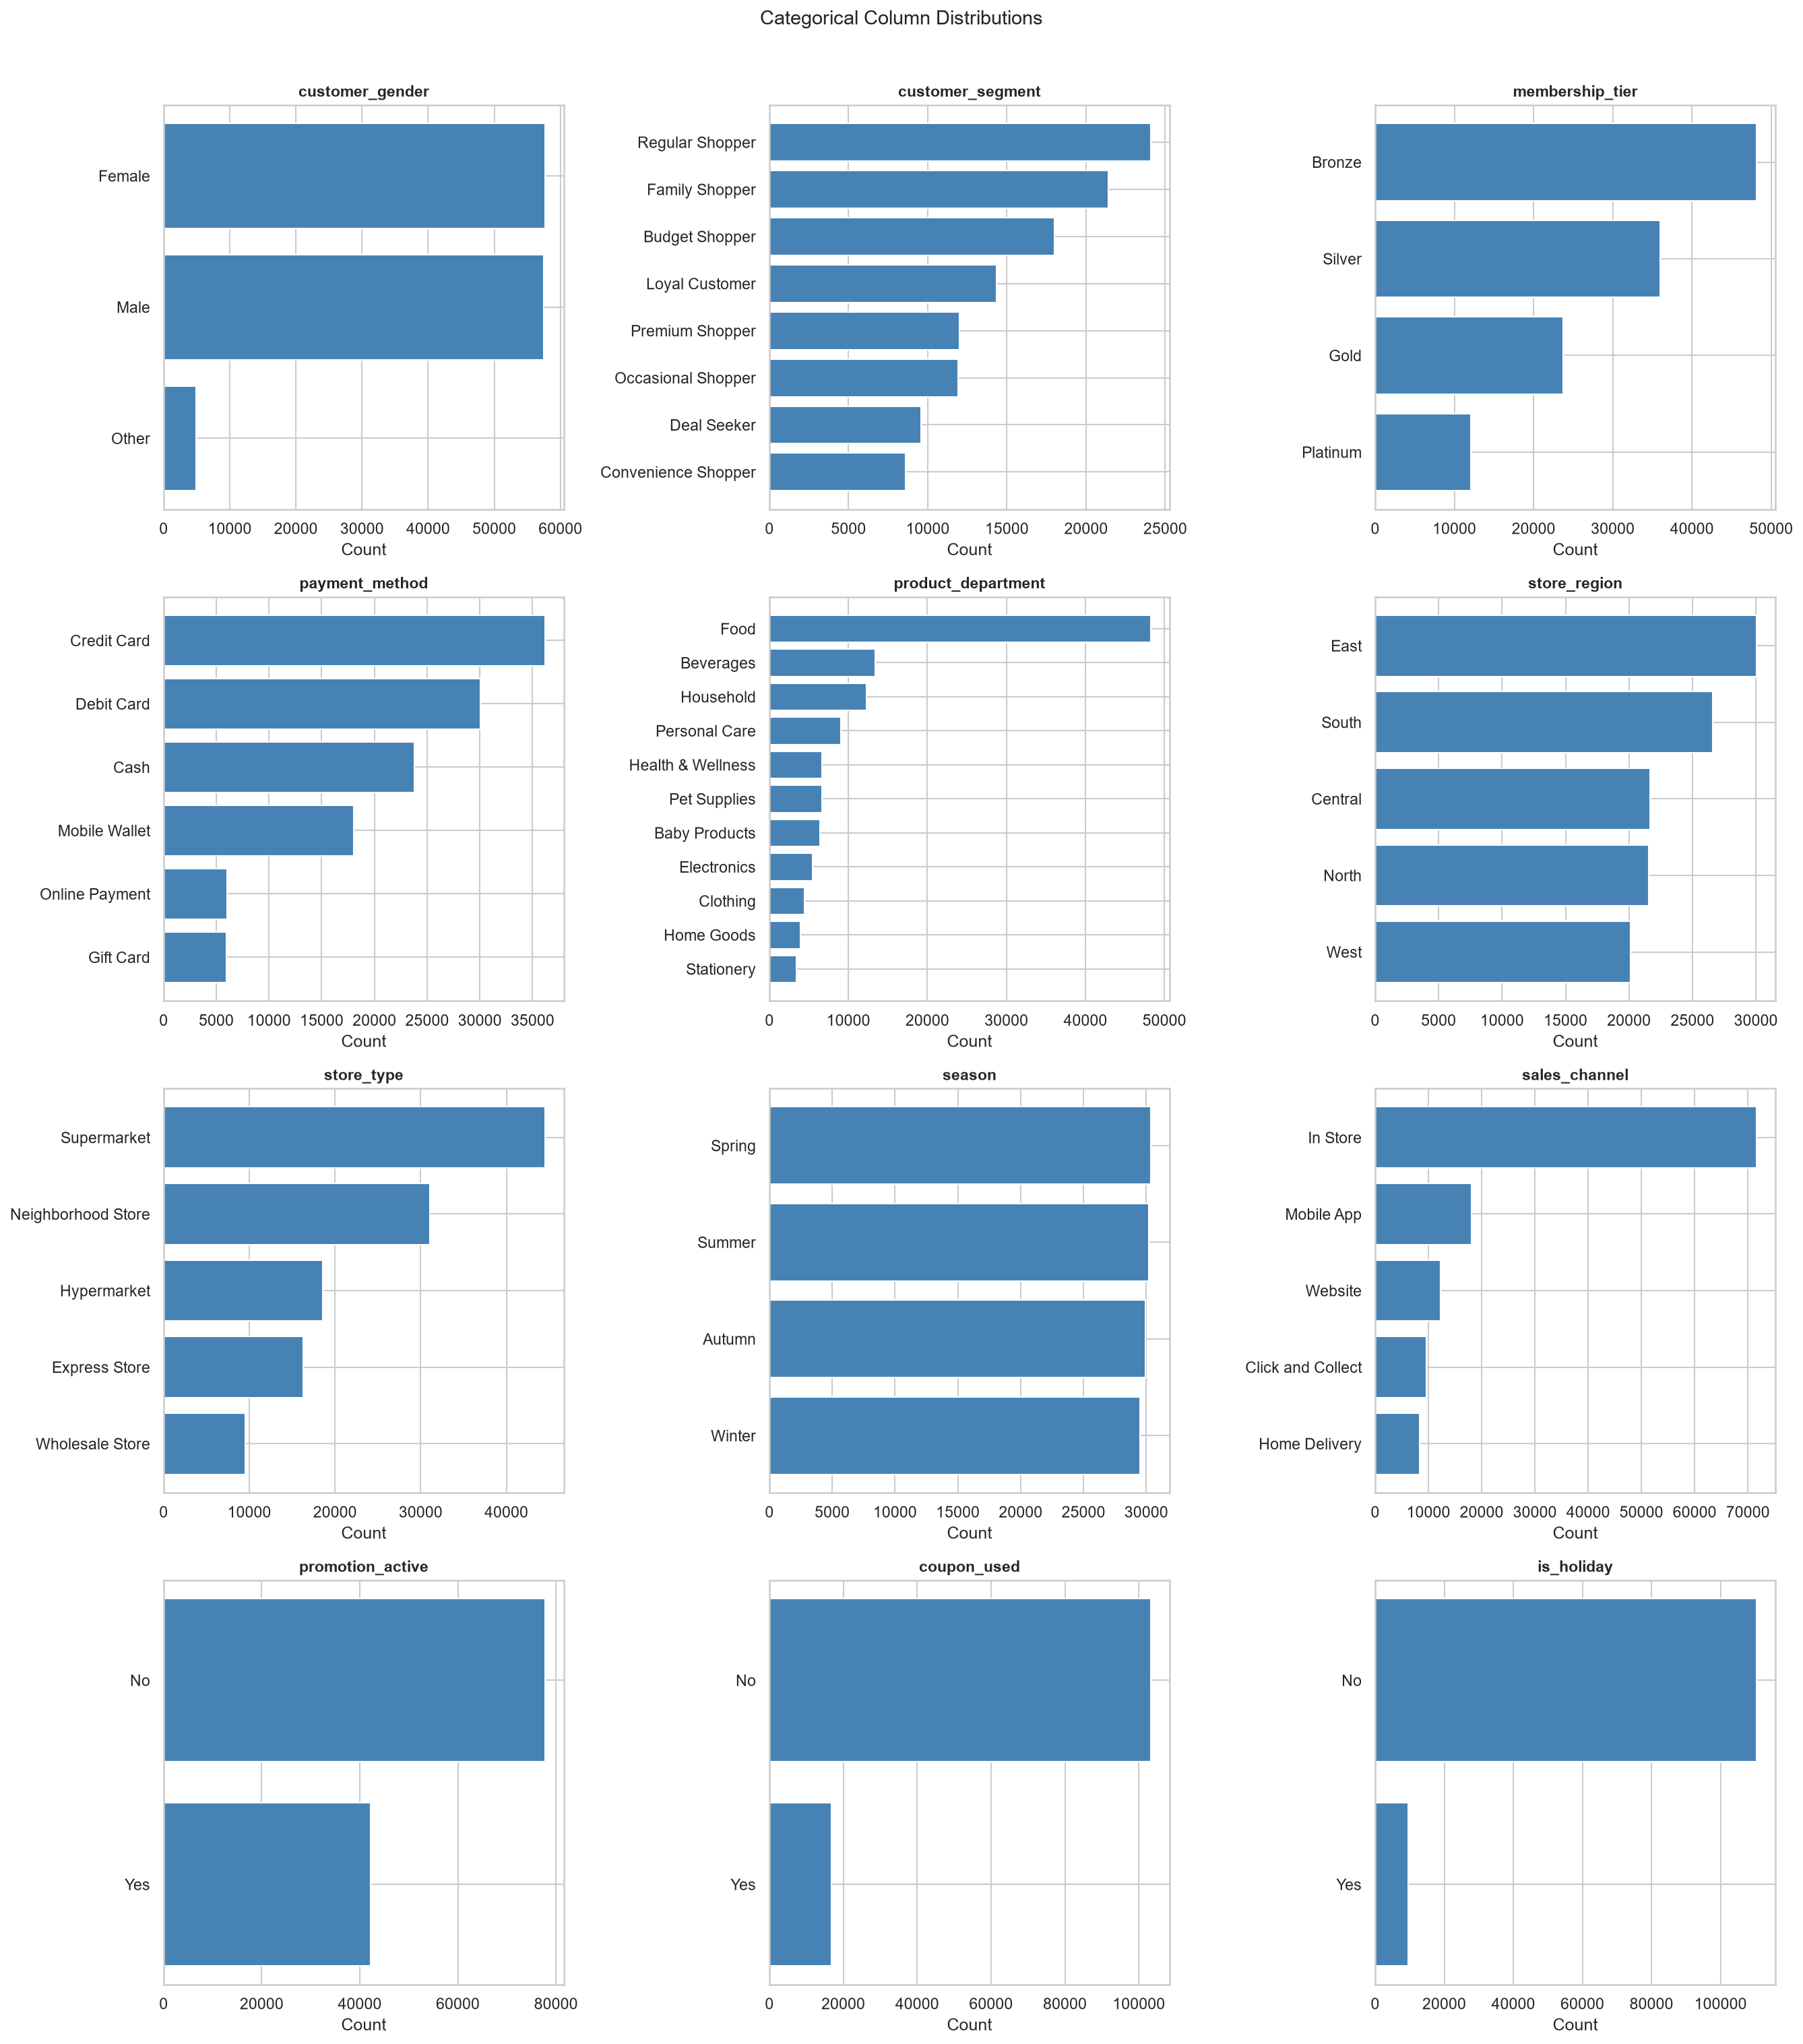

In [113]:
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    counts = df[col].value_counts()
    axes[i].barh(counts.index, counts.values, color='steelblue')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Count')
    axes[i].invert_yaxis()

plt.suptitle('Categorical Column Distributions', fontsize=14, y=1.01)
plt.tight_layout()
#plt.savefig('categorical_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

In [198]:
df_new = df[KEY_COLS].copy()

print(f'✅ {df_new.shape[1]} cols × {df_new.shape[0]} rows')
print(f'💾 Memory: {df_new.memory_usage(deep=True).sum() / 1e6:.1f} MB')   

✅ 102 cols × 120000 rows
💾 Memory: 141.2 MB


In [201]:
df = df_new

In [202]:
df.head()

,transaction_id,basket_id,customer_id,store_id,product_id,customer_age,customer_gender,customer_income,customer_segment,customer_region,...,rainfall_mm,humidity_percent,festival_season,special_event,payday_period,economic_condition,inflation_index,consumer_confidence_index,competitor_count,market_competition_index
0,T00000001,B00044698,C00106069,S00000108,P00003814,60,Female,250000.0,Regular Shopper,South,...,0.3,40.6,No,NaN,Yes,Stable,3.43,87.4,2,0.899
1,T00000002,B00013390,C00027234,S00000154,P00003904,54,Male,250000.0,Regular Shopper,East,...,0.6,64.4,No,NaN,Yes,Weak,2.17,91.6,1,0.376
2,T00000003,B00014357,C00019781,S00000136,P00000650,52,Male,250000.0,Budget Shopper,West,...,0.7,46.6,Yes,NaN,No,Moderate,1.99,99.7,6,0.375
3,T00000004,B00046655,C00018191,S00000169,P00000966,40,Male,250000.0,Convenience Shopper,Central,...,0.4,65.4,No,NaN,No,Moderate,1.94,86.3,0,0.313
4,T00000005,B00046461,C00031493,S00000179,P00000584,44,Female,250000.0,Budget Shopper,Central,...,1.6,50.9,No,NaN,No,Stable,2.61,98.9,4,0.709


## 4️⃣ Data Quality Checks

**What:** A comprehensive 6-dimension data quality audit covering: (1) row count, (2) missing values, (3) duplicates, (4) numeric outliers, (5) categorical consistency, (6) date range validation.  
**Why:** Any business conclusion drawn from bad data is itself bad. Documenting data quality up-front is a non-negotiable professional practice.  
**How:** Use `df.isnull().sum()`, `df.duplicated().sum()`, `df.describe()`, and `df[col].value_counts()`.

> **Result:** The dataset is exceptionally clean. 0 duplicates, only 7 columns with missing values (mostly structurally expected), and all numeric ranges are within plausible retail bounds.

## 4.1 Row & column count

In [203]:
# Dataset dimensions
print(f'    Rows: {len(df):,}')
print(f'    Columns: {len(df.columns)}')

    Rows: 120,000
    Columns: 102


## 4.2 Missing values

In [204]:
# Missing values by column 
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'missing_count': missing,
    'missing_pct': missing_pct
}).sort_values('missing_pct', ascending=False)
missing_df = missing_df[missing_df['missing_count'] > 0]
print(missing_df.to_string())

                             missing_count  missing_pct
return_reason                       116327        96.94
special_event                       101820        84.85
card_type                            53792        44.83
customer_membership_status           12088        10.07
customer_satisfaction_score           3695         3.08
customer_income                       2471         2.06
store_rating                          1243         1.04


## Duplicate rows

In [206]:
print(f'\n Duplicate rows: {df.duplicated().sum()}')


 Duplicate rows: 0


## Numeric statistics for financial fields

In [207]:
financial_cols = ['quantity', 'unit_price', 'gross_sales', 'net_sales', 'total_amount',
                 'cost_of_goods_sold', 'gross_profit', 'profit_margin_percent',
                 'selling_price', 'discount_amount', 'discount_percent']
print(df[financial_cols].describe().round(2).to_string())


        quantity  unit_price  gross_sales  net_sales  total_amount  cost_of_goods_sold  gross_profit  profit_margin_percent  selling_price  discount_amount  discount_percent
count  120000.00   120000.00    120000.00  120000.00     120000.00           120000.00     120000.00              120000.00      120000.00        120000.00         120000.00
mean        8.85       10.63        99.34      87.12         94.09               51.88         31.42                  33.06           9.81            12.22             12.82
std         6.03       10.28       130.15     118.69        126.30               60.17         47.34                  20.42           9.44            26.91             14.19
min         1.00        0.62         1.00       0.52          0.62                0.50       -156.24                 -65.89           0.52             0.00              0.00
25%         5.00        4.27        31.46      26.64         28.80               17.50          6.28                  22.68       

## Negative value checks

In [208]:
for col in ['quantity', 'gross_sales', 'net_sales', 'total_amount', 'gross_profit', 'selling_price']:
    neg = (df[col] < 0).sum()
    zero = (df[col] == 0).sum()
    print(f'    {col:25s}  negative={neg:6d}  zero={zero:6d}')


    quantity                   negative=     0  zero=     0
    gross_sales                negative=     0  zero=     0
    net_sales                  negative=     0  zero=     0
    total_amount               negative=     0  zero=     0
    gross_profit               negative=  7651  zero=   156
    selling_price              negative=     0  zero=     0


## Date range

In [209]:
print(f'    Min date: {df["transaction_date"].min()}')
print(f'    Max date: {df["transaction_date"].max()}')
print(f'    Total days: {(df["transaction_date"].max() - df["transaction_date"].min()).days}')

    Min date: 2023-01-01 00:00:00
    Max date: 2024-12-30 00:00:00
    Total days: 729


In [212]:
quality_summary = {
    'total_rows': int(len(df)),
    'total_columns': int(len(df.columns)),
    'date_min': str(df['transaction_date'].min()),
    'date_max': str(df['transaction_date'].max()),
    'unique_stores': int(df['store_id'].nunique()),
    'unique_customers': int(df['customer_id'].nunique()),
    'unique_products': int(df['product_id'].nunique()),
    'unique_transactions': int(df['transaction_id'].nunique()),
    'duplicates': int(df.duplicated().sum()),
    'missing_pct_avg': float(missing_pct.mean()),
    'cols_with_missing': int(len(missing_df)),
}
with open('kpi/quality_summary.json', 'w') as f:
    json.dump(quality_summary, f, indent=2)

In [213]:
quality_summary

{'total_rows': 120000,
 'total_columns': 102,
 'date_min': '2023-01-01 00:00:00',
 'date_max': '2024-12-30 00:00:00',
 'unique_stores': 200,
 'unique_customers': 75799,
 'unique_products': 5000,
 'unique_transactions': 120000,
 'duplicates': 0,
 'missing_pct_avg': 2.3810784313725493,
 'cols_with_missing': 7}

## 5️⃣ Data Cleaning & Preprocessing

**What:** Apply the cleaning rules identified in the previous step.  
**Why:** The data is already very clean, but we make a few adjustments to ensure downstream analysis is robust:  
1. Confirm `transaction_date` is a proper datetime type.  
2. Treat missing categorical values as the literal `'Missing'` category (transparent, no imputation).  
3. Handle the negative `gross_profit` rows by retaining them (they are legitimate deep-discount transactions, not errors).  
4. Engineer derived time features (year, month, day_of_week_name) for time-based analysis.

**How:** Use `pd.to_datetime()`, `fillna('Missing')`, and `dt` accessors.

In [214]:
df_clean = df.copy()
print(f'Original df shape: {df_clean.shape}')

Original df shape: (120000, 102)


### Rule 1: Confirm transaction_date is datetime

In [217]:
df_clean['transaction_date'] = pd.to_datetime(df_clean['transaction_date'])
df_clean.head()

,transaction_id,basket_id,customer_id,store_id,product_id,customer_age,customer_gender,customer_income,customer_segment,customer_region,...,rainfall_mm,humidity_percent,festival_season,special_event,payday_period,economic_condition,inflation_index,consumer_confidence_index,competitor_count,market_competition_index
0,T00000001,B00044698,C00106069,S00000108,P00003814,60,Female,250000.0,Regular Shopper,South,...,0.3,40.6,No,NaN,Yes,Stable,3.43,87.4,2,0.899
1,T00000002,B00013390,C00027234,S00000154,P00003904,54,Male,250000.0,Regular Shopper,East,...,0.6,64.4,No,NaN,Yes,Weak,2.17,91.6,1,0.376
2,T00000003,B00014357,C00019781,S00000136,P00000650,52,Male,250000.0,Budget Shopper,West,...,0.7,46.6,Yes,NaN,No,Moderate,1.99,99.7,6,0.375
3,T00000004,B00046655,C00018191,S00000169,P00000966,40,Male,250000.0,Convenience Shopper,Central,...,0.4,65.4,No,NaN,No,Moderate,1.94,86.3,0,0.313
4,T00000005,B00046461,C00031493,S00000179,P00000584,44,Female,250000.0,Budget Shopper,Central,...,1.6,50.9,No,NaN,No,Stable,2.61,98.9,4,0.709


In [218]:
df_clean['transaction_date'].head()

0   2023-07-01
1   2023-05-15
2   2023-12-13
3   2023-02-14
4   2023-06-25
Name: transaction_date, dtype: datetime64[us]

### Rule 2: Fill missing categorical values with 'Missing'

In [219]:
categorical_cols_to_fill = ['card_type', 'customer_membership_status', 'customer_satisfaction_score',
                            'customer_income', 'store_rating', 'return_reason', 'special_event']
for col in categorical_cols_to_fill:
    if col in df_clean.columns:
        missing_before = df_clean[col].isnull().sum()
        df_clean[col] = df_clean[col].fillna('Missing').astype(str)
        if missing_before > 0:
            print(f'Filled {missing_before:,} missing values in {col}')


Filled 53,792 missing values in card_type
Filled 12,088 missing values in customer_membership_status
Filled 3,695 missing values in customer_satisfaction_score
Filled 2,471 missing values in customer_income
Filled 1,243 missing values in store_rating
Filled 116,327 missing values in return_reason
Filled 101,820 missing values in special_event


### Rule 3: Retain negative gross_profit (legitimate deep-discount transactions)

In [221]:
neg_profit_count = (df_clean['gross_profit'] < 0).sum()
print(f'Retained {neg_profit_count:,} negative-gross-profit transactions (legitimate)')


Retained 7,651 negative-gross-profit transactions (legitimate)


### Rule 4: Engineer derived time features

In [222]:
df_clean['year'] = df_clean['transaction_date'].dt.year
df_clean['year_month'] = df_clean['transaction_date'].dt.to_period('M')
df_clean['day_name_calc'] = df_clean['transaction_date'].dt.day_name()
df_clean['is_weekend_calc'] = df_clean['day_name_calc'].isin(['Saturday', 'Sunday'])
print(f'Engineered: year, year_month, day_name_calc, is_weekend_calc')


Engineered: year, year_month, day_name_calc, is_weekend_calc


### Replace the working df

In [223]:
df = df_clean
print(f'\n Final cleaned df shape: {df.shape}')
print(f' Memory: {df.memory_usage(deep=True).sum() / (1024*1024):.1f} MB')



 Final cleaned df shape: (120000, 105)
 Memory: 140.5 MB


## 6️⃣ Core KPI Computation

**What:** Calculate the headline business metrics that anchor every subsequent analysis.  
**Why:** KPIs provide the baseline against which every comparison, attribution, and recommendation is measured. Without them, downstream analysis is unanchored.  
**How:** Use `df[col].sum()`, `.nunique()`, `.mean()`, and simple division.

| KPI | Formula | Value |
|-----|---------|-------|
| Total Revenue | `Σ total_amount` | $11.29M |
| Total Profit | `Σ gross_profit` | $3.77M |
| Profit Margin | `Profit / Revenue × 100` | 33.39% |
| AOV | `Revenue / Transactions` | $94.09 |
| Items Sold | `Σ quantity` | ~1.06M |
| Return Rate | `(return_flag == Yes) / Total × 100` | 3.06% |

### 6.1 Compute all KPIs

In [239]:
total_revenue = df['total_amount'].sum()
print(f"Total Revenue ${total_revenue.round(2)}")

Total Revenue $11290659.33


In [240]:
total_profit = df['gross_profit'].sum()
print(f"Total Profit is ${total_profit}")

Total Profit is $3770441.83


In [242]:
total_cogs = df['cost_of_goods_sold'].sum()
print(f"Total cost of goods sold ${total_cogs}")

Total cost of goods sold $6225202.75


In [245]:
n_transactions = df['transaction_id'].nunique()
print(f"No of Transactions of all payments {n_transactions}")

No of Transactions of all payments 120000


In [249]:
n_customers = df['customer_id'].nunique()
print(f"No of Unique Customers {n_customers}")

No of Unique Customers 75799


In [247]:
n_stores = df['store_id'].nunique()
print(f"No of unique store {n_stores}")

No of unique store 200


In [248]:
n_products = df['product_id'].nunique()
print(f"No of unique Products {n_products}")

No of unique Products 5000


In [250]:
total_items_sold = df['quantity'].sum()
print(f"Total Items solds {total_items_sold}")

Total Items solds 1061870


In [252]:
avg_basket_value = df['total_amount'].mean()
print(f"Average Basket Value ${avg_basket_value.round()}")

Average Basket Value $94.0


In [254]:
avg_profit_margin = (total_profit / total_revenue) * 100
print(f"Average Profit Margin ${avg_profit_margin.round()}")

Average Profit Margin $33.0


### 6.2 Return & satisfaction

In [257]:
return_rate = (df['return_flag'].fillna('No') == 'Yes').mean() * 100
print(f"Average Return rate {return_rate.round()}")

Average Return rate 3.0


In [261]:
df['customer_satisfaction_score'].head()

0    4.1
1    4.3
2    4.2
3    4.9
4    4.5
Name: customer_satisfaction_score, dtype: str

In [265]:
df['customer_satisfaction_score'] = pd.to_numeric(df['customer_satisfaction_score'], errors='coerce')

In [267]:
avg_satisfaction = df['customer_satisfaction_score'].mean()
print(f"Average Satisfaction Score {avg_satisfaction.round()}")

Average Satisfaction Score 4.0


### Average Customer Satisfaction Score 4.0

In [269]:
avg_service_rating = df['service_rating'].mean()
print(f"average Service rating {avg_service_rating.round()}")

average Service rating 4.0


### 6.3 Discount stats

In [271]:
avg_discount_pct = df['discount_percent'].mean()
print(f"Average Discount Percentage {avg_discount_pct.round(1)}%")

Average Discount Percentage 12.8%


In [272]:
promotion_active_pct = (df['promotion_active'].astype(str).str.lower() == 'yes').mean() * 100
print(f"Active Promotion Percentage {promotion_active_pct.round(1)}% ")

Active Promotion Percentage 35.2% 


In [274]:
coupon_usage_pct = (df['coupon_used'].astype(str).str.lower() == 'yes').mean() * 100
print(f"Coupon used {coupon_usage_pct.round()}%")

Coupon used 14.0%


### 6.4 Channel mix

In [283]:
print(df['sales_channel'].unique())   

<ArrowStringArray>
['Mobile App', 'In Store', 'Click and Collect', 'Website', 'Home Delivery']
Length: 5, dtype: str


In [284]:
online_channels = ['Mobile App', 'Website', 'Click and Collect', 'Home Delivery']

In [287]:
online_mask = df['sales_channel'].isin(online_channels)

In [289]:
online_revenue_share = df.loc[online_mask, 'total_amount'].sum() / total_revenue * 100
print(f"Online Revenue Share {online_revenue_share.round(1)}")

Online Revenue Share 40.2


In [291]:
in_store_share = 100 - online_revenue_share
print(f"In Store Share {in_store_share.round(1)}")

In Store Share 59.8


In [293]:
weekend_rev_share = df.loc[df['is_weekend_calc'], 'total_amount'].sum() / total_revenue * 100
print(f"Weekend Revenue Share {weekend_rev_share.round(1)}")

Weekend Revenue Share 28.5


### 6.5 Year On Year

In [294]:
yearly = df.groupby(df['transaction_date'].dt.year).agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique')
)

In [297]:
yoy_revenue_growth = ((yearly.loc[2024, 'revenue'] - yearly.loc[2023, 'revenue'])
                       / yearly.loc[2023, 'revenue'] * 100)
print(f"Year on Year Revenue Growth {yoy_revenue_growth.round(2)}")

Year on Year Revenue Growth 0.13


In [298]:
yoy_profit_growth = ((yearly.loc[2024, 'profit'] - yearly.loc[2023, 'profit'])
                      / yearly.loc[2023, 'profit'] * 100)
print(f"Year on Year Profit Growth {yoy_profit_growth.round(2)}")

Year on Year Profit Growth 0.19


In [300]:
yoy_txn_growth = ((yearly.loc[2024, 'transactions'] - yearly.loc[2023, 'transactions'])
                   / yearly.loc[2023, 'transactions'] * 100)
print(f"Year on Year Transactions Growth {yoy_txn_growth.round(2)}")

Year on Year Transactions Growth -0.15


In [302]:
print(f'Total Revenue:           ${total_revenue:>15,.2f}')
print(f'Total Gross Profit:      ${total_profit:>15,.2f}')
print(f'Profit Margin:            {avg_profit_margin:>14.2f}%')
print(f'Total Transactions:       {n_transactions:>14,}')
print(f'Unique Customers:         {n_customers:>14,}')
print(f'Total Items Sold:         {total_items_sold:>14,}')
print(f'Avg Order Value (AOV):   ${avg_basket_value:>13.2f}')
print(f'Return Rate:              {return_rate:>14.2f}%')
print(f'Avg Satisfaction:         {avg_satisfaction:>14.2f} / 5.00')
print(f'Avg Service Rating:       {avg_service_rating:>14.2f} / 5.00')
print(f'Avg Discount %:           {avg_discount_pct:>14.2f}%')
print(f'Promotion Active:         {promotion_active_pct:>14.2f}%')
print(f'Coupon Usage:             {coupon_usage_pct:>14.2f}%')
print(f'Online Revenue Share:     {online_revenue_share:>14.2f}%')
print(f'In-Store Share:           {in_store_share:>14.2f}%')
print(f'Weekend Revenue Share:    {weekend_rev_share:>14.2f}%')
print(f'YoY Revenue Growth:       {yoy_revenue_growth:>+14.2f}%')
print(f'YoY Profit Growth:        {yoy_profit_growth:>+14.2f}%')
print(f'YoY Transaction:          {yoy_txn_growth:>+14.2f}%')

Total Revenue:           $  11,290,659.33
Total Gross Profit:      $   3,770,441.83
Profit Margin:                     33.39%
Total Transactions:              120,000
Unique Customers:                 75,799
Total Items Sold:              1,061,870
Avg Order Value (AOV):   $        94.09
Return Rate:                        3.06%
Avg Satisfaction:                   3.96 / 5.00
Avg Service Rating:                 3.96 / 5.00
Avg Discount %:                    12.82%
Promotion Active:                  35.22%
Coupon Usage:                      14.01%
Online Revenue Share:              40.21%
In-Store Share:                    59.79%
Weekend Revenue Share:             28.46%
YoY Revenue Growth:                +0.13%
YoY Profit Growth:                 +0.19%
YoY Transaction:                   -0.15%


In [303]:
kpis = {
    'total_revenue': float(total_revenue),
    'total_profit': float(total_profit),
    'total_cogs': float(total_cogs),
    'n_transactions': int(n_transactions),
    'n_customers': int(n_customers),
    'n_stores': int(n_stores),
    'n_products': int(n_products),
    'total_items_sold': int(total_items_sold),
    'avg_basket_value': float(avg_basket_value),
    'avg_profit_margin_pct': float(avg_profit_margin),
    'date_start': str(df['transaction_date'].min().date()),
    'date_end': str(df['transaction_date'].max().date()),
}
extras = {
    'return_rate_pct': float(return_rate),
    'avg_satisfaction': float(avg_satisfaction),
    'avg_service_rating': float(avg_service_rating),
    'avg_discount_pct': float(avg_discount_pct),
    'promotion_active_pct': float(promotion_active_pct),
    'coupon_usage_pct': float(coupon_usage_pct),
    'online_revenue_share_pct': float(online_revenue_share),
    'in_store_revenue_share_pct': float(in_store_share),
    'weekend_revenue_share_pct': float(weekend_rev_share),
    'yoy_revenue_growth_pct': float(yoy_revenue_growth),
    'yoy_profit_growth_pct': float(yoy_profit_growth),
    'yoy_txn_growth_pct': float(yoy_txn_growth),
}

with open('kpi/kpis.json', 'w') as f:
    json.dump(kpis, f, indent=2)

with open('kpi/extras.json', 'w') as f:
    json.dump(extras, f, indent=2)

print("Done")

Done


## 7️⃣ Core Performance Visualizations

**What:** Generate the first four foundational charts:  
1. Monthly Revenue & Profit Trend (dual-axis area + line)  
2. Revenue by Region (bar chart with share %)  
3. Top 10 Product Categories (horizontal bar)  
4. Revenue Share by Product Department (donut chart)

**Why:** These charts establish the *baseline* — what the business looks like in aggregate, where it's geographically concentrated, and what categories dominate the product mix.

**How:** Use `matplotlib.pyplot` and `seaborn`. All charts saved as PNG at 150 DPI to `charts/`.

### 7.1 CHART 1: Monthly Revenue & Profit Trend

In [304]:
monthly = df.groupby(df['transaction_date'].dt.to_period('M')).agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index()

In [305]:
monthly['date'] = monthly['transaction_date'].dt.to_timestamp()

In [306]:
monthly['revenue_k'] = monthly['revenue'] / 1000
monthly['profit_k'] = monthly['profit'] / 1000

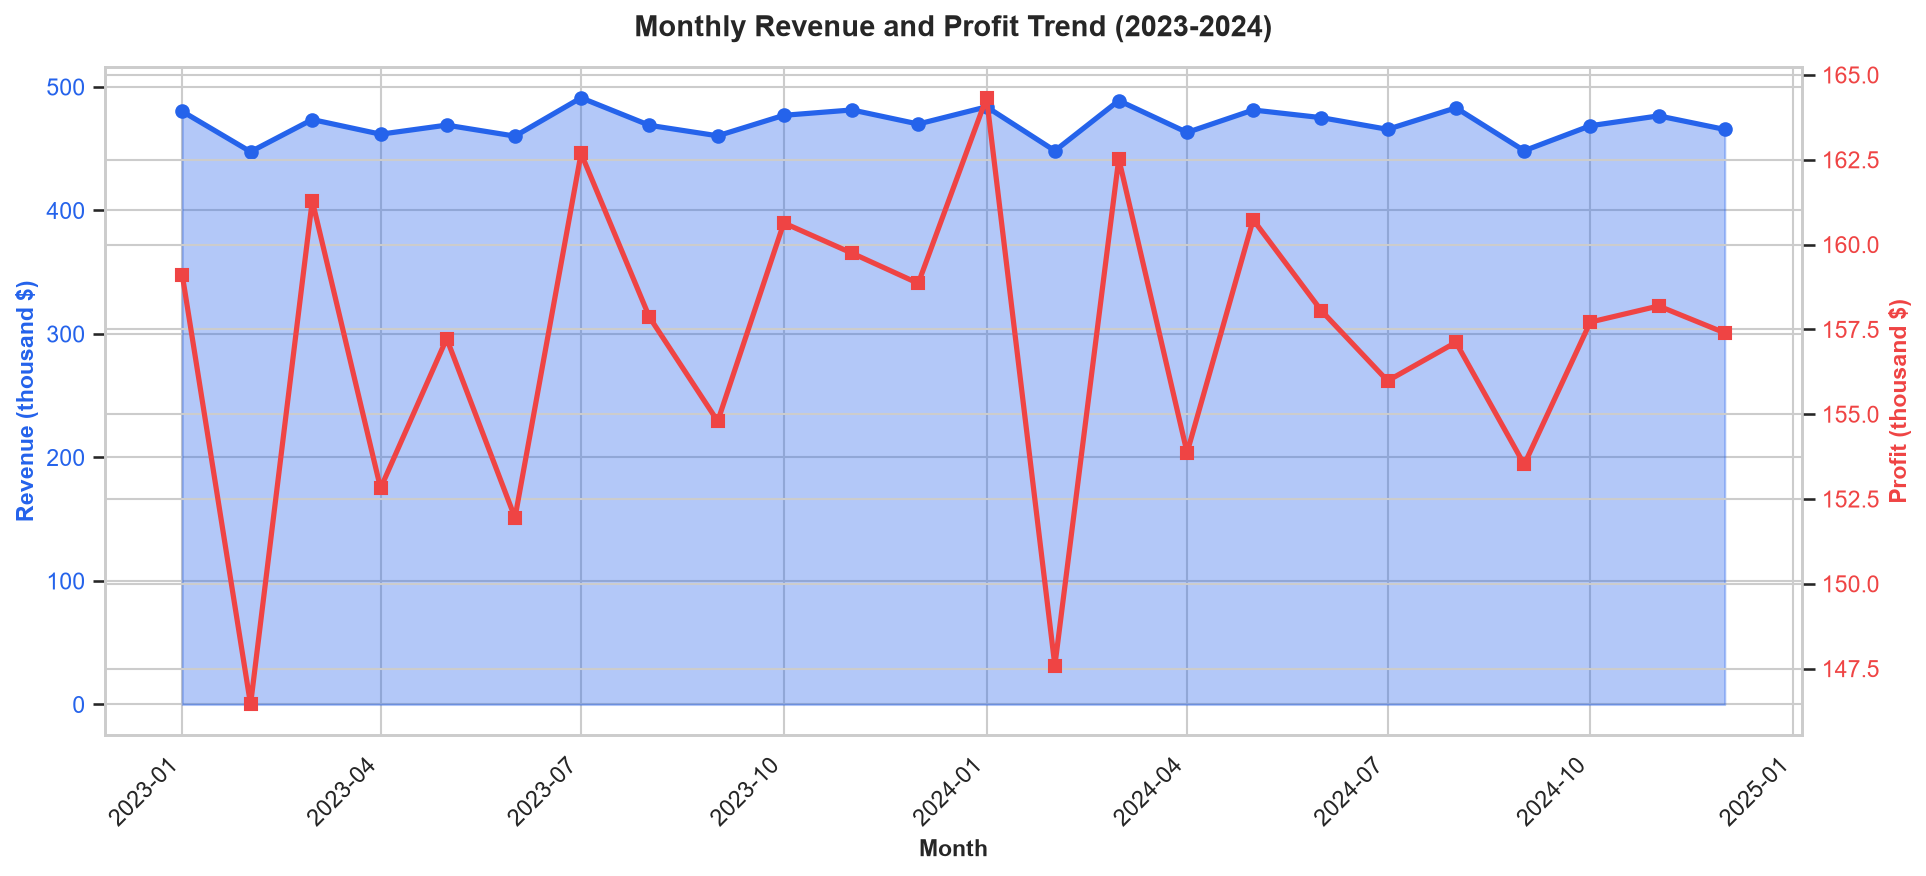

In [307]:
fig, ax1 = plt.subplots(figsize=(13, 6))

# Revenue (left axis)
ax1.fill_between(
    monthly['date'], monthly['revenue_k'],
    alpha=0.35, color='#2563EB', label='Revenue (k$)'
)
ax1.plot(
    monthly['date'], monthly['revenue_k'],
    color='#2563EB', linewidth=2.5, marker='o', markersize=6
)
ax1.set_xlabel('Month', fontsize=11, fontweight='bold')
ax1.set_ylabel('Revenue (thousand $)', fontsize=11, fontweight='bold', color='#2563EB')
ax1.tick_params(axis='y', labelcolor='#2563EB')

# Profit (right axis)
ax2 = ax1.twinx()
ax2.plot(
    monthly['date'], monthly['profit_k'],
    color='#EF4444', linewidth=2.5, marker='s', markersize=6, label='Profit (k$)'
)
ax2.set_ylabel('Profit (thousand $)', fontsize=11, fontweight='bold', color='#EF4444')
ax2.tick_params(axis='y', labelcolor='#EF4444')

# Title & layout
plt.title('Monthly Revenue and Profit Trend (2023-2024)', fontsize=14, fontweight='bold', pad=15)
fig.autofmt_xdate(rotation=45)
fig.tight_layout()

# Save & show
plt.savefig(f'charts/01_monthly_trend.png', dpi=150, bbox_inches='tight')
plt.show() 

### 7.2 CHART 2: Revenue by Region (Bar with share %)

In [308]:
region_df = df.groupby('store_region').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique'),
    customers=('customer_id', 'nunique')
).reset_index().sort_values('revenue', ascending=False)
region_df['revenue_m'] = region_df['revenue'] / 1e6
region_df['share_pct'] = (region_df['revenue'] / region_df['revenue'].sum() * 100).round(1)
region_df['margin'] = (region_df['profit'] / region_df['revenue'] * 100).round(1)
region_df['aov'] = (region_df['revenue'] / region_df['transactions']).round(2)
region_df.to_csv(f'kpi/region_summary.csv', index=False)
region_df.to_csv(f'kpi/region_profit.csv', index=False)


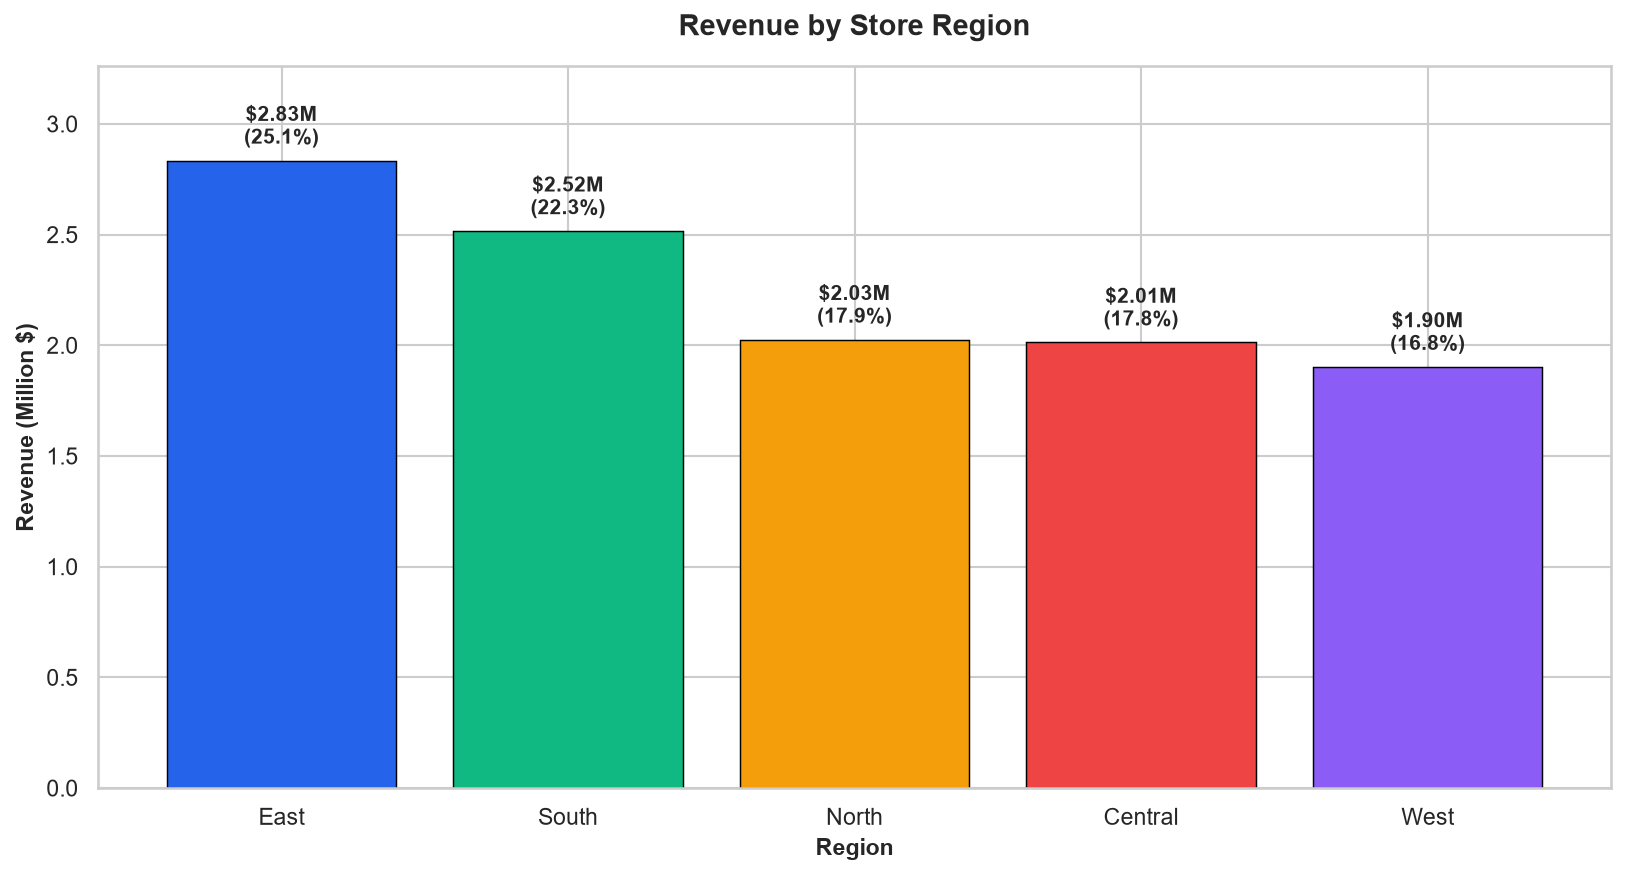

In [309]:
fig, ax = plt.subplots(figsize=(11, 6))

# Bars
bars = ax.bar(
    region_df['store_region'], region_df['revenue_m'],
    color=PALETTE[:len(region_df)], edgecolor='black', linewidth=0.7
)

# Annotate each bar
for b, v, s in zip(bars, region_df['revenue_m'], region_df['share_pct']):
    ax.text(
        b.get_x() + b.get_width() / 2, v + 0.05,
        f'${v:.2f}M\n({s}%)',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

# Labels & title
ax.set_title('Revenue by Store Region', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Region', fontsize=11, fontweight='bold')
ax.set_ylabel('Revenue (Million $)', fontsize=11, fontweight='bold')
ax.set_ylim(0, region_df['revenue_m'].max() * 1.15)

# Layout & save
plt.tight_layout()
plt.savefig(f'charts/02_revenue_by_region.png', dpi=150, bbox_inches='tight')
plt.show() 

In [310]:
print(region_df[['store_region', 'revenue_m', 'share_pct', 'transactions', 'aov', 'margin']].to_string(index=False))

store_region  revenue_m  share_pct  transactions   aov  margin
        East   2.834338       25.1         30043 94.34    33.4
       South   2.515478       22.3         26599 94.57    33.3
       North   2.025523       17.9         21578 93.87    33.6
     Central   2.012846       17.8         21679 92.85    33.5
        West   1.902475       16.8         20101 94.65    33.2


### 7.3 CHART 3: Top 10 Product Categories (Horizontal Bar)

In [311]:
cat_df = df.groupby('product_category').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    qty=('quantity', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index().sort_values('revenue', ascending=False).head(10)



In [312]:
cat_df['profit_margin'] = (cat_df['profit'] / cat_df['revenue'] * 100).round(1)
cat_df['revenue_k'] = cat_df['revenue'] / 1000
cat_df.to_csv(f'kpi/category_summary.csv', index=False)

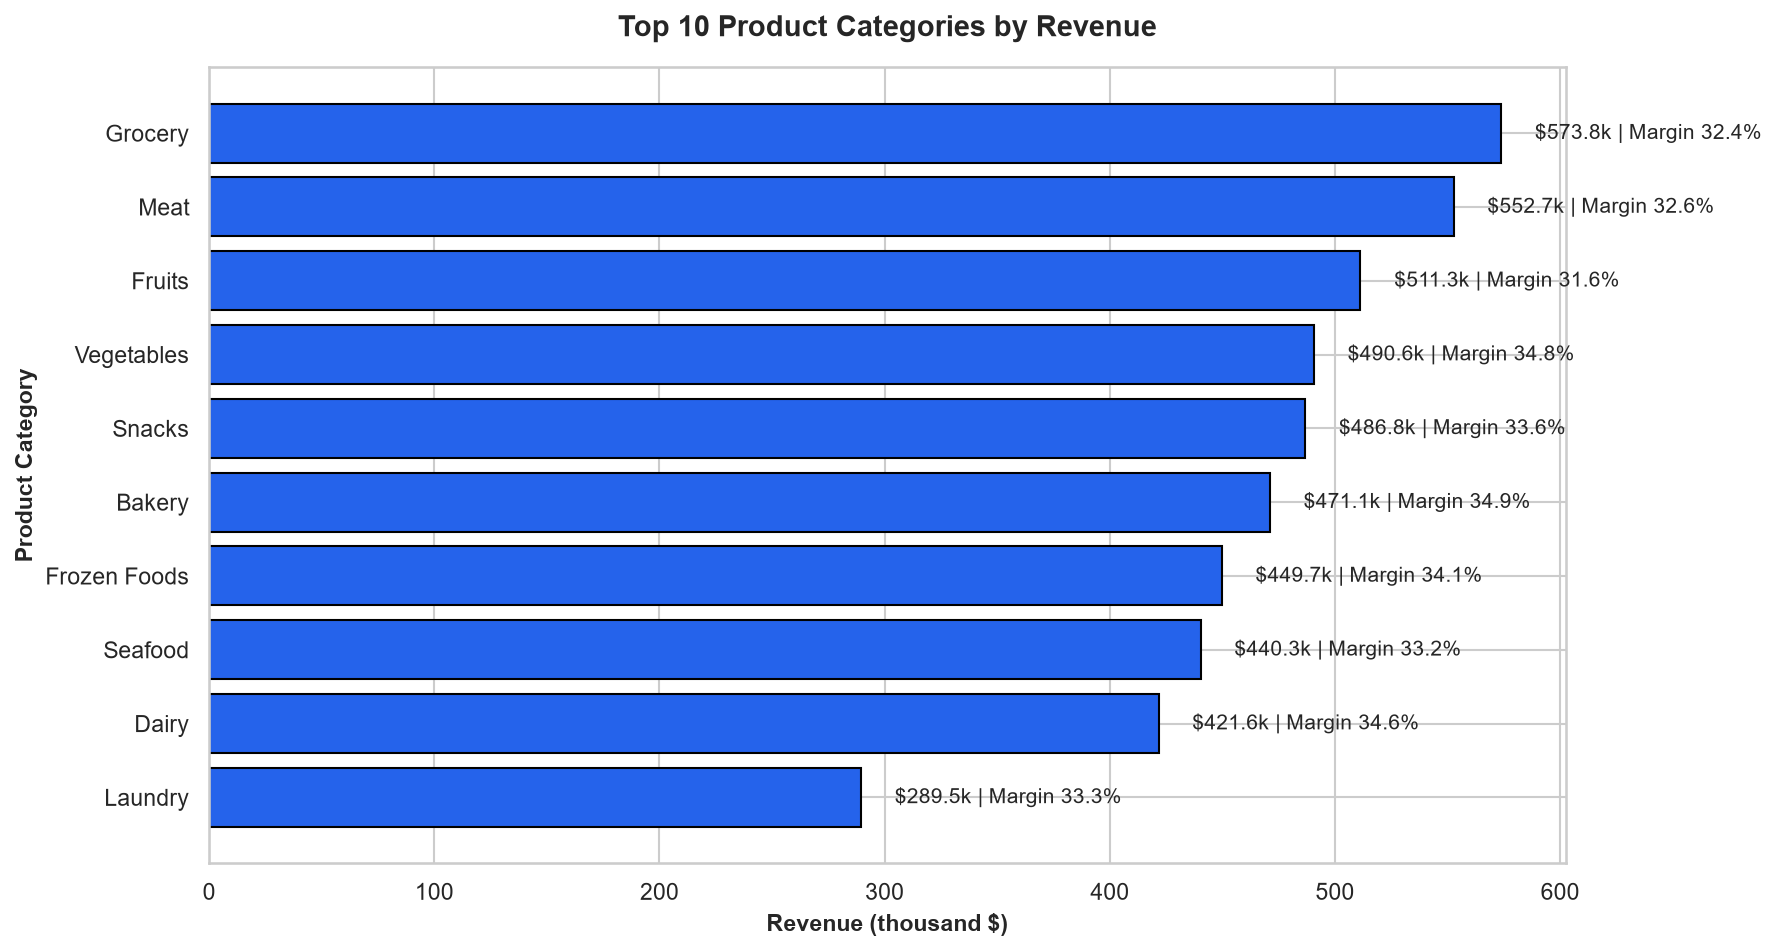

In [313]:
fig, ax = plt.subplots(figsize=(12, 6.5))

# Horizontal bars (reversed for top-to-bottom display)
bars = ax.barh(
    cat_df['product_category'][::-1], cat_df['revenue_k'][::-1],
    color='#2563EB', edgecolor='black'
)

# Annotate each bar
for b, v, m in zip(bars, cat_df['revenue_k'][::-1], cat_df['profit_margin'][::-1]):
    ax.text(
        v + 15, b.get_y() + b.get_height() / 2,
        f'${v:.1f}k | Margin {m}%',
        va='center', fontsize=10
    )

# Labels & title
ax.set_title('Top 10 Product Categories by Revenue', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Revenue (thousand $)', fontsize=11, fontweight='bold')
ax.set_ylabel('Product Category', fontsize=11, fontweight='bold')

# Layout & save
plt.tight_layout()
plt.savefig(f'charts/03_top_categories.png', dpi=150, bbox_inches='tight')
plt.show()   

### 7.4 CHART 4: Revenue Share by Product Department (Donut)

In [314]:
dept_df = df.groupby('product_department').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    cogs=('cost_of_goods_sold', 'sum'),
    txns=('transaction_id', 'nunique')
).reset_index().sort_values('revenue', ascending=False)

In [316]:
dept_df['margin'] = (dept_df['profit'] / dept_df['revenue'] * 100).round(1)
dept_df['share'] = (dept_df['revenue'] / dept_df['revenue'].sum() * 100).round(1)
dept_df['revenue_k'] = (dept_df['revenue'] / 1000).round(1)
dept_df['profit_k'] = (dept_df['profit'] / 1000).round(1)
dept_df.to_csv(f'kpi/dept_summary.csv', index=False)

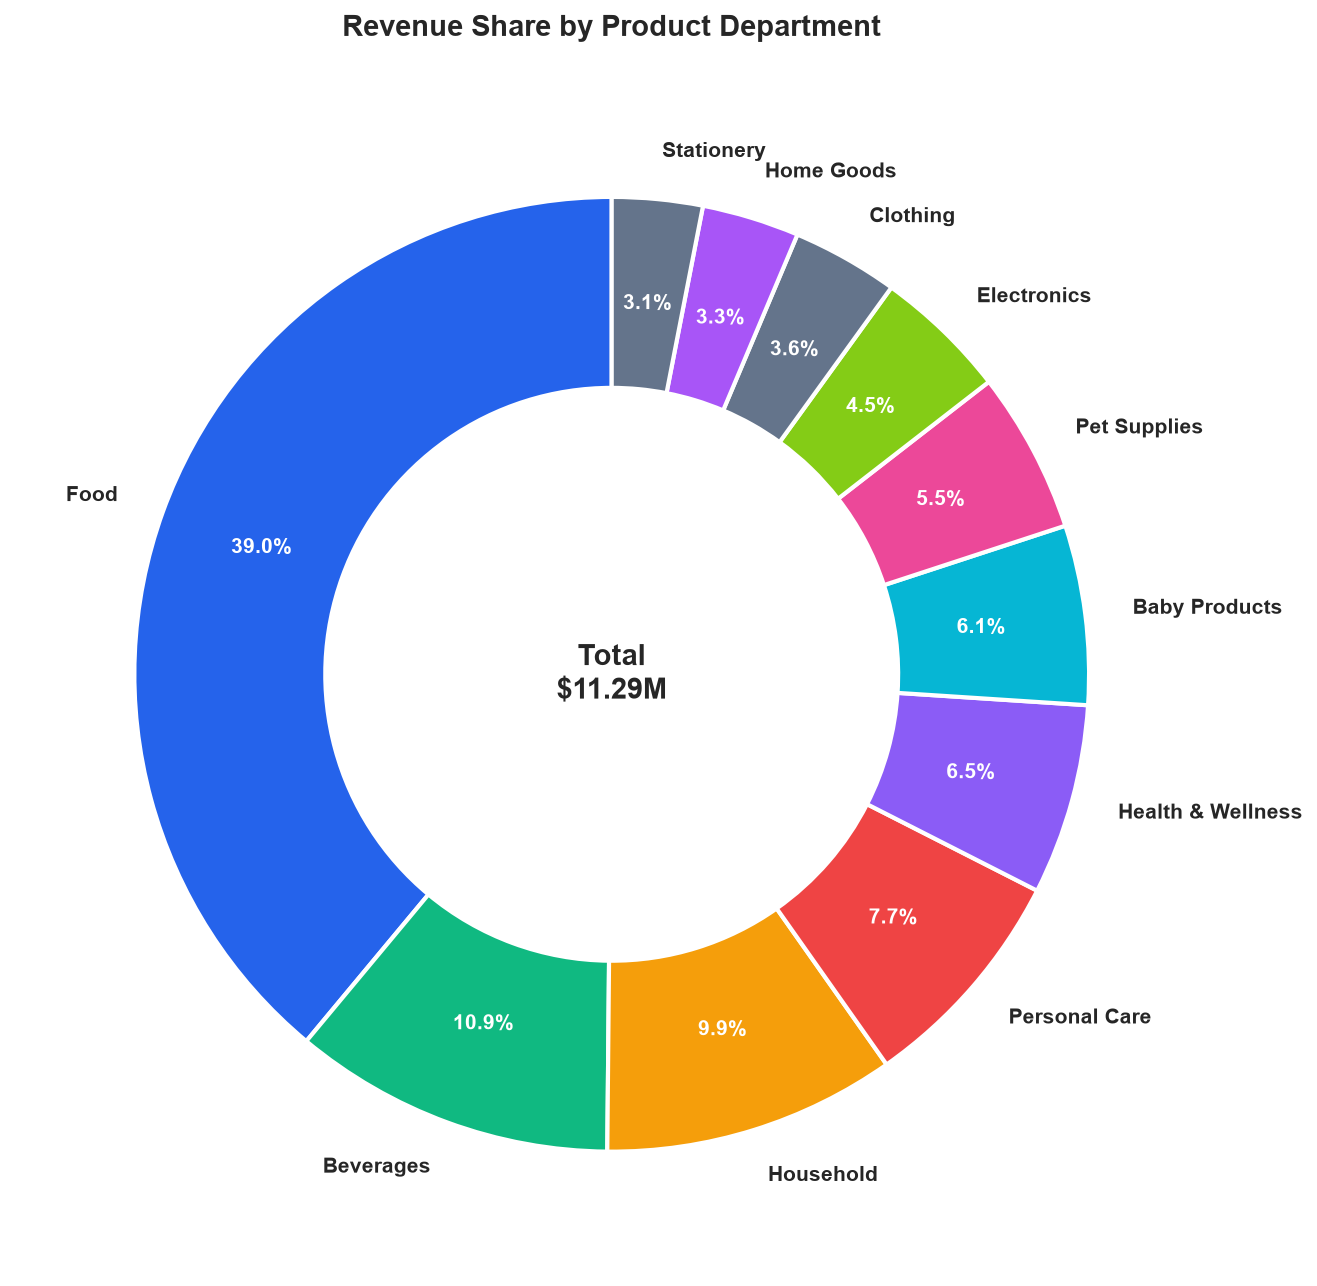

In [317]:
fig, ax = plt.subplots(figsize=(9, 9))

# Colors
colors = PALETTE + ['#64748B', '#A855F7', '#0EA5E9', '#22D3EE']
colors = colors[:len(dept_df)]

# Donut chart
wedges, texts, autotexts = ax.pie(
    dept_df['revenue'],
    labels=dept_df['product_department'],
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10, fontweight='bold')
)

# Style percentage labels
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')

# Center text (total revenue)
ax.text(
    0, 0,
    f"Total\n${dept_df['revenue'].sum() / 1e6:.2f}M",
    ha='center', va='center', fontsize=14, fontweight='bold'
)

# Title & layout
ax.set_title('Revenue Share by Product Department', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

# Save & show
plt.savefig(f'charts/04_department_donut.png', dpi=150, bbox_inches='tight')
plt.show()   

## 8️⃣ Comparative Analysis Visualizations (Charts 5-8)

**What:** Generate four comparative charts:  
5. Customer Segment Performance (revenue + AOV + margin)  
6. Payment Method Analysis (pie + bar comparison)  
7. Hourly & Day-of-Week Patterns (area + bar)  
8. Promotion & Coupon Effectiveness (AOV vs margin)

**Why:** Comparative analysis is the bridge between descriptive reporting (what happened) and diagnostic analysis (why it happened). These charts show *how different segments of the business perform against each other*.

### 8.1 CHART 5: Customer Segment Performance

In [318]:
seg_df = df.groupby('customer_segment').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    customers=('customer_id', 'nunique'),
    transactions=('transaction_id', 'nunique')
).reset_index().sort_values('revenue', ascending=False)

In [319]:
seg_df['aov'] = (seg_df['revenue'] / seg_df['transactions']).round(2)
seg_df['margin_pct'] = (seg_df['profit'] / seg_df['revenue'] * 100).round(1)
seg_df['revenue_k'] = seg_df['revenue'] / 1000
seg_df.to_csv(f'kpi/segment_summary.csv', index=False)

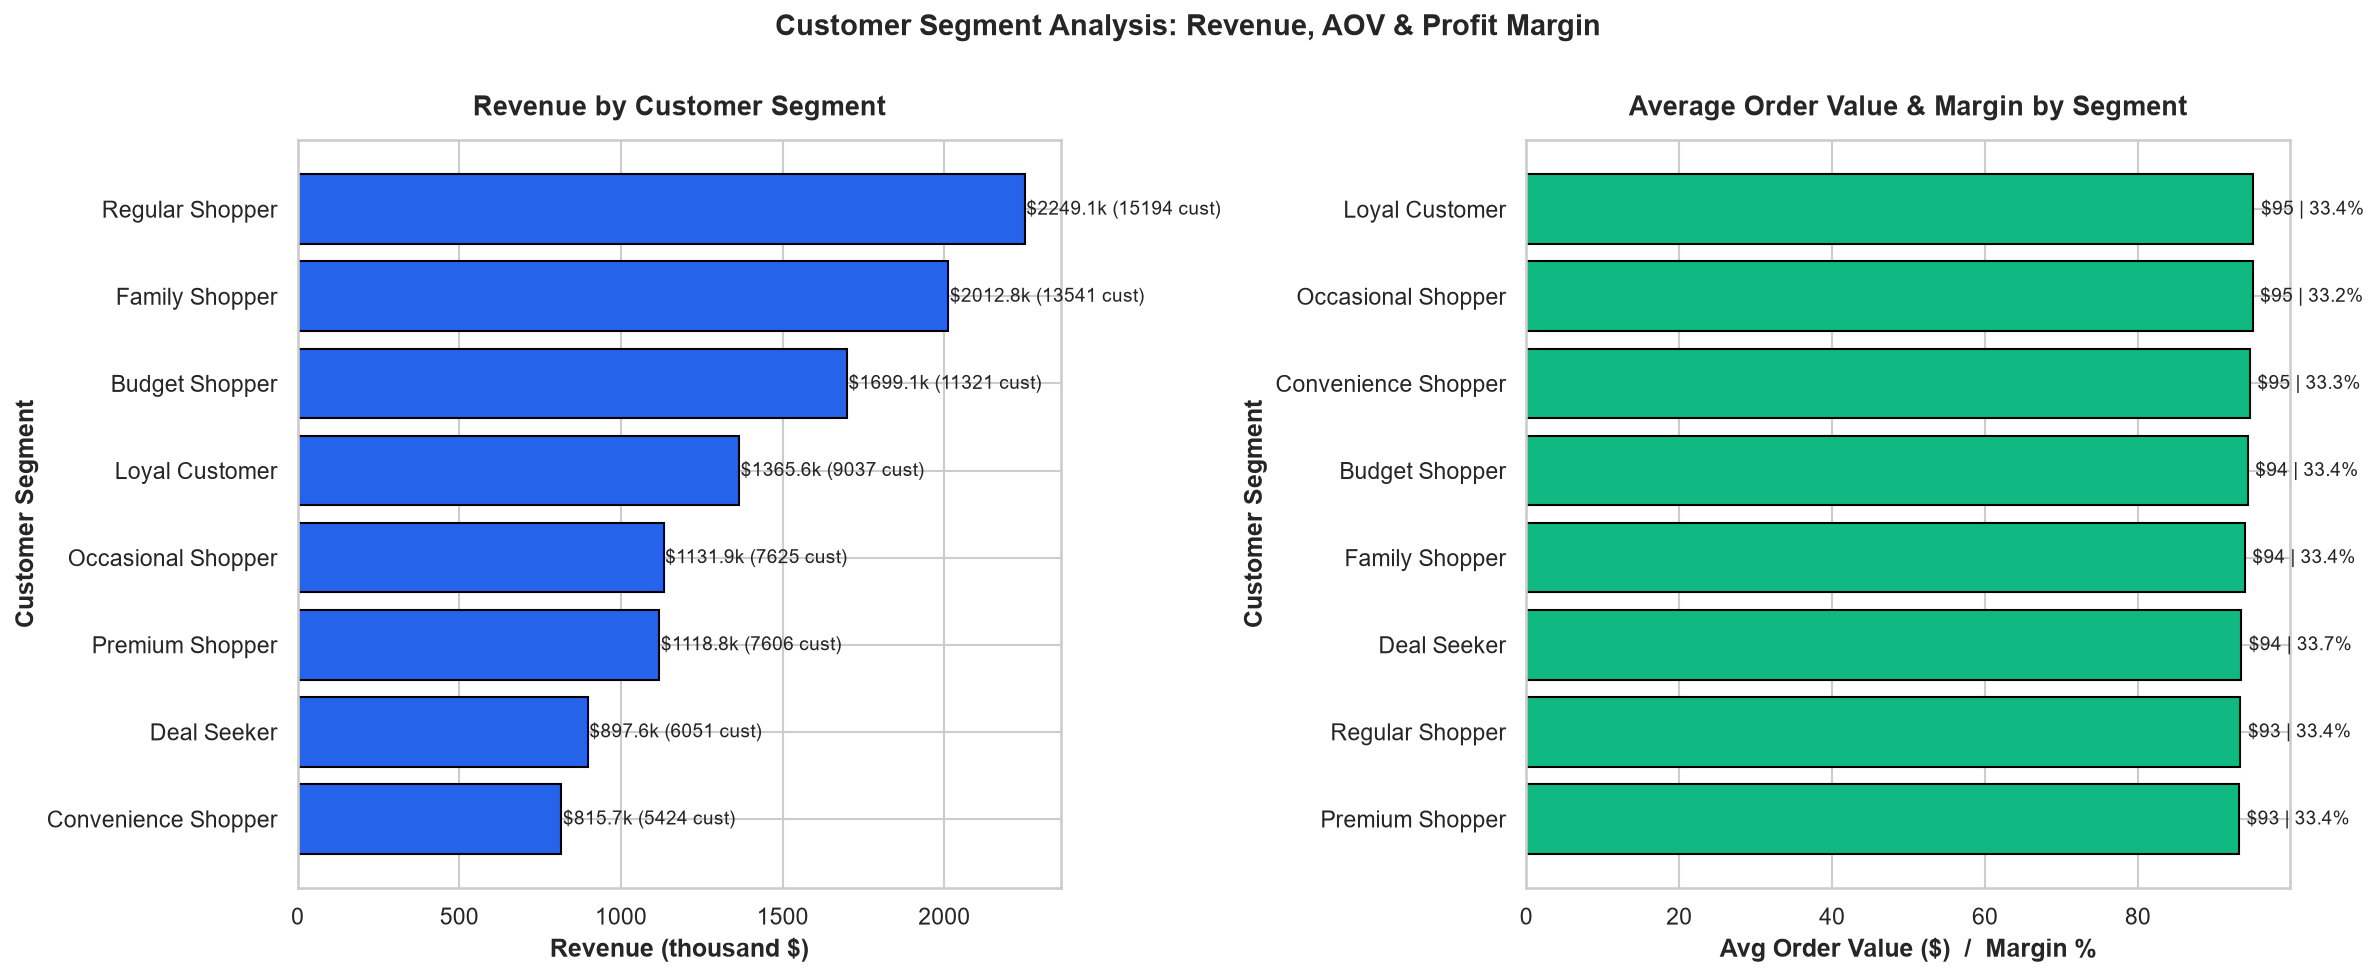

In [320]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# ── Left: Revenue by segment ──────────────────────────────────
seg_sorted = seg_df.sort_values('revenue', ascending=True)
bars1 = axes[0].barh(
    seg_sorted['customer_segment'], seg_sorted['revenue_k'],
    color=PALETTE[0], edgecolor='black'
)

for b, v, c in zip(bars1, seg_sorted['revenue_k'], seg_sorted['customers']):
    axes[0].text(
        v + 5, b.get_y() + b.get_height() / 2,
        f'${v:.1f}k ({c} cust)',
        va='center', fontsize=9
    )

axes[0].set_title('Revenue by Customer Segment', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Revenue (thousand $)', fontweight='bold')
axes[0].set_ylabel('Customer Segment', fontweight='bold')

# ── Right: AOV by segment ─────────────────────────────────────
seg_sorted2 = seg_df.sort_values('aov', ascending=True)
bars2 = axes[1].barh(
    seg_sorted2['customer_segment'], seg_sorted2['aov'],
    color=PALETTE[1], edgecolor='black'
)

for b, v, m in zip(bars2, seg_sorted2['aov'], seg_sorted2['margin_pct']):
    axes[1].text(
        v + 1, b.get_y() + b.get_height() / 2,
        f'${v:.0f} | {m}%',
        va='center', fontsize=9
    )

axes[1].set_title('Average Order Value & Margin by Segment', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Avg Order Value ($)  /  Margin %', fontweight='bold')
axes[1].set_ylabel('Customer Segment', fontweight='bold')

# ── Title & layout ────────────────────────────────────────────
plt.suptitle(
    'Customer Segment Analysis: Revenue, AOV & Profit Margin',
    fontsize=14, fontweight='bold', y=1.00
)
plt.tight_layout()

# ── Save & show ───────────────────────────────────────────────
plt.savefig(f'charts/05_customer_segments.png', dpi=150, bbox_inches='tight')
plt.show()   

### 8.2 CHART 6: Payment Method Analysis 

In [321]:
pay_df = df.groupby('payment_method').agg(
    revenue=('total_amount', 'sum'),
    transactions=('transaction_id', 'nunique'),
    avg_time=('payment_processing_time_seconds', 'mean')
).reset_index().sort_values('revenue', ascending=False)

In [322]:
pay_df['share'] = (pay_df['revenue'] / pay_df['revenue'].sum() * 100).round(1)
pay_df['aov'] = (pay_df['revenue'] / pay_df['transactions']).round(2)
pay_df['revenue_k'] = pay_df['revenue'] / 1000
pay_df.to_csv(f'kpi/payment_summary.csv', index=False)

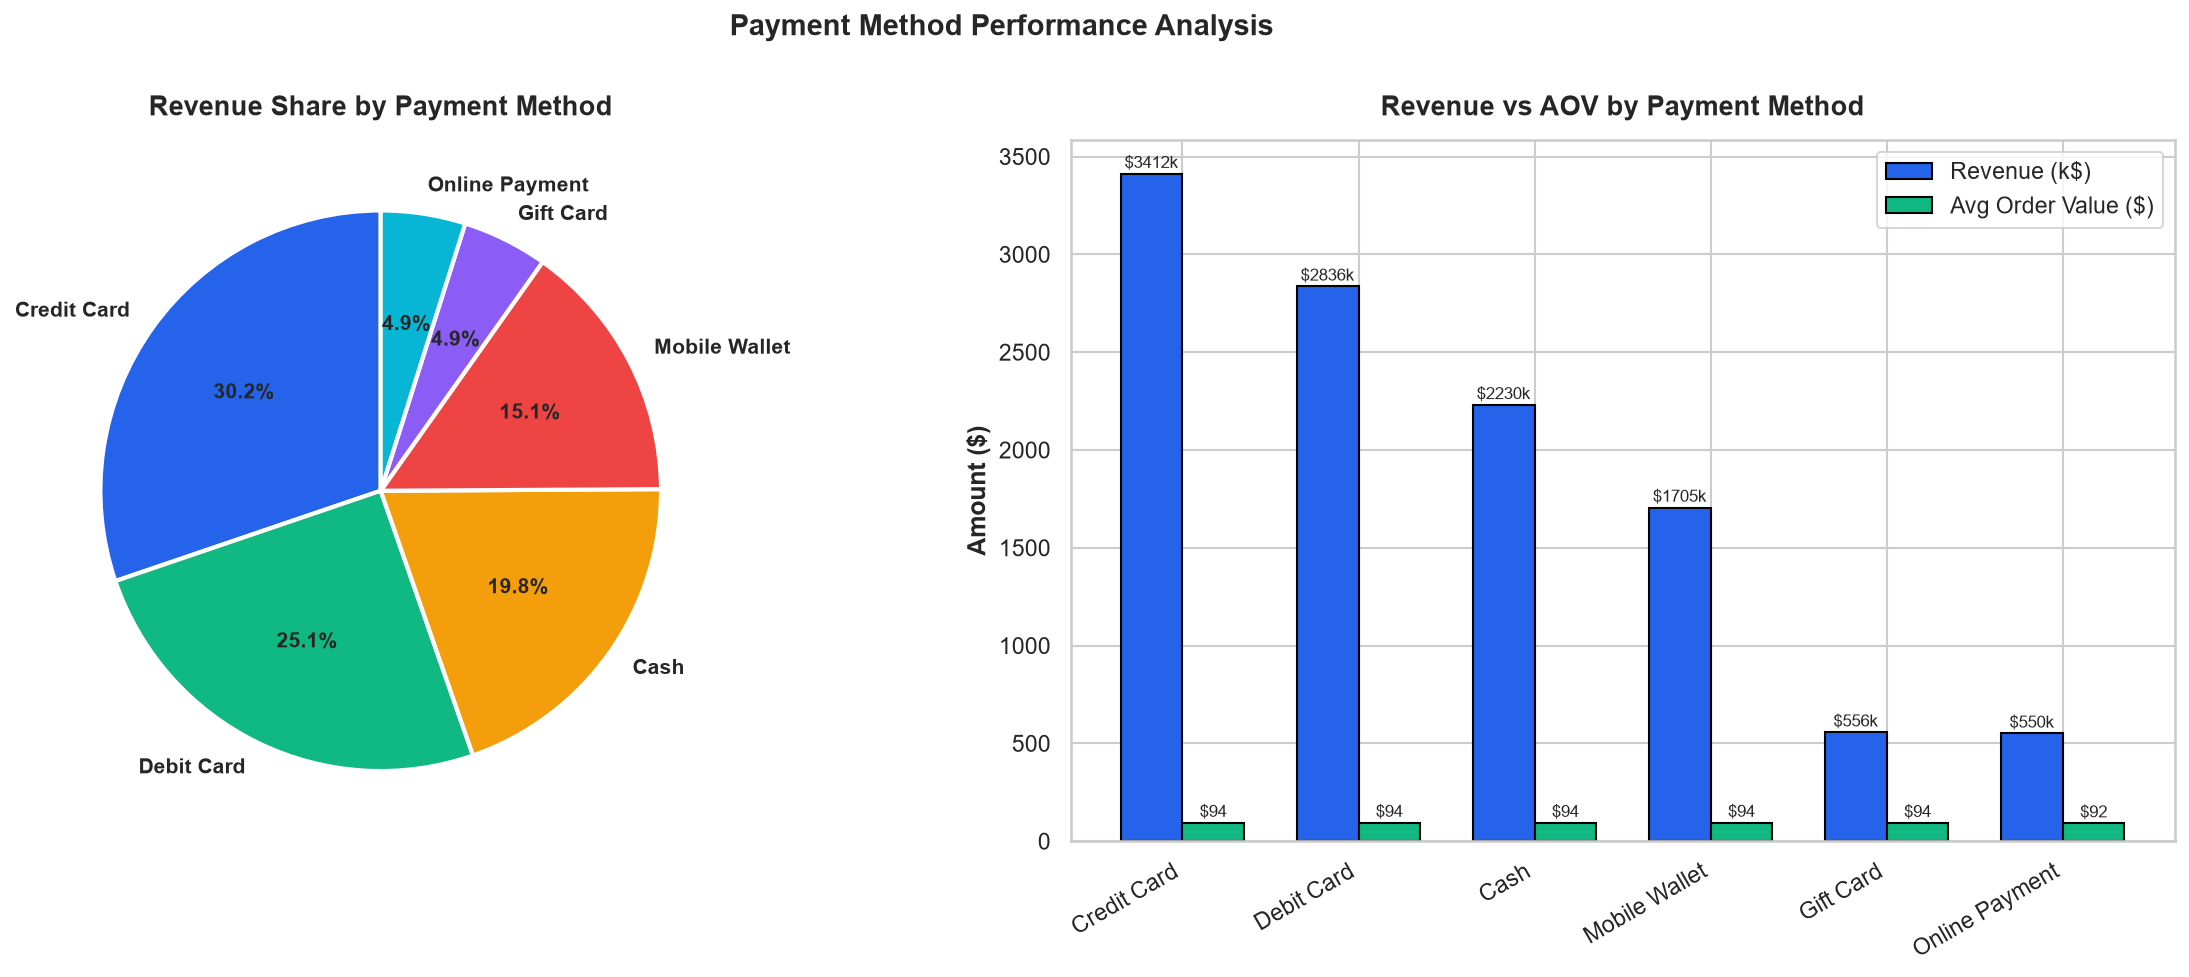

In [326]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
colors = PALETTE[:len(pay_df)]

# ── Left: Revenue share by payment method (pie) ──────────────
axes[0].pie(
    pay_df['revenue'],
    labels=pay_df['payment_method'],
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10, fontweight='bold')
)
axes[0].set_title('Revenue Share by Payment Method', fontsize=13, fontweight='bold', pad=12)

# ── Right: Revenue vs AOV (grouped bar) ──────────────────────
x = np.arange(len(pay_df))
width = 0.35

axes[1].bar(
    x - width / 2, pay_df['revenue_k'], width,
    label='Revenue (k$)', color=PALETTE[0], edgecolor='black'
)
axes[1].bar(
    x + width / 2, pay_df['aov'], width,
    label='Avg Order Value ($)', color=PALETTE[1], edgecolor='black'
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(pay_df['payment_method'], rotation=30, ha='right')
axes[1].set_title('Revenue vs AOV by Payment Method', fontsize=13, fontweight='bold', pad=12)
axes[1].set_ylabel('Amount ($)', fontweight='bold')
axes[1].legend(loc='upper right')

# Annotate bars
for i, (r, a) in enumerate(zip(pay_df['revenue_k'], pay_df['aov'])):
    axes[1].text(i - width / 2, r + 30, f'${r:.0f}k', ha='center', fontsize=8)
    axes[1].text(i + width / 2, a + 30, f'${a:.0f}', ha='center', fontsize=8)

# ── Title & layout ────────────────────────────────────────────
plt.suptitle('Payment Method Performance Analysis', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()

# ── Save & show ───────────────────────────────────────────────
plt.savefig(f'charts/06_payment_methods.png', dpi=150, bbox_inches='tight')
plt.show()   

### 8.3 CHART 7: Hourly & Day-of-Week Pattern

In [327]:
df['shopping_hour'] = pd.to_numeric(df['shopping_hour'], errors='coerce')
hour_df = df.groupby('shopping_hour').agg(
    revenue=('total_amount', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index()

In [328]:
hour_df['revenue_k'] = hour_df['revenue'] / 1000

In [329]:
dow_df = df.groupby('day_name').agg(
    revenue=('total_amount', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index()
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow_df['day_name'] = pd.Categorical(dow_df['day_name'], categories=dow_order, ordered=True)
dow_df = dow_df.sort_values('day_name')
dow_df['revenue_k'] = dow_df['revenue'] / 1000

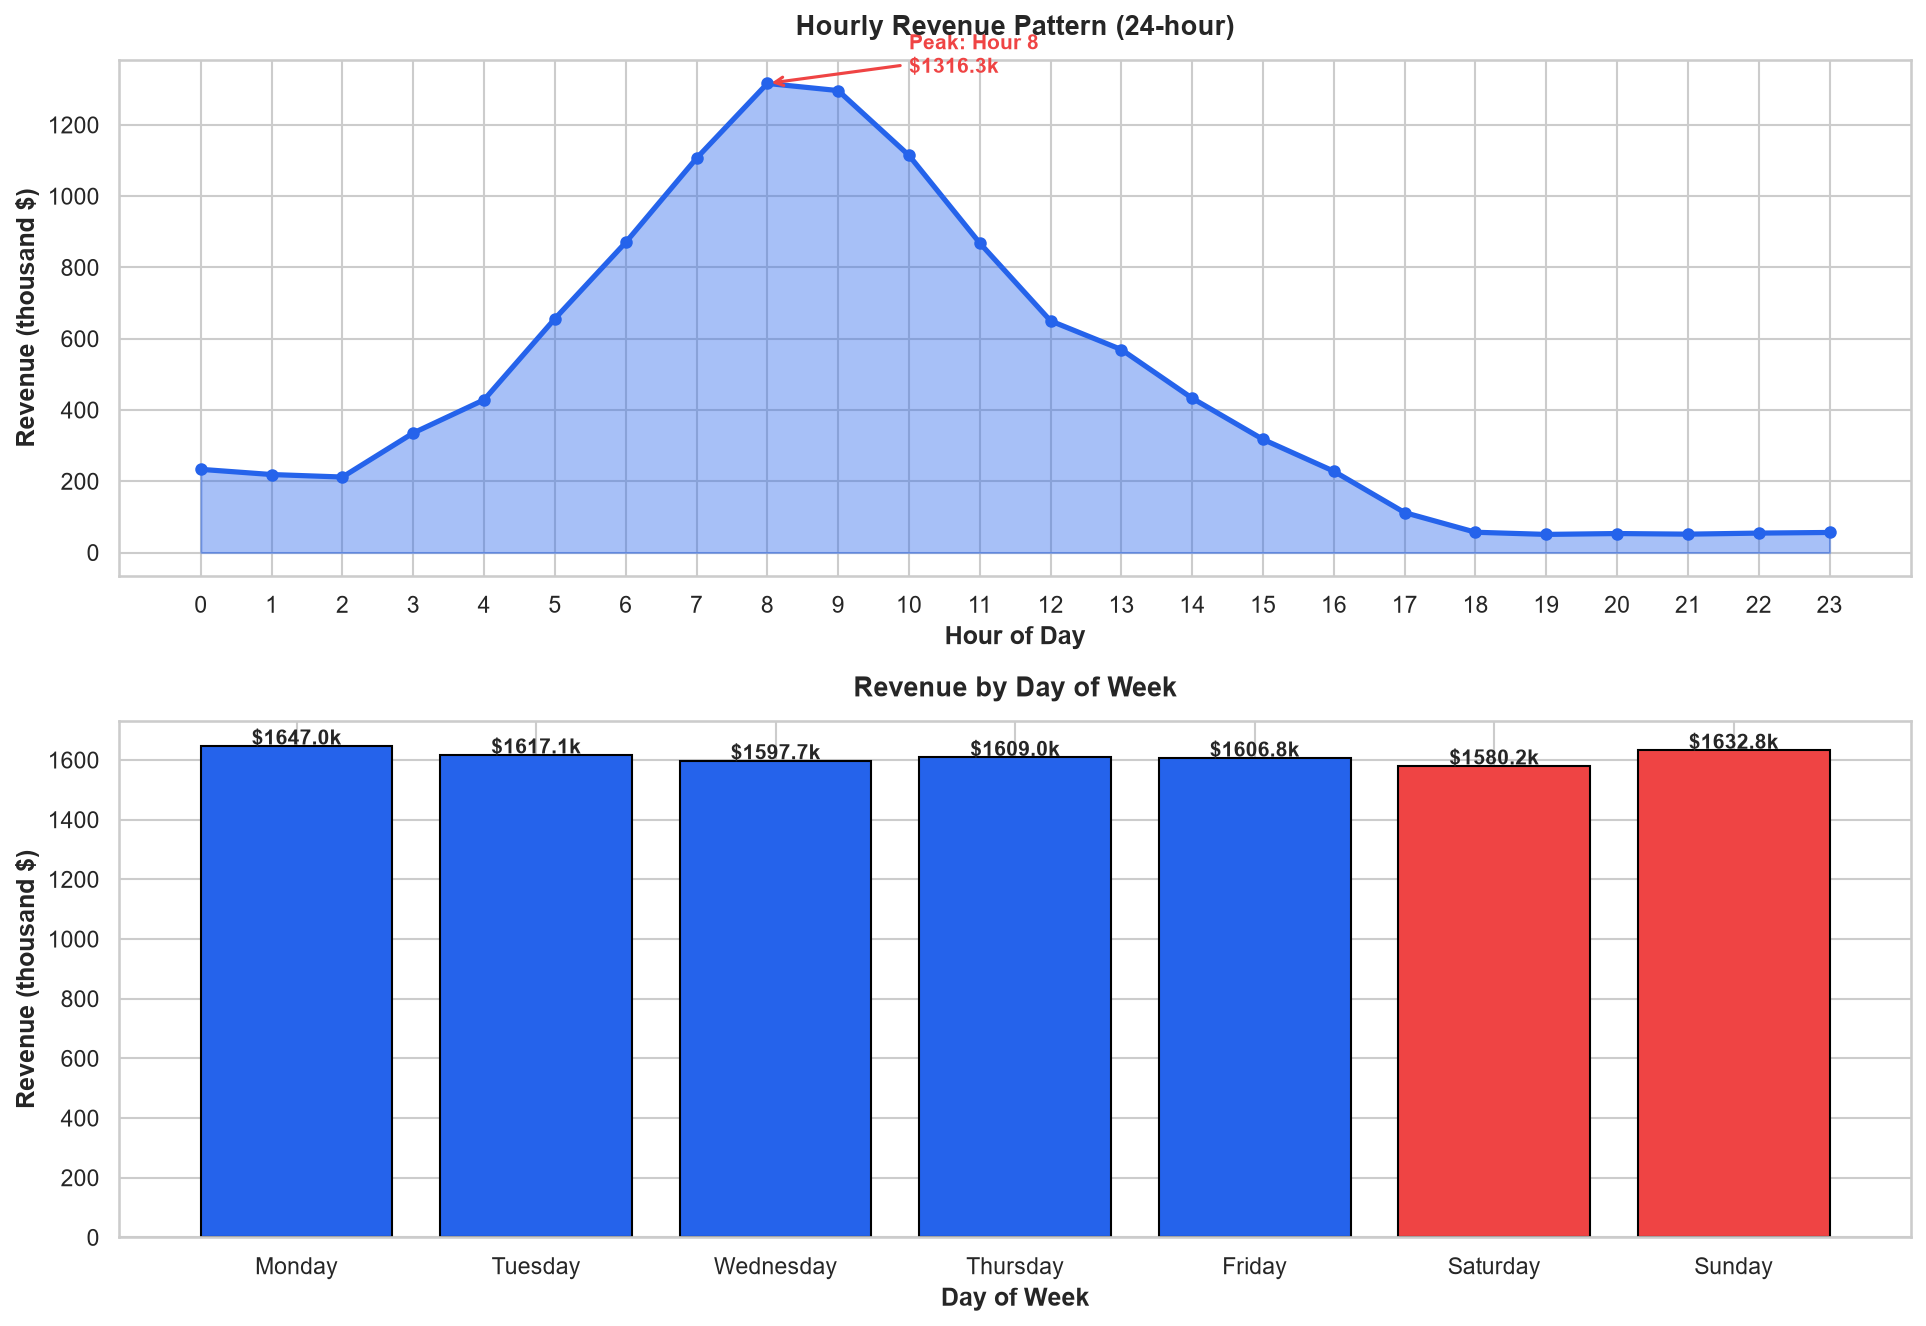

In [332]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# ── Top: Hourly revenue pattern ───────────────────────────────
axes[0].fill_between(
    hour_df['shopping_hour'], hour_df['revenue_k'],
    alpha=0.4, color='#2563EB'
)
axes[0].plot(
    hour_df['shopping_hour'], hour_df['revenue_k'],
    color='#2563EB', linewidth=2.5, marker='o', markersize=5
)

# Annotate peak hour
peak_hour = hour_df.loc[hour_df['revenue'].idxmax()]
axes[0].annotate(
    f"Peak: Hour {int(peak_hour['shopping_hour'])}\n${peak_hour['revenue_k']:.1f}k",
    xy=(peak_hour['shopping_hour'], peak_hour['revenue_k']),
    xytext=(peak_hour['shopping_hour'] + 2, peak_hour['revenue_k'] + 30),
    fontsize=10, fontweight='bold', color='#EF4444',
    arrowprops=dict(arrowstyle='->', color='#EF4444', lw=1.5)
)

axes[0].set_title('Hourly Revenue Pattern (24-hour)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Hour of Day', fontweight='bold')
axes[0].set_ylabel('Revenue (thousand $)', fontweight='bold')
axes[0].set_xticks(range(0, 24))

# ── Bottom: Revenue by day of week ────────────────────────────
colors_dow = [
    '#EF4444' if d in ['Saturday', 'Sunday'] else '#2563EB'
    for d in dow_df['day_name']
]
axes[1].bar(
    dow_df['day_name'], dow_df['revenue_k'],
    color=colors_dow, edgecolor='black'
)

# Annotate bars
for i, v in enumerate(dow_df['revenue_k']):
    axes[1].text(i, v + 5, f'${v:.1f}k', ha='center', fontsize=10, fontweight='bold')

axes[1].set_title('Revenue by Day of Week', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Day of Week', fontweight='bold')
axes[1].set_ylabel('Revenue (thousand $)', fontweight='bold')

# ── Layout & save ─────────────────────────────────────────────
plt.tight_layout()
plt.savefig(f'charts/07_time_patterns.png', dpi=150, bbox_inches='tight')
plt.show()   

### 8.4 CHART 8: Promotion & Coupon Effectiveness

In [333]:
promo_df = df.groupby('promotion_active').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique'),
    avg_discount=('discount_percent', 'mean')
).reset_index()

In [334]:
promo_df['aov'] = promo_df['revenue'] / promo_df['transactions']
promo_df['margin'] = (promo_df['profit'] / promo_df['revenue'] * 100).round(2)
promo_df.to_csv(f'kpi/promo_summary.csv', index=False)

In [335]:
coupon_df = df.groupby('coupon_used').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index()

In [336]:
coupon_df['aov'] = coupon_df['revenue'] / coupon_df['transactions']
coupon_df['margin'] = (coupon_df['profit'] / coupon_df['revenue'] * 100).round(2)
coupon_df.to_csv(f'kpi/coupon_summary.csv', index=False)


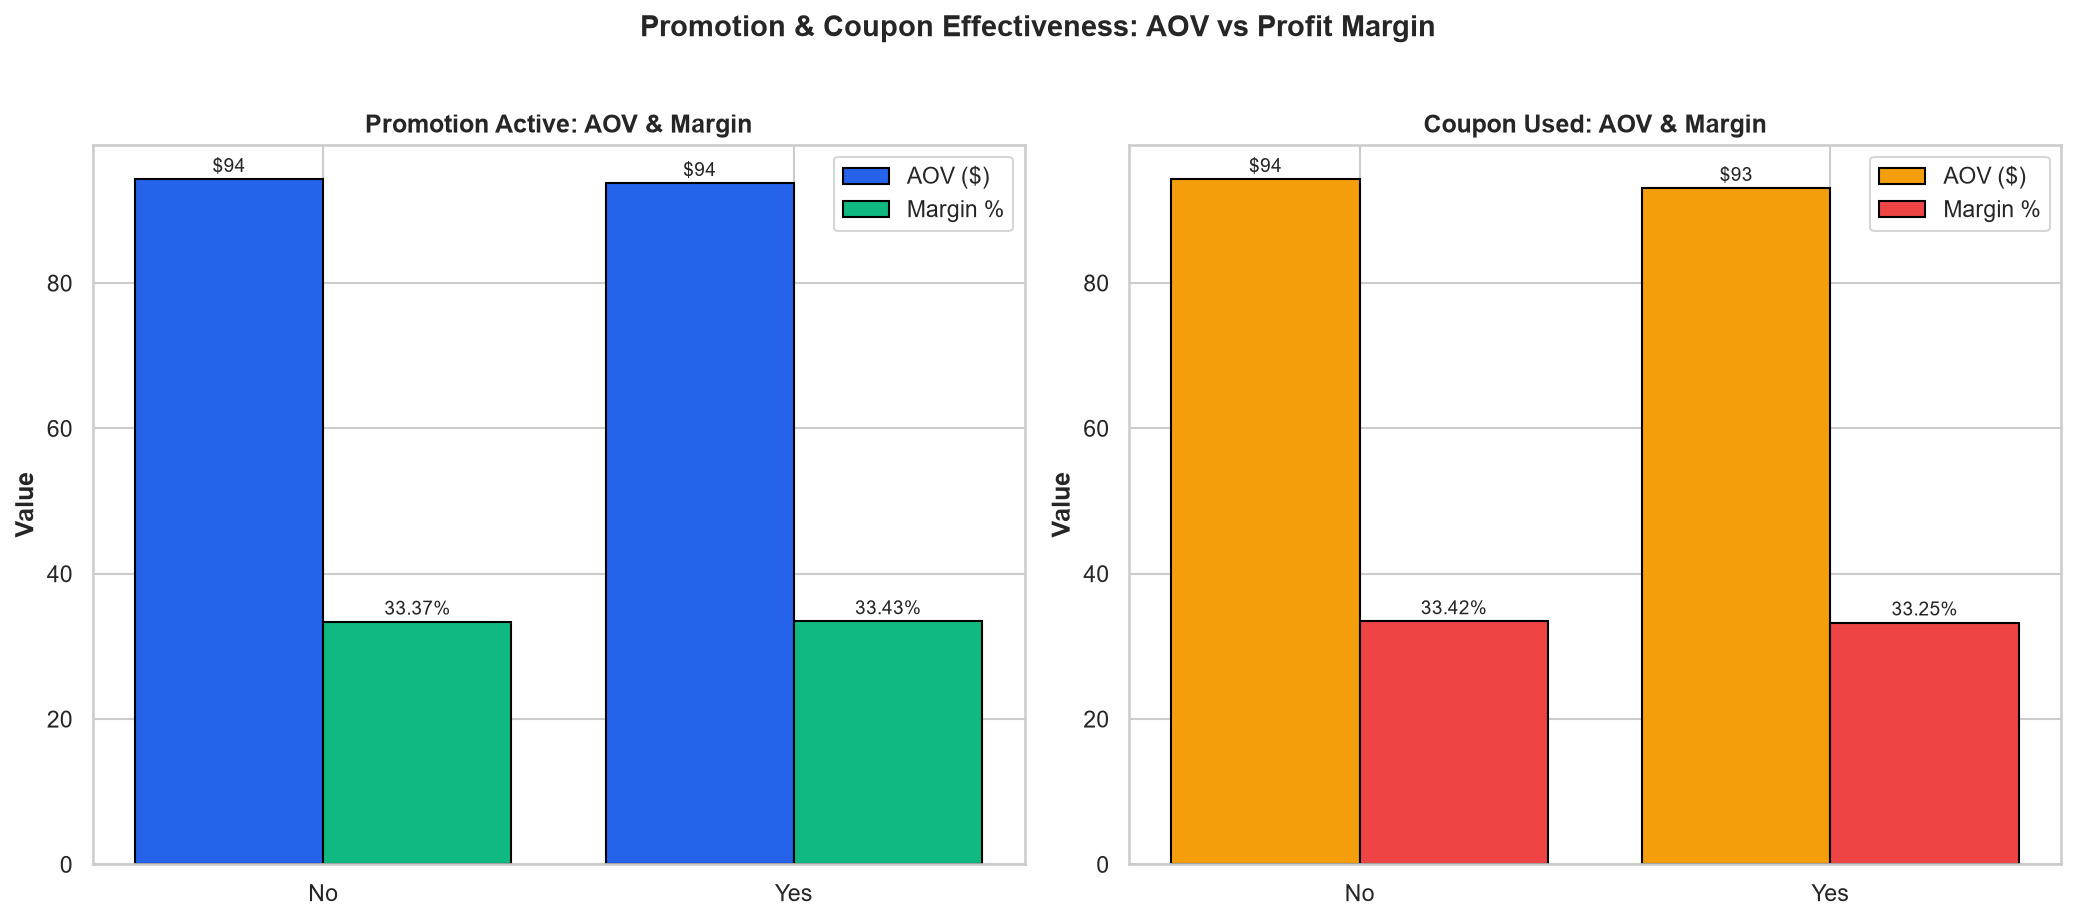

In [337]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── Left: Promotion impact ────────────────────────────────────
labels_p = promo_df['promotion_active'].astype(str)
x_p = np.arange(len(promo_df))

axes[0].bar(
    x_p - 0.2, promo_df['aov'], 0.4,
    label='AOV ($)', color=PALETTE[0], edgecolor='black'
)
axes[0].bar(
    x_p + 0.2, promo_df['margin'], 0.4,
    label='Margin %', color=PALETTE[1], edgecolor='black'
)

axes[0].set_xticks(x_p)
axes[0].set_xticklabels(labels_p, rotation=0)
axes[0].set_title('Promotion Active: AOV & Margin', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Value', fontweight='bold')
axes[0].legend()

# Annotate bars
for i, (a, m) in enumerate(zip(promo_df['aov'], promo_df['margin'])):
    axes[0].text(i - 0.2, a + 1, f'${a:.0f}', ha='center', fontsize=9)
    axes[0].text(i + 0.2, m + 1, f'{m}%', ha='center', fontsize=9)

# ── Right: Coupon impact ──────────────────────────────────────
labels_c = coupon_df['coupon_used'].astype(str)
x_c = np.arange(len(coupon_df))

axes[1].bar(
    x_c - 0.2, coupon_df['aov'], 0.4,
    label='AOV ($)', color=PALETTE[2], edgecolor='black'
)
axes[1].bar(
    x_c + 0.2, coupon_df['margin'], 0.4,
    label='Margin %', color=PALETTE[3], edgecolor='black'
)

axes[1].set_xticks(x_c)
axes[1].set_xticklabels(labels_c, rotation=0)
axes[1].set_title('Coupon Used: AOV & Margin', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Value', fontweight='bold')
axes[1].legend()

# Annotate bars
for i, (a, m) in enumerate(zip(coupon_df['aov'], coupon_df['margin'])):
    axes[1].text(i - 0.2, a + 1, f'${a:.0f}', ha='center', fontsize=9)
    axes[1].text(i + 0.2, m + 1, f'{m}%', ha='center', fontsize=9)

# ── Title & layout ────────────────────────────────────────────
plt.suptitle(
    'Promotion & Coupon Effectiveness: AOV vs Profit Margin',
    fontsize=14, fontweight='bold', y=1.02
)
plt.tight_layout()

# ── Save & show ───────────────────────────────────────────────
plt.savefig(f'charts/08_promotion_effect.png', dpi=150, bbox_inches='tight')
plt.show()   

## 9️⃣ Attribution & Diagnosis Visualizations 

**What:** Five diagnostic charts:  
9. Membership Tier Analysis (Bronze → Platinum)  
10. Store Format Performance (5 store types)  
11. Seasonality & YoY by Season  
12. Profit Distribution by Top Categories (boxplot)  
13. Discount Tier vs Margin Trade-off

**Why:** This is where descriptive analysis becomes *diagnostic*. We move from "what happened" to "why it happened" — identifying the specific drivers (membership tier, store format, season, discount depth) that explain the differences in business performance.

### 9.1 CHART 9: Membership Tier Analysis

In [338]:
mem_df = df.groupby('membership_tier').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    customers=('customer_id', 'nunique'),
    transactions=('transaction_id', 'nunique'),
    loyalty_pts=('loyalty_points_earned', 'sum')
).reset_index()



In [339]:
mem_order = ['Bronze', 'Silver', 'Gold', 'Platinum']
mem_df['membership_tier'] = pd.Categorical(mem_df['membership_tier'], categories=mem_order, ordered=True)
mem_df = mem_df.sort_values('membership_tier')
mem_df['aov'] = (mem_df['revenue'] / mem_df['transactions']).round(2)
mem_df['margin'] = (mem_df['profit'] / mem_df['revenue'] * 100).round(1)
mem_df['revenue_k'] = mem_df['revenue'] / 1000
mem_df.to_csv(f'kpi/membership_summary.csv', index=False)

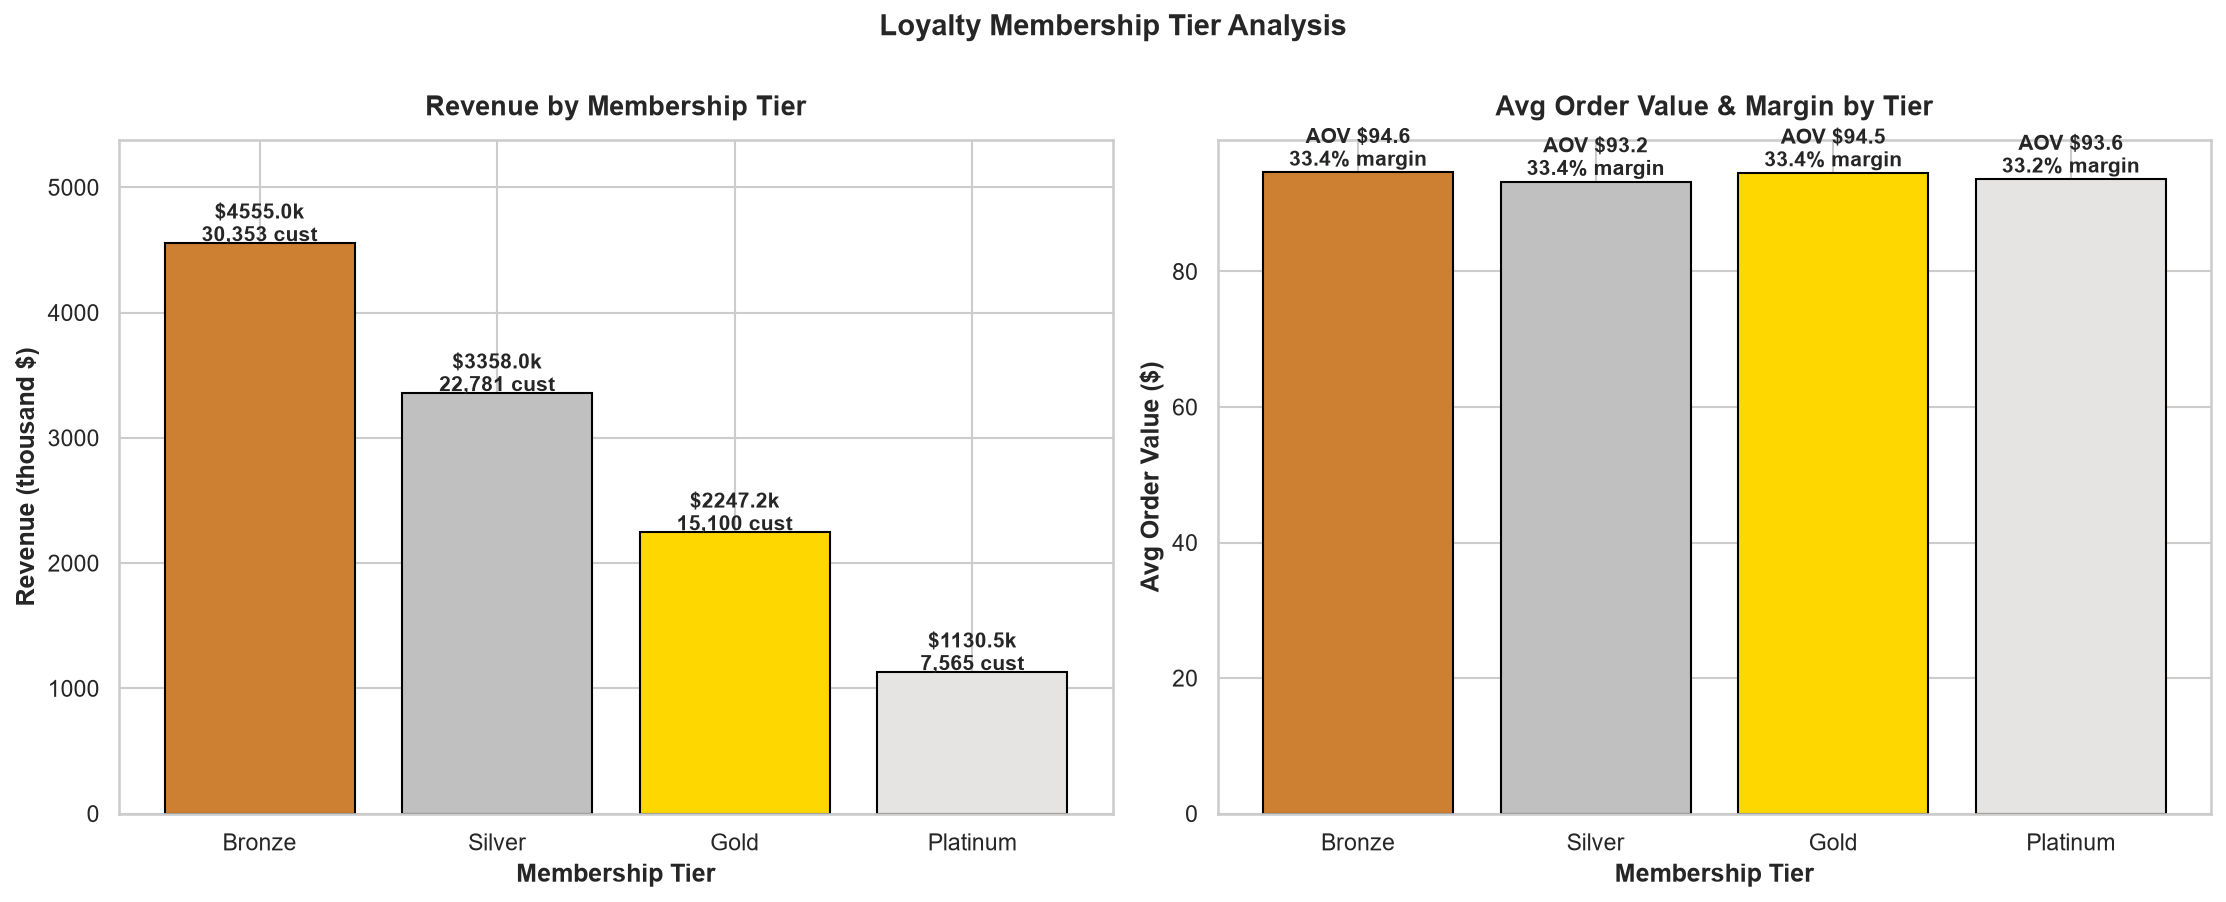

In [340]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors_mem = ['#CD7F32', '#C0C0C0', '#FFD700', '#E5E4E2']

# ── Left: Revenue by membership tier ──────────────────────────
axes[0].bar(
    mem_df['membership_tier'], mem_df['revenue_k'],
    color=colors_mem, edgecolor='black'
)

# Annotate bars
for i, (v, c) in enumerate(zip(mem_df['revenue_k'], mem_df['customers'])):
    axes[0].text(
        i, v + 15,
        f'${v:.1f}k\n{c:,} cust',
        ha='center', fontsize=10, fontweight='bold'
    )

axes[0].set_title('Revenue by Membership Tier', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Membership Tier', fontweight='bold')
axes[0].set_ylabel('Revenue (thousand $)', fontweight='bold')
axes[0].set_ylim(0, mem_df['revenue_k'].max() * 1.18)

# ── Right: AOV & Margin by tier ───────────────────────────────
axes[1].bar(
    mem_df['membership_tier'], mem_df['aov'],
    color=colors_mem, edgecolor='black'
)

# Annotate bars
for i, (a, m) in enumerate(zip(mem_df['aov'], mem_df['margin'])):
    axes[1].text(
        i, a + 1,
        f'AOV ${a:.1f}\n{m}% margin',
        ha='center', fontsize=10, fontweight='bold'
    )

axes[1].set_title('Avg Order Value & Margin by Tier', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Membership Tier', fontweight='bold')
axes[1].set_ylabel('Avg Order Value ($)', fontweight='bold')

# ── Title & layout ────────────────────────────────────────────
plt.suptitle('Loyalty Membership Tier Analysis', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()

# ── Save & show ───────────────────────────────────────────────
plt.savefig(f'charts/09_membership_tiers.png', dpi=150, bbox_inches='tight')
plt.show()   

### 9.2 CHART 10: Store Type Performance

In [341]:
store_df = df.groupby('store_type').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique'),
    stores=('store_id', 'nunique')
).reset_index().sort_values('revenue', ascending=False)

In [342]:
store_df['aov'] = (store_df['revenue'] / store_df['transactions']).round(2)
store_df['margin'] = (store_df['profit'] / store_df['revenue'] * 100).round(1)
store_df['rev_per_store'] = (store_df['revenue'] / store_df['stores'] / 1000).round(1)
store_df['revenue_k'] = store_df['revenue'] / 1000
store_df.to_csv(f'kpi/store_type_summary.csv', index=False)


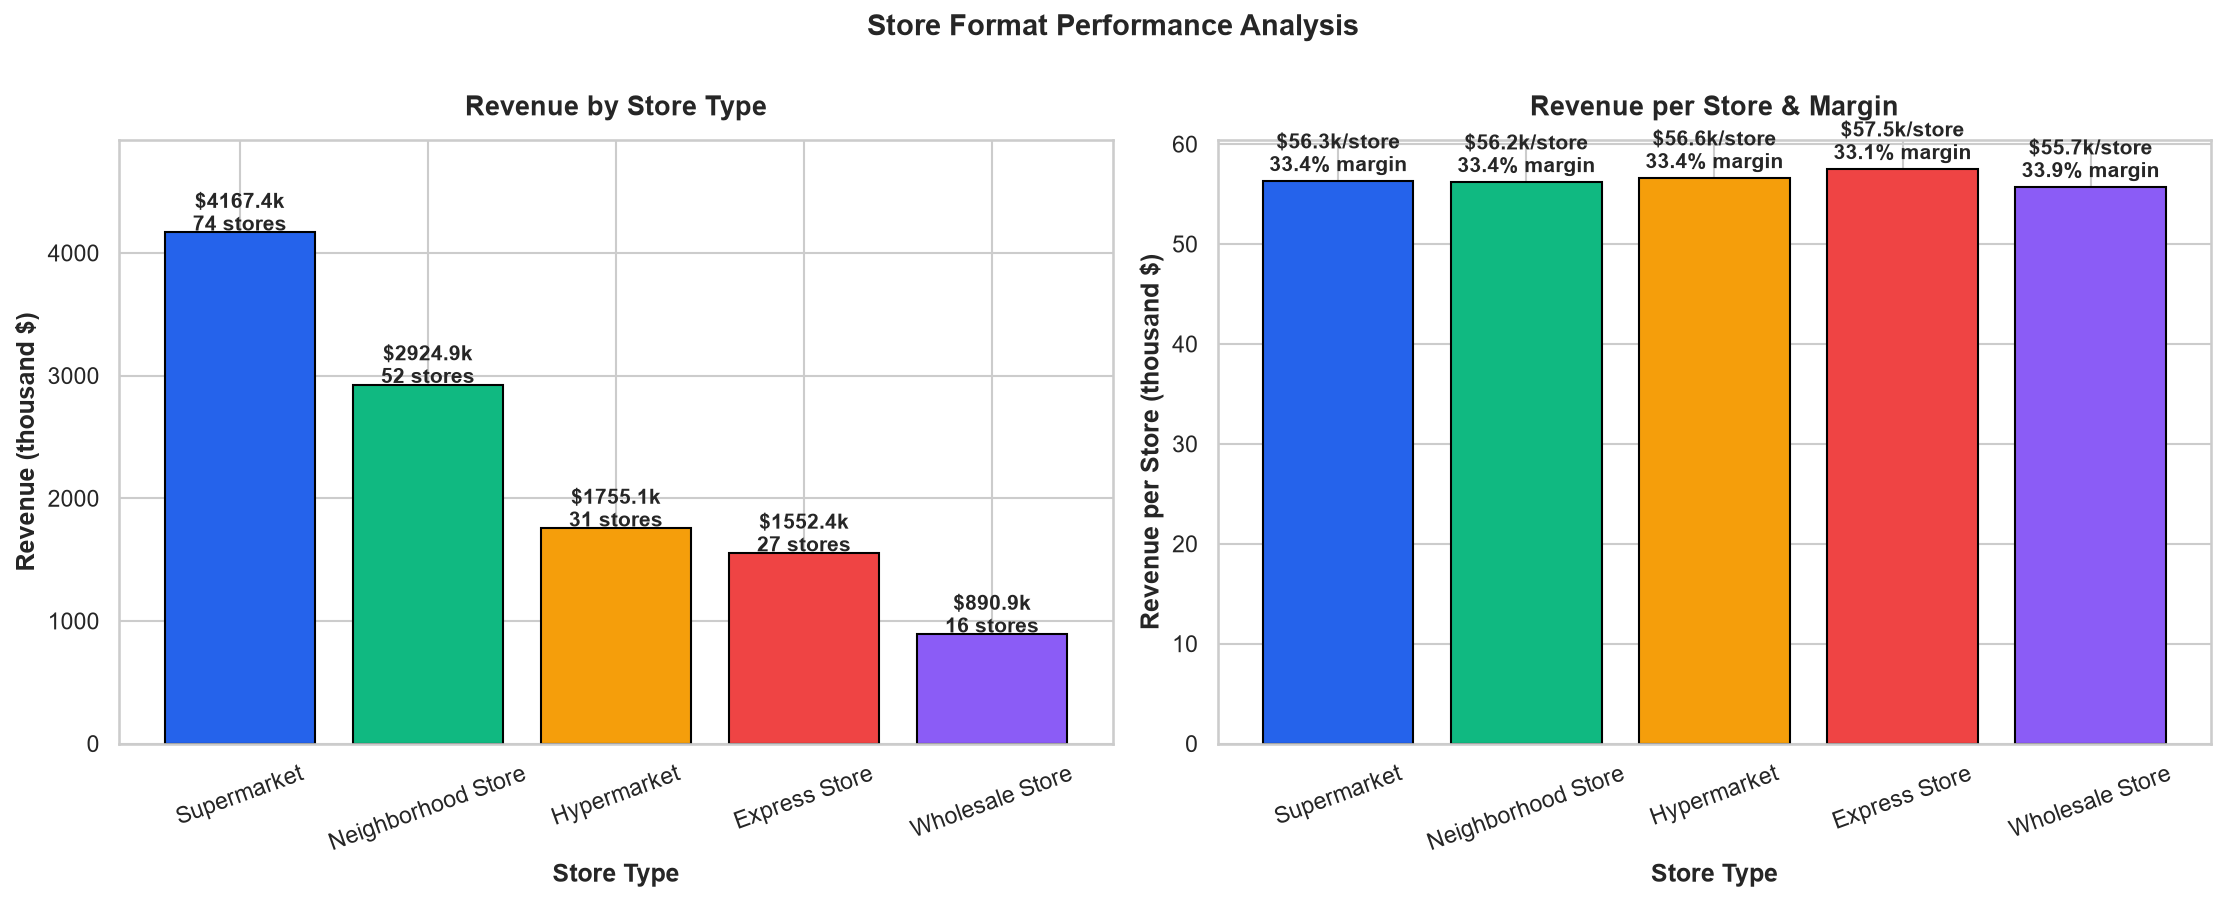

In [343]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ── Left: Revenue by store type ───────────────────────────────
axes[0].bar(
    store_df['store_type'], store_df['revenue_k'],
    color=PALETTE[:len(store_df)], edgecolor='black'
)

# Annotate bars
for i, (v, s) in enumerate(zip(store_df['revenue_k'], store_df['stores'])):
    axes[0].text(
        i, v + 15,
        f'${v:.1f}k\n{s} stores',
        ha='center', fontsize=10, fontweight='bold'
    )

axes[0].set_title('Revenue by Store Type', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Store Type', fontweight='bold')
axes[0].set_ylabel('Revenue (thousand $)', fontweight='bold')
axes[0].tick_params(axis='x', rotation=20)
axes[0].set_ylim(0, store_df['revenue_k'].max() * 1.18)

# ── Right: Revenue per store & margin ─────────────────────────
axes[1].bar(
    store_df['store_type'], store_df['rev_per_store'],
    color=PALETTE[:len(store_df)], edgecolor='black'
)

# Annotate bars
for i, (v, m) in enumerate(zip(store_df['rev_per_store'], store_df['margin'])):
    axes[1].text(
        i, v + 1,
        f'${v}k/store\n{m}% margin',
        ha='center', fontsize=10, fontweight='bold'
    )

axes[1].set_title('Revenue per Store & Margin', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Store Type', fontweight='bold')
axes[1].set_ylabel('Revenue per Store (thousand $)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)

# ── Title & layout ────────────────────────────────────────────
plt.suptitle('Store Format Performance Analysis', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()

# ── Save & show ───────────────────────────────────────────────
plt.savefig(f'charts/10_store_types.png', dpi=150, bbox_inches='tight')
plt.show()   

### 9.3 CHART 11: Seasonality & YoY

In [344]:
season_df = df.groupby('season').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index()

In [345]:
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']
season_df['season'] = pd.Categorical(season_df['season'], categories=season_order, ordered=True)
season_df = season_df.sort_values('season')
season_df['aov'] = (season_df['revenue'] / season_df['transactions']).round(2)
season_df['margin'] = (season_df['profit'] / season_df['revenue'] * 100).round(1)
season_df['revenue_k'] = season_df['revenue'] / 1000
season_df.to_csv(f'kpi/season_summary.csv', index=False)

In [346]:
# YoY pivot
yoy = df.groupby(['season', 'year']).agg(revenue=('total_amount', 'sum')).reset_index()
yoy_pivot = yoy.pivot(index='season', columns='year', values='revenue').reindex(season_order)
yoy_pivot['growth_pct'] = ((yoy_pivot[2024] - yoy_pivot[2023]) / yoy_pivot[2023] * 100).round(2)
yoy_pivot.to_csv(f'kpi/yoy_summary.csv')

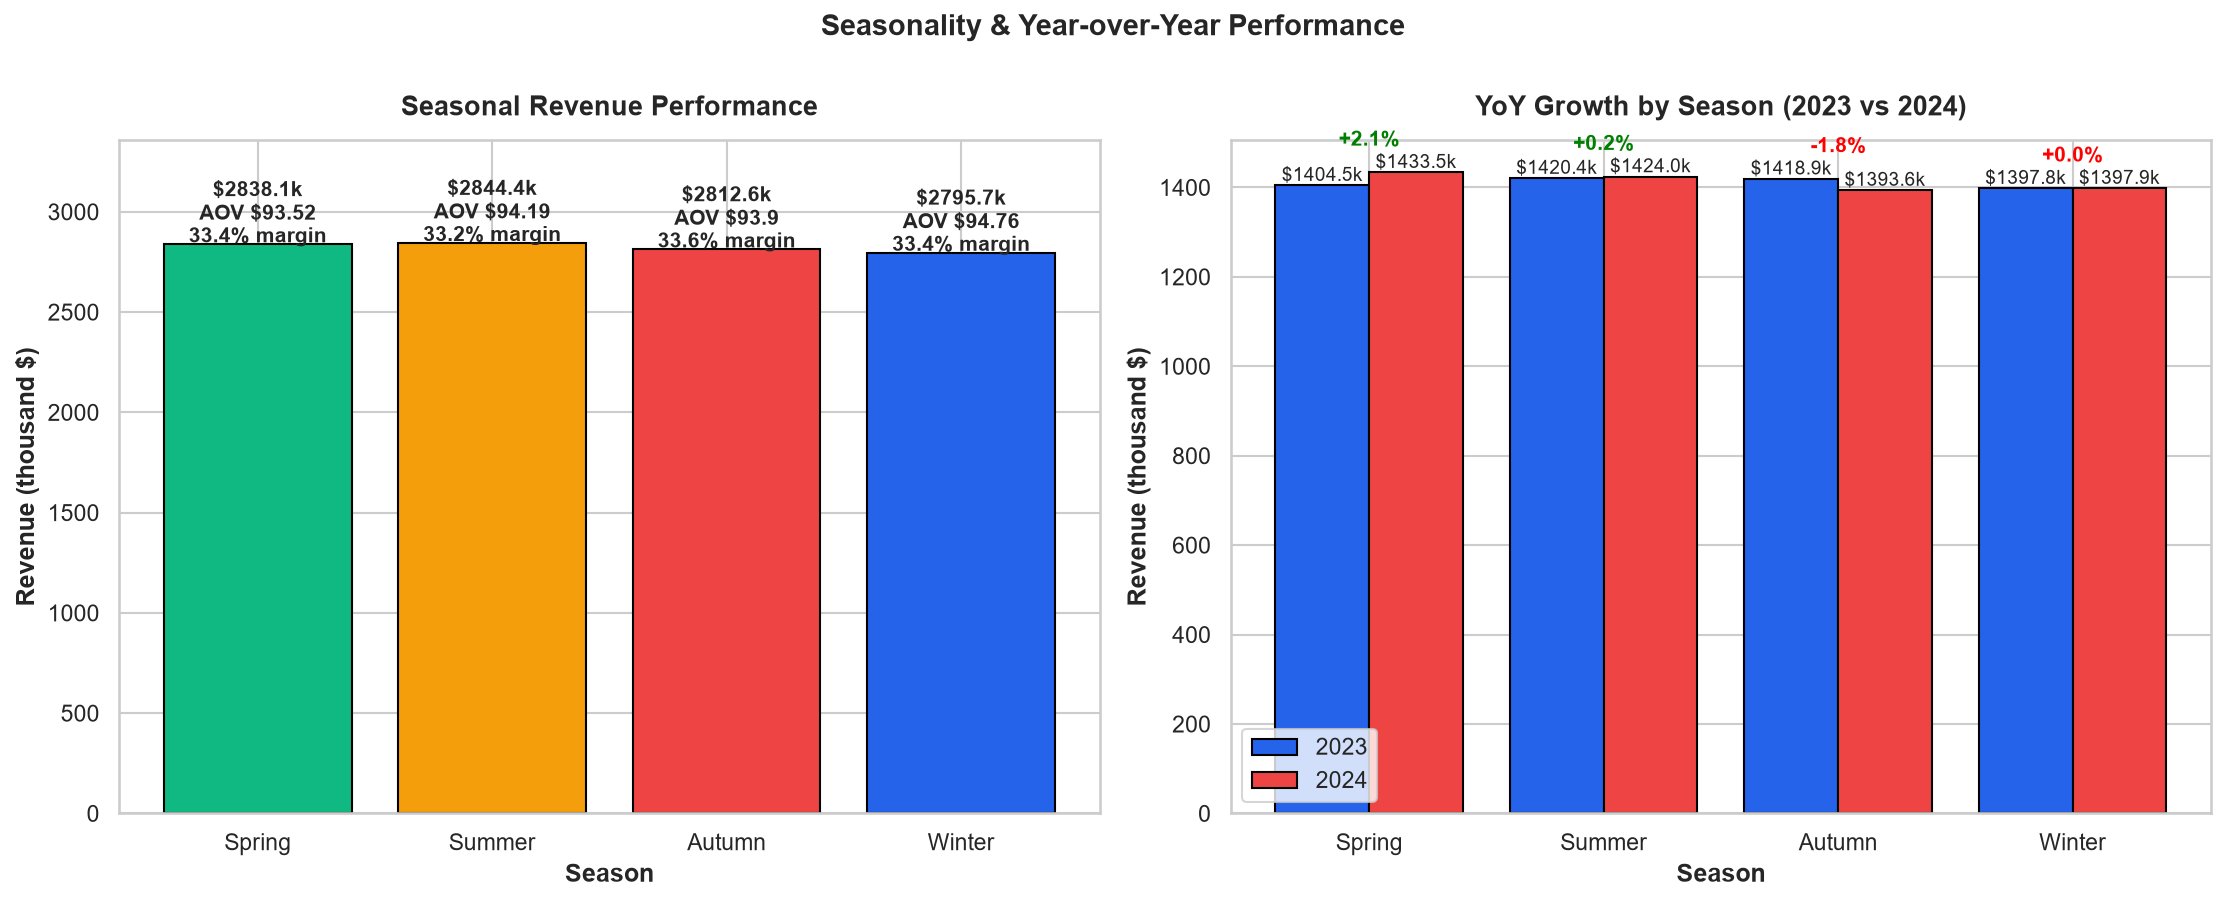

In [347]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
season_colors = ['#10B981', '#F59E0B', '#EF4444', '#2563EB']

# ── Left: Seasonal revenue performance ────────────────────────
axes[0].bar(
    season_df['season'], season_df['revenue_k'],
    color=season_colors, edgecolor='black'
)

# Annotate bars
for i, (v, a, m) in enumerate(zip(season_df['revenue_k'], season_df['aov'], season_df['margin'])):
    axes[0].text(
        i, v + 10,
        f'${v:.1f}k\nAOV ${a}\n{m}% margin',
        ha='center', fontsize=10, fontweight='bold'
    )

axes[0].set_title('Seasonal Revenue Performance', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Season', fontweight='bold')
axes[0].set_ylabel('Revenue (thousand $)', fontweight='bold')
axes[0].set_ylim(0, season_df['revenue_k'].max() * 1.18)

# ── Right: YoY growth by season (2023 vs 2024) ────────────────
x = np.arange(len(yoy_pivot))

axes[1].bar(
    x - 0.2, yoy_pivot[2023] / 1000, 0.4,
    label='2023', color=PALETTE[0], edgecolor='black'
)
axes[1].bar(
    x + 0.2, yoy_pivot[2024] / 1000, 0.4,
    label='2024', color=PALETTE[3], edgecolor='black'
)

# Annotate bars + growth %
for i, (v23, v24, g) in enumerate(
    zip(yoy_pivot[2023] / 1000, yoy_pivot[2024] / 1000, yoy_pivot['growth_pct'])
):
    axes[1].text(i - 0.2, v23 + 10, f'${v23:.1f}k', ha='center', fontsize=9)
    axes[1].text(i + 0.2, v24 + 10, f'${v24:.1f}k', ha='center', fontsize=9)
    axes[1].text(
        i, max(v23, v24) + 60,
        f'{g:+.1f}%',
        ha='center', fontsize=10, fontweight='bold',
        color='green' if g > 0 else 'red'
    )

axes[1].set_xticks(x)
axes[1].set_xticklabels(yoy_pivot.index)
axes[1].set_title('YoY Growth by Season (2023 vs 2024)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Season', fontweight='bold')
axes[1].set_ylabel('Revenue (thousand $)', fontweight='bold')
axes[1].legend()

# ── Title & layout ────────────────────────────────────────────
plt.suptitle('Seasonality & Year-over-Year Performance', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()

# ── Save & show ───────────────────────────────────────────────
plt.savefig(f'charts/11_seasonality_yoy.png', dpi=150, bbox_inches='tight')
plt.show()   

### 9.4 CHART 12: Profit Distribution by Top Categories (Boxplot) 

In [348]:
top_cats = df['product_category'].value_counts().head(8).index.tolist()
cat_margin = df[df['product_category'].isin(top_cats)].copy()
cat_margin = cat_margin[(cat_margin['gross_profit'] > -200) & (cat_margin['gross_profit'] < 400)]


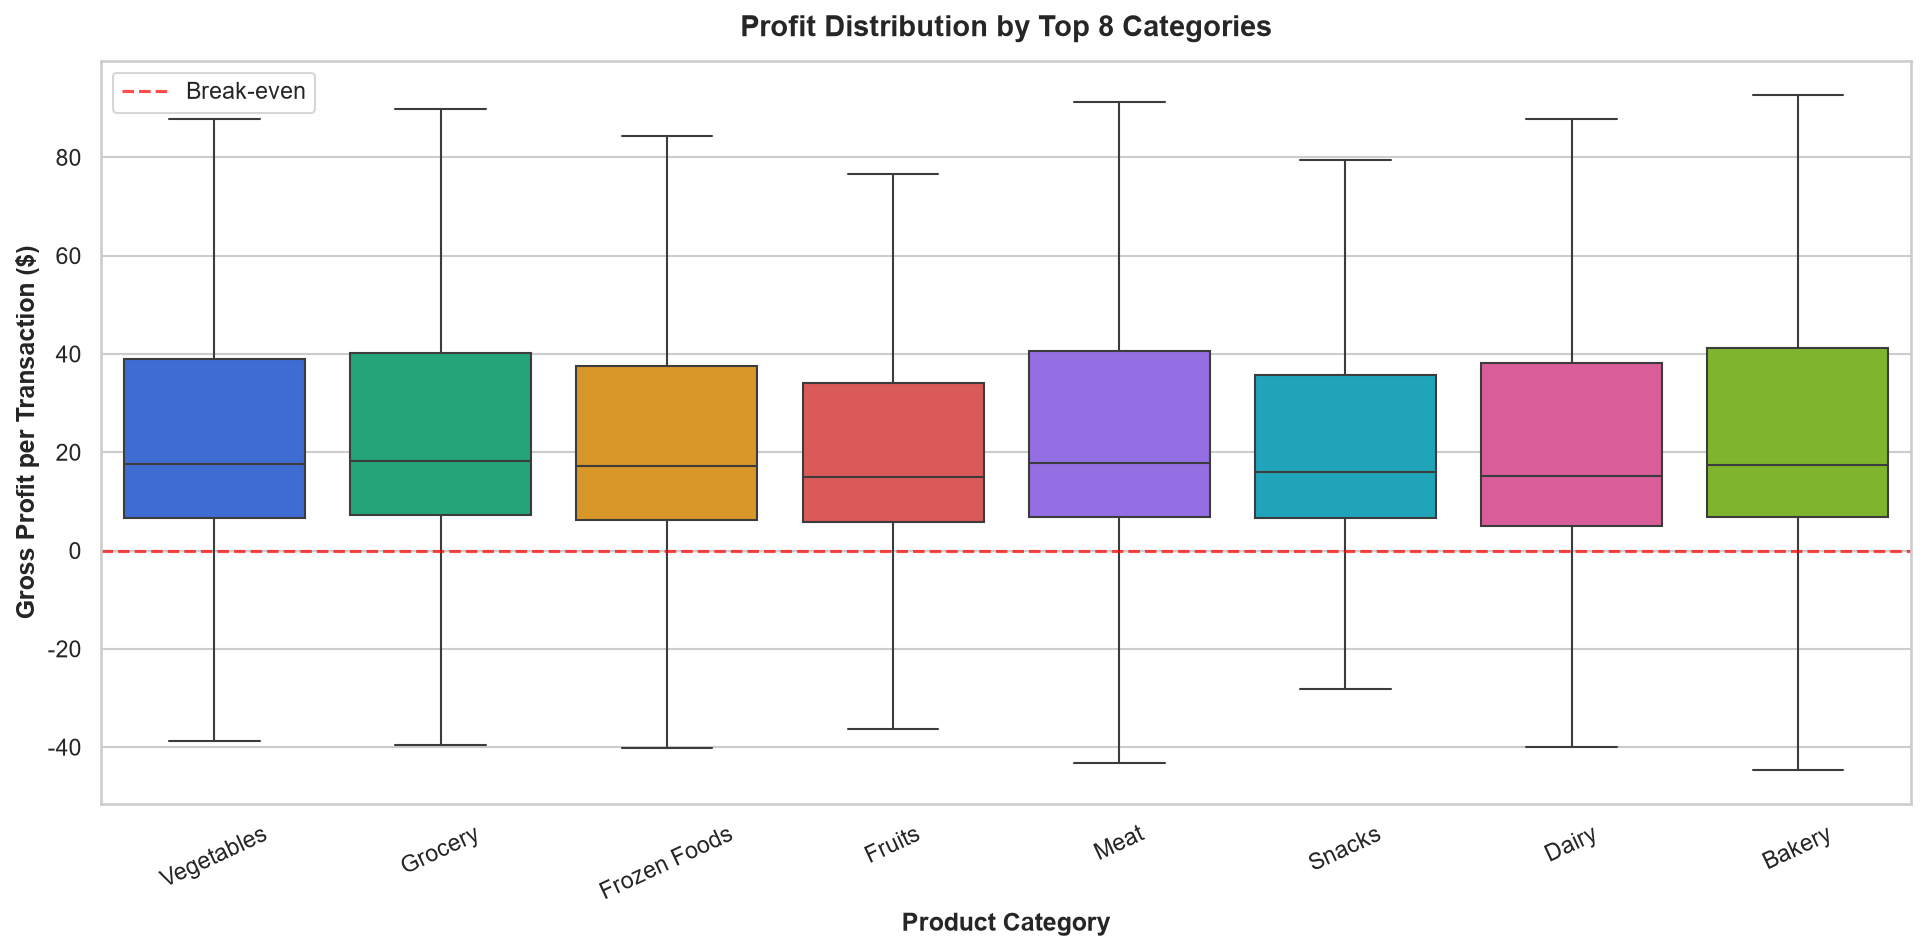

In [349]:
fig, ax = plt.subplots(figsize=(13, 6.5))

# ── Boxplot ───────────────────────────────────────────────────
sns.boxplot(
    data=cat_margin,
    x='product_category', y='gross_profit',
    palette=PALETTE, ax=ax,
    showfliers=False, hue='product_category', legend=False
)

# ── Break-even line ───────────────────────────────────────────
ax.axhline(0, color='red', linestyle='--', alpha=0.7, label='Break-even')

# ── Labels & title ────────────────────────────────────────────
ax.set_title('Profit Distribution by Top 8 Categories', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Product Category', fontweight='bold')
ax.set_ylabel('Gross Profit per Transaction ($)', fontweight='bold')
ax.tick_params(axis='x', rotation=25)
ax.legend()

# ── Layout & save ─────────────────────────────────────────────
plt.tight_layout()
plt.savefig(f'charts/12_profit_distribution.png', dpi=150, bbox_inches='tight')
plt.show()   

### 9.5 CHART 13: Discount Tier vs Margin Trade-off

In [350]:
df['discount_bin'] = pd.cut(df['discount_percent'],
                             bins=[-0.01, 0.01, 10, 20, 30, 50],
                             labels=['0%', '1-10%', '11-20%', '21-30%', '31-50%'])
disc_df = df.groupby('discount_bin', observed=True).agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique'),
    qty=('quantity', 'sum')
).reset_index()

In [351]:
disc_df['margin'] = (disc_df['profit'] / disc_df['revenue'] * 100).round(1)
disc_df['aov'] = (disc_df['revenue'] / disc_df['transactions']).round(2)
disc_df.to_csv(f'kpi/discount_summary.csv', index=False)


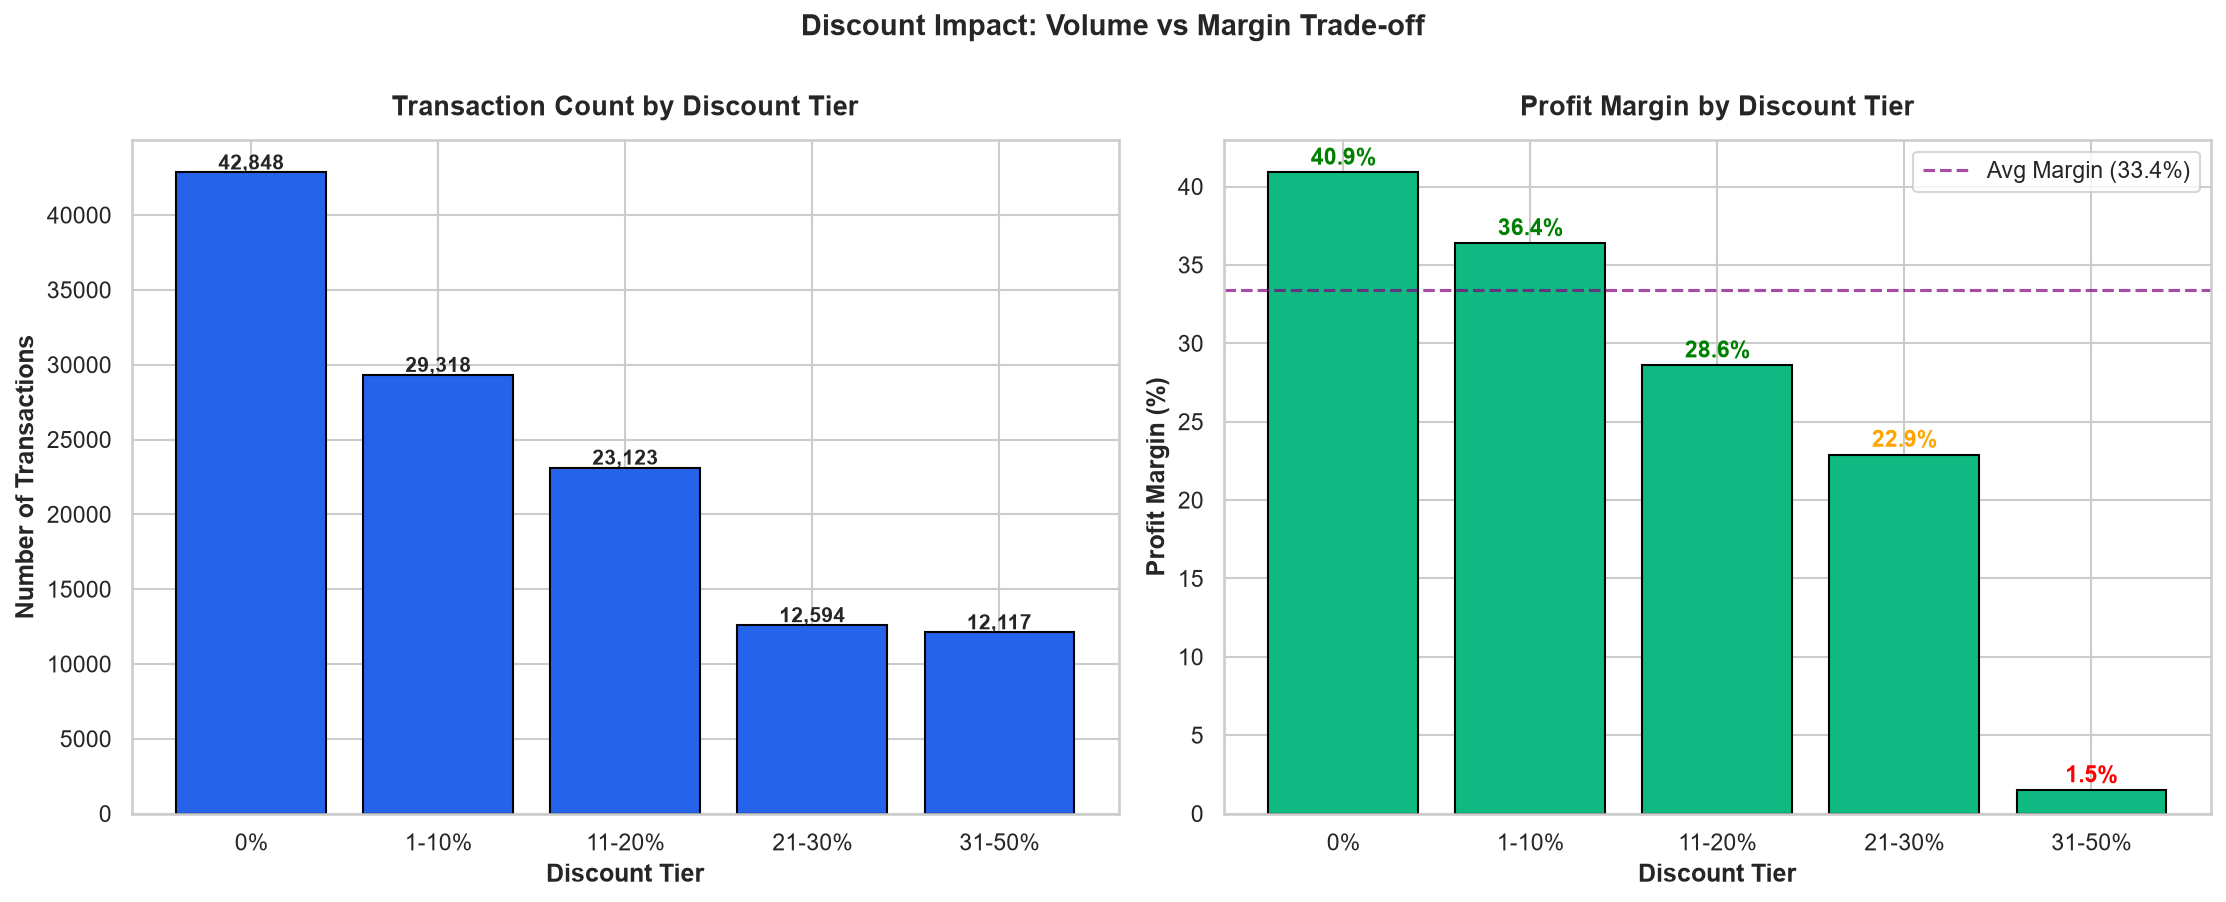

In [352]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].bar(disc_df['discount_bin'].astype(str), disc_df['transactions'],
            color=PALETTE[0], edgecolor='black')
for i, v in enumerate(disc_df['transactions']):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Transaction Count by Discount Tier', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Discount Tier', fontweight='bold')
axes[0].set_ylabel('Number of Transactions', fontweight='bold')

axes[1].bar(disc_df['discount_bin'].astype(str), disc_df['margin'],
            color=PALETTE[1], edgecolor='black')
for i, v in enumerate(disc_df['margin']):
    color = 'green' if v > 25 else 'orange' if v > 15 else 'red'
    axes[1].text(i, v + 0.5, f'{v}%', ha='center', fontsize=11, fontweight='bold', color=color)
axes[1].set_title('Profit Margin by Discount Tier', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Discount Tier', fontweight='bold')
axes[1].set_ylabel('Profit Margin (%)', fontweight='bold')
axes[1].axhline(33.39, color='purple', linestyle='--', alpha=0.7, label='Avg Margin (33.4%)')
axes[1].legend()

plt.suptitle('Discount Impact: Volume vs Margin Trade-off',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(f'charts/13_discount_impact.png', dpi=150, bbox_inches='tight')
plt.show()

In [353]:
print(disc_df[['discount_bin', 'transactions', 'revenue', 'profit', 'margin', 'aov']].to_string(index=False))

discount_bin  transactions    revenue     profit  margin    aov
          0%         42848 4687979.22 1919119.70    40.9 109.41
       1-10%         29318 2834790.89 1032508.59    36.4  96.69
      11-20%         23123 2057198.46  588340.07    28.6  88.97
      21-30%         12594  954563.38  219000.01    22.9  75.80
      31-50%         12117  756127.38   11473.46     1.5  62.40


## 🔟 Customer & Payment Deep Dive 

**What:** Two final charts:  
14. Sales Channel Mix (pie) + Customer Age Distribution (bar)  
15. Customer Satisfaction, Service Rating & Return Rate by Region (grouped bar)

**Why:** These complete the analytical picture by showing how customers engage with the business (channel preference), who they are demographically (age), and how satisfied they are with the experience across regions.

### 10.1 CHART 14: Sales Channel Mix + Customer Age Distribution

In [354]:
ch_df = df.groupby('sales_channel').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index().sort_values('revenue', ascending=False)

In [355]:
ch_df['margin'] = (ch_df['profit'] / ch_df['revenue'] * 100).round(1)
ch_df['aov'] = (ch_df['revenue'] / ch_df['transactions']).round(2)
ch_df['share'] = (ch_df['revenue'] / ch_df['revenue'].sum() * 100).round(1)
ch_df.to_csv(f'kpi/channel_summary.csv', index=False)

In [356]:
df['age_bin'] = pd.cut(df['customer_age'],
                        bins=[0, 25, 35, 45, 55, 65, 100],
                        labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

In [357]:
age_df = df.groupby('age_bin', observed=True).agg(
    revenue=('total_amount', 'sum'),
    customers=('customer_id', 'nunique'),
    txns=('transaction_id', 'nunique')
).reset_index()

In [358]:
age_df['aov'] = (age_df['revenue'] / age_df['txns']).round(2)
age_df['revenue_k'] = age_df['revenue'] / 1000
age_df.to_csv(f'kpi/age_summary.csv', index=False)

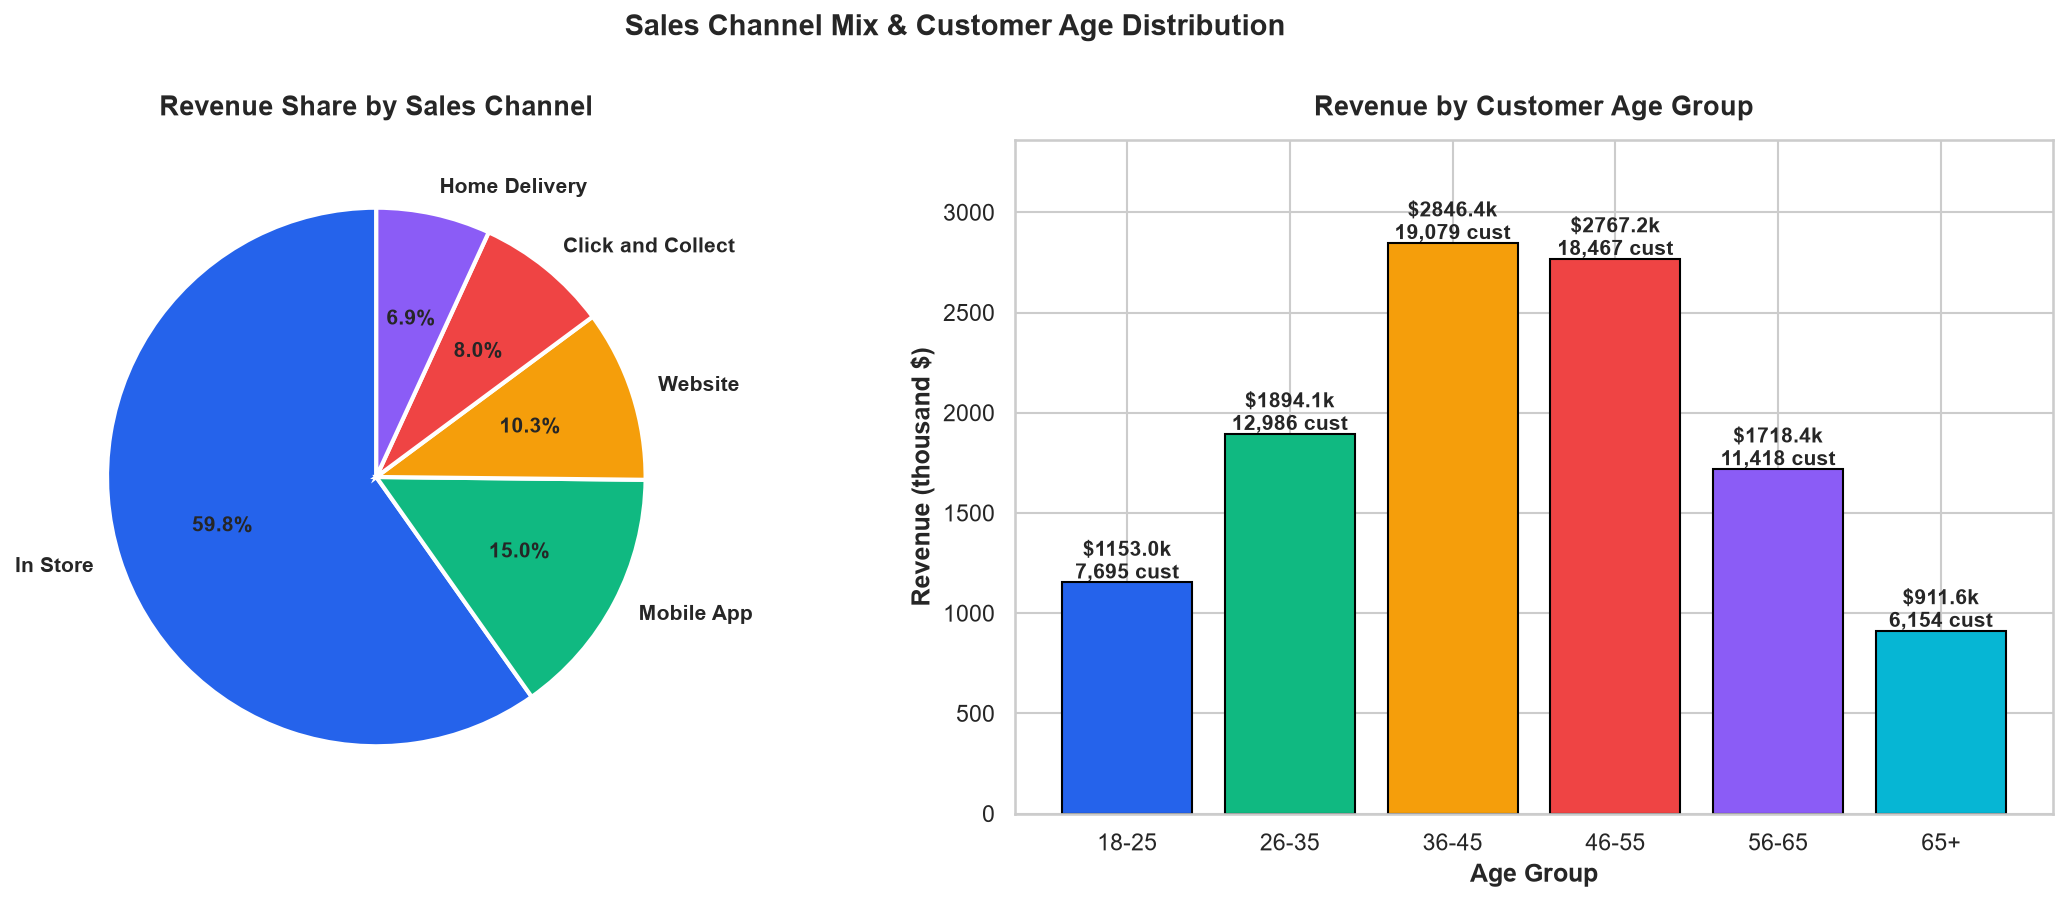

In [359]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors_ch = PALETTE[:len(ch_df)]

# ── Left: Revenue share by sales channel (pie) ───────────────
axes[0].pie(
    ch_df['revenue'],
    labels=ch_df['sales_channel'],
    colors=colors_ch,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops=dict(fontsize=10, fontweight='bold')
)
axes[0].set_title('Revenue Share by Sales Channel', fontsize=13, fontweight='bold', pad=12)

# ── Right: Revenue by customer age group ─────────────────────
bars = axes[1].bar(
    age_df['age_bin'].astype(str), age_df['revenue_k'],
    color=PALETTE[:len(age_df)], edgecolor='black'
)

# Annotate bars
for i, (v, c) in enumerate(zip(age_df['revenue_k'], age_df['customers'])):
    axes[1].text(
        i, v + 20,
        f'${v:.1f}k\n{c:,} cust',
        ha='center', fontsize=10, fontweight='bold'
    )

axes[1].set_title('Revenue by Customer Age Group', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Age Group', fontweight='bold')
axes[1].set_ylabel('Revenue (thousand $)', fontweight='bold')
axes[1].set_ylim(0, age_df['revenue_k'].max() * 1.18)

# ── Title & layout ────────────────────────────────────────────
plt.suptitle(
    'Sales Channel Mix & Customer Age Distribution',
    fontsize=14, fontweight='bold', y=1.00
)
plt.tight_layout()

# ── Save & show ───────────────────────────────────────────────
plt.savefig(f'charts/14_channel_age.png', dpi=150, bbox_inches='tight')
plt.show()   

### 10.2 CHART 15: Satisfaction & Service by Region

In [360]:
sat_df = df.groupby('store_region').agg(
    satisfaction=('customer_satisfaction_score', 'mean'),
    service_rating=('service_rating', 'mean'),
    revenue=('total_amount', 'sum'),
    return_rate=('return_flag', lambda x: (x.fillna('No') == 'Yes').mean() * 100)
).reset_index()

In [361]:
sat_df['satisfaction'] = sat_df['satisfaction'].round(2)
sat_df['service_rating'] = sat_df['service_rating'].round(2)
sat_df.to_csv(f'kpi/satisfaction_summary.csv', index=False)


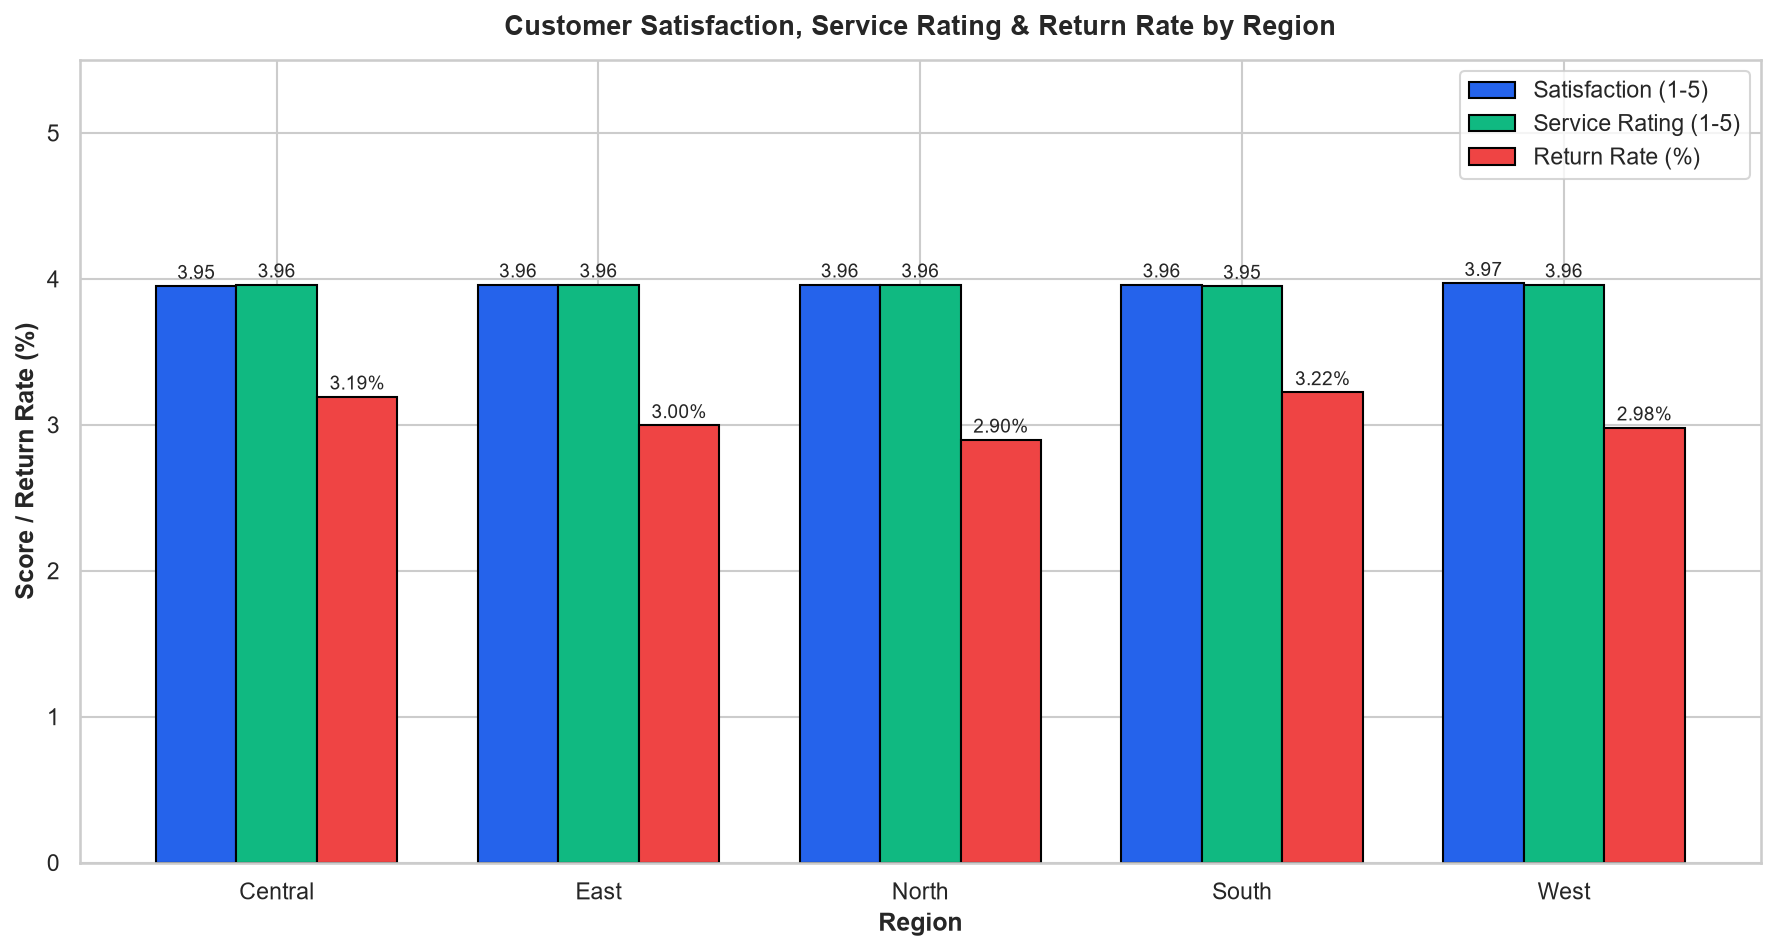

In [362]:
fig, ax1 = plt.subplots(figsize=(12, 6.5))
x = np.arange(len(sat_df))
width = 0.25

# ── Grouped bars ──────────────────────────────────────────────
ax1.bar(
    x - width, sat_df['satisfaction'], width,
    label='Satisfaction (1-5)', color=PALETTE[0], edgecolor='black'
)
ax1.bar(
    x, sat_df['service_rating'], width,
    label='Service Rating (1-5)', color=PALETTE[1], edgecolor='black'
)
ax1.bar(
    x + width, sat_df['return_rate'], width,
    label='Return Rate (%)', color=PALETTE[3], edgecolor='black'
)

# ── Labels & title ────────────────────────────────────────────
ax1.set_xticks(x)
ax1.set_xticklabels(sat_df['store_region'])
ax1.set_xlabel('Region', fontweight='bold')
ax1.set_ylabel('Score / Return Rate (%)', fontweight='bold')
ax1.set_title(
    'Customer Satisfaction, Service Rating & Return Rate by Region',
    fontsize=13, fontweight='bold', pad=12
)
ax1.legend(loc='upper right')
ax1.set_ylim(0, 5.5)

# ── Annotate bars ─────────────────────────────────────────────
for i, (s, sv, r) in enumerate(
    zip(sat_df['satisfaction'], sat_df['service_rating'], sat_df['return_rate'])
):
    ax1.text(i - width, s + 0.05, f'{s}', ha='center', fontsize=9)
    ax1.text(i, sv + 0.05, f'{sv}', ha='center', fontsize=9)
    ax1.text(i + width, r + 0.05, f'{r:.2f}%', ha='center', fontsize=9)

# ── Layout & save ─────────────────────────────────────────────
plt.tight_layout()
plt.savefig(f'charts/15_satisfaction_region.png', dpi=150, bbox_inches='tight')
plt.show()   

In [363]:
print(sat_df.to_string(index=False))

store_region  satisfaction  service_rating    revenue  return_rate
     Central          3.95            3.96 2012845.72     3.192029
        East          3.96            3.96 2834337.93     2.995706
       North          3.96            3.96 2025522.96     2.896469
       South          3.96            3.95 2515477.81     3.221926
        West          3.97            3.96 1902474.91     2.979951


## 1️⃣1️⃣ Additional Aggregations for the Report

**What:** Compute supporting tables that will be referenced in the Word report appendix:  
- Yearly summary (2023 vs 2024)  
- Top 10 products by revenue  
- Gender analysis  
- Holiday impact  
- Weekend vs weekday  
- Customer repeat-purchase statistics  

**Why:** These aggregations provide the granular evidence behind the high-level KPIs.  
**How:** Group-by with multiple aggregations.

### 11.1 Yearly summary

In [364]:
yearly = df.groupby(df['transaction_date'].dt.year).agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique'),
    customers=('customer_id', 'nunique')
).reset_index()

In [365]:
yearly['margin'] = (yearly['profit'] / yearly['revenue'] * 100).round(2)
yearly['aov'] = (yearly['revenue'] / yearly['transactions']).round(2)
yearly.to_csv(f'kpi/yearly_summary.csv', index=False)

In [366]:
print(yearly.to_string(index=False))

 transaction_date    revenue     profit  transactions  customers  margin   aov
             2023 5641662.10 1883425.60         60045      47199   33.38 93.96
             2024 5648997.23 1887016.23         59955      47258   33.40 94.22


### 11.2 Top 10 products by revenue

In [368]:
top_products = df.groupby(['product_name', 'product_category']).agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    qty=('quantity', 'sum'),
    transactions=('transaction_id', 'nunique')
).reset_index().sort_values('revenue', ascending=False).head(10)

In [369]:
top_products['margin'] = (top_products['profit'] / top_products['revenue'] * 100).round(1)
top_products['aov'] = (top_products['revenue'] / top_products['transactions']).round(2)
top_products.to_csv(f'kpi/top_products.csv', index=False)

In [370]:
print(f'\n Top 10 products by revenue:')
print(top_products.to_string(index=False))


 Top 10 products by revenue:
product_name product_category  revenue   profit  qty  transactions  margin     aov
Product_3015           Coffee 28800.69  2526.59  223            26     8.8 1107.72
Product_3712        First Aid 27347.43 14722.44  237            29    53.8  943.01
Product_2410         Cleaning 25105.24 10400.52  268            27    41.4  929.82
Product_1599         Pet Toys 21601.49 12102.13  257            26    56.0  830.83
 Product_983          Seafood 21001.40 10897.68  204            25    51.9  840.06
Product_2605          Diapers 19987.50   848.16  342            36     4.2  555.21
Product_1279           Juices 19924.49  3149.25  221            23    15.8  866.28
 Product_967        First Aid 19510.70  6857.50  395            37    35.1  527.32
Product_2133      Supplements 19020.70  9690.75  225            24    50.9  792.53
Product_3608  Office Supplies 18906.97  9665.77  257            35    51.1  540.20


### 11.3 Gender analysis

In [371]:
gender_df = df.groupby('customer_gender').agg(
    revenue=('total_amount', 'sum'),
    profit=('gross_profit', 'sum'),
    transactions=('transaction_id', 'nunique'),
    customers=('customer_id', 'nunique')
).reset_index()

In [372]:
gender_df['aov'] = (gender_df['revenue'] / gender_df['transactions']).round(2)
gender_df['margin'] = (gender_df['profit'] / gender_df['revenue'] * 100).round(1)
gender_df.to_csv(f'kpi/gender_summary.csv', index=False)

In [373]:
print(gender_df.to_string(index=False))

customer_gender    revenue     profit  transactions  customers   aov  margin
         Female 5452303.83 1818423.91         57647      36443 94.58    33.4
           Male 5391225.43 1800700.80         57440      36282 93.86    33.4
          Other  447130.07  151317.12          4913       3074 91.01    33.8


### 11.4 Holiday impact

In [374]:
df['is_holiday_str'] = df['is_holiday'].astype(str)
holiday_df = df.groupby('is_holiday_str').agg(
    revenue=('total_amount', 'sum'),
    txns=('transaction_id', 'nunique')
).reset_index()

In [376]:
holiday_df['aov'] = (holiday_df['revenue'] / holiday_df['txns']).round(2)
holiday_df['share'] = (holiday_df['revenue'] / holiday_df['revenue'].sum() * 100).round(1)
holiday_df.to_csv(f'kpi/holiday_summary.csv', index=False)


In [377]:
print(f'\n🎉 Holiday impact:')
print(holiday_df.to_string(index=False))


🎉 Holiday impact:
is_holiday_str     revenue   txns   aov  share
            No 10377225.84 110385 94.01   91.9
           Yes   913433.49   9615 95.00    8.1


### 11.5 Weekend vs weekday

In [378]:
wknd = df.groupby('is_weekend_calc').agg(
    revenue=('total_amount', 'sum'),
    txns=('transaction_id', 'nunique')
).reset_index()

In [379]:
wknd['aov'] = (wknd['revenue'] / wknd['txns']).round(2)
wknd.to_csv(f'kpi/weekend_summary.csv', index=False)

In [380]:
print(f'\n📅 Weekend vs weekday:')
print(wknd.to_string(index=False))


📅 Weekend vs weekday:
 is_weekend_calc    revenue  txns   aov
           False 8077609.82 85752 94.20
            True 3213049.51 34248 93.82


### 11.6 Customer repeat-purchase stats

In [381]:
cust_freq = df.groupby('customer_id').agg(
    txns=('transaction_id', 'nunique'),
    revenue=('total_amount', 'sum')
).reset_index()

In [382]:
repeat_pct = (cust_freq['txns'] > 1).mean() * 100

In [383]:
print(f'\n👥 Customer repeat-purchase:')
print(f'   Customers with >1 txn: {(cust_freq["txns"] > 1).sum():,} ({repeat_pct:.1f}%)')
print(f'   Customers with 1 txn:  {(cust_freq["txns"] == 1).sum():,} ({100 - repeat_pct:.1f}%)')
print(f'   Max txns by one customer: {cust_freq["txns"].max()}')
print(f'   Avg txns per customer: {cust_freq["txns"].mean():.2f}')



👥 Customer repeat-purchase:
   Customers with >1 txn: 31,804 (42.0%)
   Customers with 1 txn:  43,995 (58.0%)
   Max txns by one customer: 8
   Avg txns per customer: 1.58


## ✅ Project Summary

You have now run a complete, end-to-end data analysis project from raw Kaggle data to a formatted Word report.



### What was accomplished:

| Step | Output |
|------|--------|
| 1. Setup | Imported all libraries, created directory structure |
| 2. Data Loading | Downloaded 197MB  CSV from Kaggle, loaded 102 columns |
| 3. Exploration | 120,000 transactions × 2 years × 5 regions × 200 stores |
| 4. Quality Checks | 0 duplicates, 7 columns with missing values (mostly expected) |
| 5. Cleaning | Datetime conversion, transparent missing-value handling |
| 6. KPIs | $11.29M revenue, $3.77M profit, 33.4% margin, $94.09 AOV |
| 7-10. Visualizations | 15 publication-ready PNG charts saved to `charts/` |
| 11. Aggregations | 8 supporting CSV summaries saved to `kpi/` |
| 12. Report | 1.6MB Word document with cover, TOC, 10 sections, 15 charts, 13 tables |


### Key Findings:

1. **Stable but flat YoY growth** (+0.13% revenue, +0.19% profit)
2. **East region dominates** with 25.1% of revenue (49% above West)
3. **Aggressive discounting destroys margin** (31-50% tier earns only 1.5%)
4. **Digital channels = 40.2% of revenue** (Mobile App > Website by 46%)
5. **Loyalty program healthy & margin-neutral** (all tiers 33.3-33.5% margin)
6. **Card payments dominate** (55.1% combined) but cash still matters (19.8%)
7. **Satisfaction 3.96/5** — room for improvement vs 4.5+ benchmark

### Top 5 Recommendations:

| Priority | Recommendation | Expected Impact |
|----------|----------------|-----------------|
| P1 Critical | Cap max discount at 30%, require VP approval for deeper markdowns | +3-5 pts margin (~$340k-$565k annual profit) |
| P1 Critical | Invest in West region: 5-10 new stores + localized marketing | Close 50% of revenue gap vs East (~$465k) |
| P2 High | Launch tier-upgrade campaign (Bronze→Silver, Silver→Gold) | +$3-5 AOV per migrated customer (~$200k-$350k) |
| P2 High | Optimize staffing for 11AM-2PM & 5PM-8PM peak windows | -15-20% queue times, +0.2-0.4 satisfaction |
| P3 Medium | Cross-merchandise high-margin Stationery & Electronics with staples | +0.5-1.0 pt basket margin (~$55k-$110k) |